# Предсказание победителя матча Dota 2 на разных стадиях игры

**Тема 32.** Предсказание победителя киберспортивного матча: feature engineering из игровой статистики (KDA, gold, objectives), сравнение классических моделей и MLP, анализ того, какие признаки наиболее предсказательны на разных стадиях матча.

**Датасет:** [Dota 2 Matches (Kaggle)](https://www.kaggle.com/datasets/devinanzelmo/dota-2-matches) — 50 000 рейтинговых матчей из дампа OpenDota.

**Постановка задачи.** Бинарная классификация: по выбранным героям и состоянию игры на 10-й, 20-й и 30-й минуте предсказать, победит ли команда Radiant (`radiant_win`).

**Главное правило проекта:** в признаки попадает только то, что уже известно к выбранной минуте. Итоговая статистика матча (например, финальный KDA) в модель не идёт — это была бы утечка данных.

## Содержание
1. Загрузка и описание данных
2. Предобработка и сборка признаков по стадиям
3. EDA
4. Feature engineering
5. Классические модели: подбор гиперпараметров и кросс-валидация
6. Нейронная сеть MLP (PyTorch)
7. Stacking и Blending
8. Сравнение моделей
9. Разные стадии матча
10. Важность признаков по стадиям
11. Дополнительные исследования: ablation, анализ ошибок, утечка, матчи с вышедшими игроками
12. Выводы

In [1]:
import os
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import sklearn
import torch
import warnings
warnings.filterwarnings('ignore', category=FutureWarning)   # скрываем только сообщения о будущих изменениях библиотек
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 11

RANDOM_STATE = 42
DATA_DIR = 'data/'          # сюда нужно положить csv-файлы датасета

# цвета: у каждой команды и у каждой стадии матча свой цвет на всех графиках
C_RAD, C_DIRE, C_MAIN = '#1baf7a', '#eb6834', '#2a78d6'
STAGE_COLORS = {10: '#86b6ef', 20: '#2a78d6', 30: '#104281'}

os.makedirs('figures', exist_ok=True)   # графики для отчёта
os.makedirs('results', exist_ok=True)   # итоговые таблицы

print('Версии: pandas', pd.__version__, '| numpy', np.__version__, '| scikit-learn', sklearn.__version__,
      '| torch', torch.__version__)

Версии: pandas 3.0.5 | numpy 2.5.3 | scikit-learn 1.9.1 | torch 2.15.0+cu132


## 1. Загрузка и описание данных

Из датасета используем шесть таблиц:

| Файл | Что в нём |
|---|---|
| `match.csv` | общая информация о матче и целевая переменная `radiant_win` |
| `players.csv` | итоговая статистика каждого из 10 игроков (герой, убийства, смерти, золото в минуту) |
| `player_time.csv` | золото, опыт и добивания каждого игрока по минутам |
| `objectives.csv` | события: башни, бараки, Рошан, первая кровь — со временем |
| `teamfights.csv` | командные драки: начало, конец, число смертей |
| `teamfights_players.csv` | что произошло с каждым игроком в каждой драке: смерти, урон, изменение золота, выкупы |

In [2]:
match = pd.read_csv(DATA_DIR + 'match.csv')
players = pd.read_csv(DATA_DIR + 'players.csv',
                      usecols=['match_id', 'hero_id', 'player_slot', 'kills', 'deaths', 'assists',
                               'gold_per_min', 'xp_per_min', 'last_hits', 'leaver_status'])
player_time = pd.read_csv(DATA_DIR + 'player_time.csv')
objectives = pd.read_csv(DATA_DIR + 'objectives.csv')
teamfights = pd.read_csv(DATA_DIR + 'teamfights.csv')
teamfights_players = pd.read_csv(DATA_DIR + 'teamfights_players.csv')

tables = {'match': match, 'players': players, 'player_time': player_time,
          'objectives': objectives, 'teamfights': teamfights, 'teamfights_players': teamfights_players}
for name, table in tables.items():
    print(f'{name:18s} {table.shape[0]:>9,} строк, {table.shape[1]:>2} столбцов')

match                 50,000 строк, 13 столбцов
players              500,000 строк, 10 столбцов
player_time        2,209,778 строк, 32 столбцов
objectives         1,173,396 строк,  9 столбцов
teamfights           539,047 строк,  5 столбцов
teamfights_players 5,390,470 строк,  8 столбцов


In [3]:
match.head()

,match_id,start_time,duration,tower_status_radiant,tower_status_dire,barracks_status_dire,barracks_status_radiant,first_blood_time,game_mode,radiant_win,negative_votes,positive_votes,cluster
0,0,1446750112,2375,1982,4,3,63,1,22,True,0,1,155
1,1,1446753078,2582,0,1846,63,0,221,22,False,0,2,154
2,2,1446764586,2716,256,1972,63,48,190,22,False,0,0,132
3,3,1446765723,3085,4,1924,51,3,40,22,False,0,0,191
4,4,1446796385,1887,2047,0,0,63,58,22,True,0,0,156


In [4]:
match.info()

<class 'pandas.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 13 columns):
 #   Column                   Non-Null Count  Dtype
---  ------                   --------------  -----
 0   match_id                 50000 non-null  int64
 1   start_time               50000 non-null  int64
 2   duration                 50000 non-null  int64
 3   tower_status_radiant     50000 non-null  int64
 4   tower_status_dire        50000 non-null  int64
 5   barracks_status_dire     50000 non-null  int64
 6   barracks_status_radiant  50000 non-null  int64
 7   first_blood_time         50000 non-null  int64
 8   game_mode                50000 non-null  int64
 9   radiant_win              50000 non-null  bool 
 10  negative_votes           50000 non-null  int64
 11  positive_votes           50000 non-null  int64
 12  cluster                  50000 non-null  int64
dtypes: bool(1), int64(12)
memory usage: 4.6 MB


In [5]:
# Целевая переменная и период данных
print('Доля побед Radiant:', round(match['radiant_win'].mean(), 4))
print('Период:', pd.to_datetime(match['start_time'].min(), unit='s').date(), '-',
      pd.to_datetime(match['start_time'].max(), unit='s').date())
print('Режимы игры (game_mode):', match['game_mode'].value_counts().to_dict())
print('Длительность, мин:', (match['duration'] / 60).describe().round(1).to_dict())

Доля побед Radiant: 0.5189
Период: 2015-11-05 - 2015-11-18
Режимы игры (game_mode): {22: 48670, 2: 1330}
Длительность, мин: {'count': 50000.0, 'mean': 41.3, 'std': 10.6, 'min': 1.0, '25%': 33.8, '50%': 40.2, '75%': 47.9, 'max': 267.3}


In [6]:
# Как устроены остальные таблицы
display(player_time.head(3))
display(objectives.head(5))
display(teamfights.head(3))
display(teamfights_players.head(3))

,match_id,times,gold_t_0,lh_t_0,xp_t_0,gold_t_1,lh_t_1,xp_t_1,gold_t_2,lh_t_2,...,xp_t_129,gold_t_130,lh_t_130,xp_t_130,gold_t_131,lh_t_131,xp_t_131,gold_t_132,lh_t_132,xp_t_132
0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,60,409,0,63,142,1,186,168,0,...,62,345,6,351,100,0,77,613,1,125
2,0,120,546,0,283,622,4,645,330,0,...,543,684,12,805,200,0,210,815,5,323


,match_id,key,player1,player2,slot,subtype,team,time,value
0,0,NaN,0,6,0.0,CHAT_MESSAGE_FIRSTBLOOD,NaN,1,309
1,0,NaN,3,-1,3.0,CHAT_MESSAGE_TOWER_KILL,2.0,894,2
2,0,NaN,2,-1,NaN,CHAT_MESSAGE_ROSHAN_KILL,2.0,925,200
3,0,NaN,1,-1,1.0,CHAT_MESSAGE_AEGIS,NaN,925,0
4,0,NaN,7,-1,7.0,CHAT_MESSAGE_TOWER_KILL,3.0,1016,3


,match_id,start,end,last_death,deaths
0,0,220,252,237,3
1,0,429,475,460,3
2,0,900,936,921,3


,match_id,player_slot,buybacks,damage,deaths,gold_delta,xp_end,xp_start
0,0,0,0,105,0,173,536,314
1,0,1,0,566,1,0,1583,1418
2,0,2,0,0,0,0,391,391


**Описание датасета.**

- 50 000 рейтинговых матчей за две недели, с 5 по 18 ноября 2015 года. Почти все сыграны в режиме 22 (Ranked All Pick), 1 330 матчей — в режиме 2 (Captains Mode).
- **Целевая переменная** — `radiant_win` (победа Radiant). Классы почти сбалансированы: Radiant выигрывает в 51,9% матчей, поэтому accuracy здесь осмысленна, а точка отсчёта для неё — 51,9%.
- Средний матч длится 41 минуту, но есть и очень короткие, и очень длинные матчи.
- Типы данных: в исходных таблицах почти всё числовое (счётчики и суммы). Категориальные по смыслу — герой (`hero_id`), режим игры (`game_mode`) и тип события (`subtype`).
- `player_time` хранит накопленные значения: `gold_t_0` — сколько золота игрок в слоте 0 заработал к этой минуте. Слоты 0–4 — Radiant, 128–132 — Dire.
- `teamfights_players` — по 10 строк на каждую драку из `teamfights` (по одной на игрока): смерти, урон, изменение золота и выкупы в этой драке.

## 2. Предобработка и сборка признаков по стадиям

### 2.1 Пропуски в исходных таблицах

In [7]:
for name, table in tables.items():
    na = table.isna().mean()
    na = na[na > 0].round(3)
    print(f'{name:18s}', 'пропусков нет' if na.empty else na.to_dict())

# пропуск может быть записан и нулём: герой с номером 0 не существует
print('Строк в players без героя (hero_id = 0):', (players['hero_id'] == 0).sum())

match              пропусков нет
players            пропусков нет
player_time        пропусков нет
objectives         {'key': 0.77, 'slot': 0.295, 'team': 0.336}
teamfights         пропусков нет
teamfights_players пропусков нет


Строк в players без героя (hero_id = 0): 37


**Что с пропусками.**

- В `match`, `players`, `player_time`, `teamfights` и `teamfights_players` пропусков нет.
- В `objectives` пропуски структурные: поле просто не относится к данному типу события (у башни нет `key`, у барака нет `team`). Удалять или заполнять их не нужно — мы берём из каждого типа события только его собственные поля.
- Настоящие пропуски появятся при сборке признаков: если до нужной минуты событий не было, счётчик пуст. Такой пропуск означает ноль, им и заполняем.
- У 37 строк в `players` не записан герой (`hero_id = 0`), а у 2,5% матчей в логе нет события первой крови. Для героя пропуск просто не кодируется, для первой крови заводим отдельную категорию `unknown`.

### 2.2 Отбор матчей

В части матчей кто-то из игроков покинул игру (`leaver_status >= 2`). Дальше команды играют в неравных составах. Это другой тип матчей, поэтому мы их убираем и строим модель для матчей без выходов.

Важная оговорка: статус игрока известен только после конца матча, то есть на 20-й минуте мы не знаем, выйдет ли кто-то позже. Фильтр применён и к train, и к test, поэтому все метрики ниже относятся к матчам без выходов. Как модель ведёт себя на убранных матчах, проверено в разделе 11.4.

In [8]:
# максимальный статус выхода среди 10 игроков матча: 0-1 всё в порядке, 2 и больше - игрок покинул игру
leaver_max = players.groupby('match_id')['leaver_status'].max()
print('Матчей, где игрок покинул игру:', (leaver_max >= 2).sum(), f'({(leaver_max >= 2).mean():.1%})')

good_ids = leaver_max[leaver_max < 2].index
match_clean = match[match['match_id'].isin(good_ids)].copy()
match_clean['radiant_win'] = match_clean['radiant_win'].astype(int)
print('Матчей до очистки:', len(match), '-> после:', len(match_clean))

Матчей, где игрок покинул игру: 4626 (9.3%)
Матчей до очистки: 50000 -> после: 45374


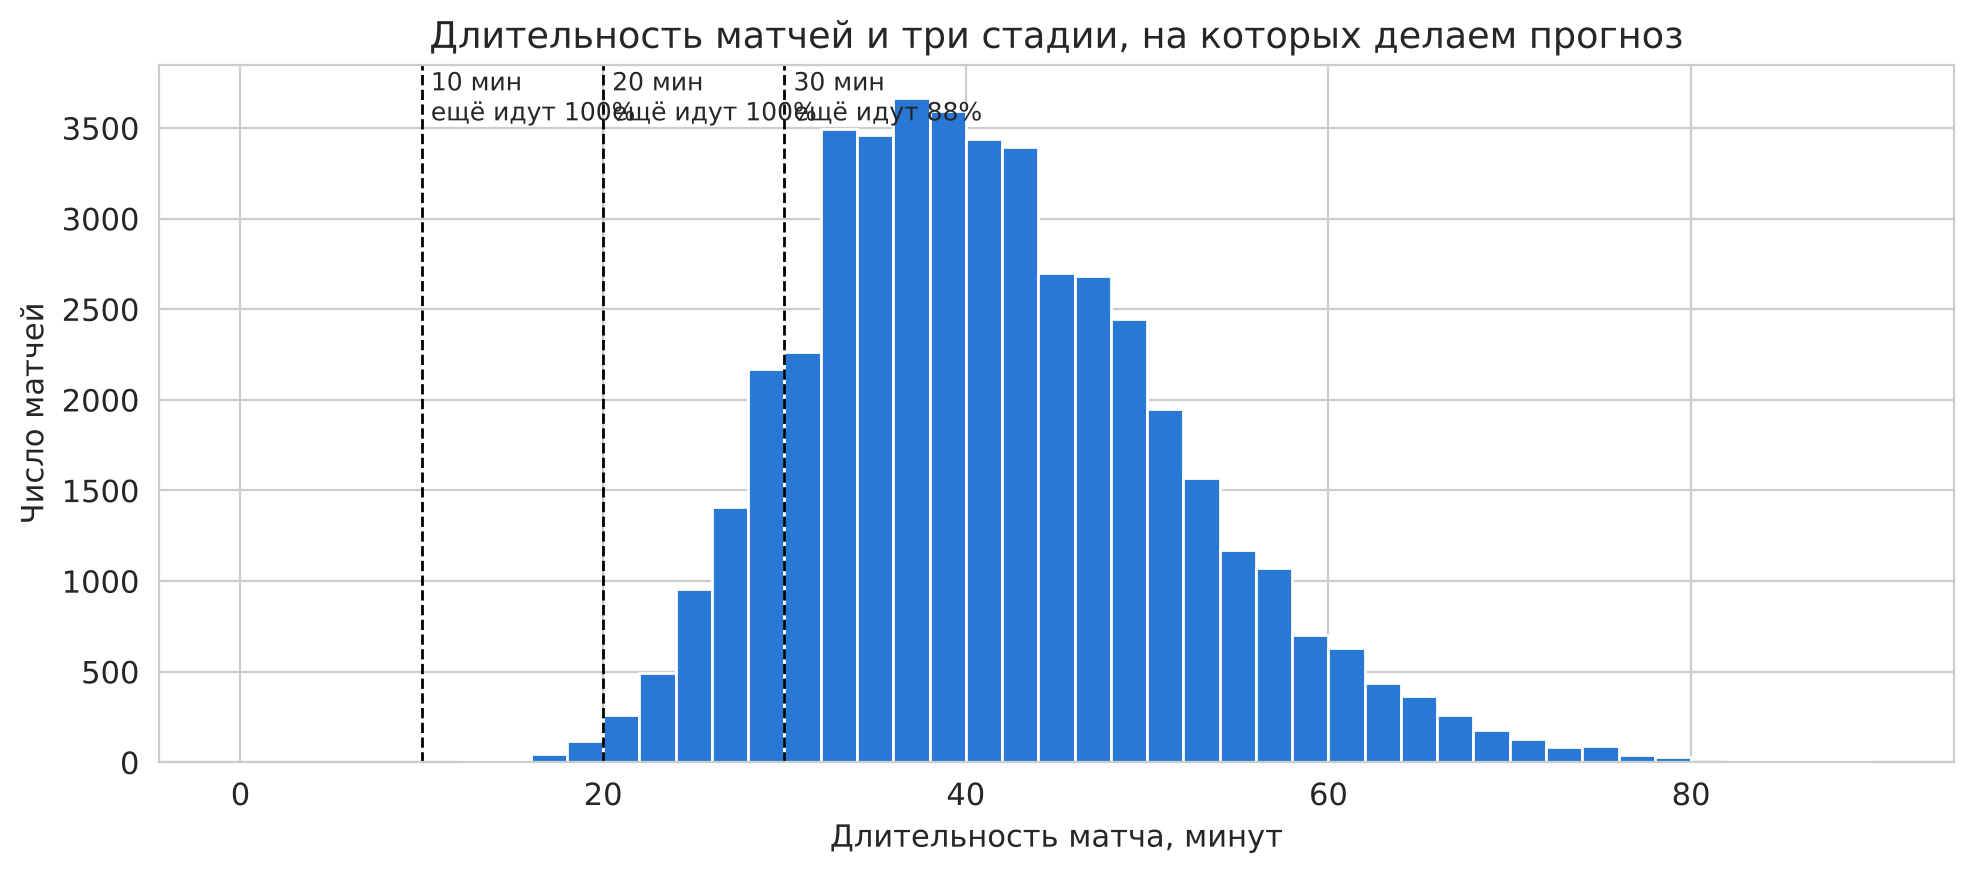

In [9]:
# Длительность матчей и выбранные стадии
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.hist(match_clean['duration'] / 60, bins=np.arange(0, 91, 2), color=C_MAIN, edgecolor='white')
for minute in [10, 20, 30]:
    ax.axvline(minute, color='black', linestyle='--', linewidth=1)
    share = (match_clean['duration'] > minute * 60).mean()
    ax.text(minute + 0.5, ax.get_ylim()[1] * 0.92, f'{minute} мин\nещё идут {share:.0%}', fontsize=9)
ax.set_xlabel('Длительность матча, минут')
ax.set_ylabel('Число матчей')
ax.set_title('Длительность матчей и три стадии, на которых делаем прогноз')
plt.tight_layout()
plt.savefig('figures/duration.png', dpi=150)
plt.show()

### 2.3 Сборка таблицы признаков

Для минуты `T` берём одну строку на матч. Все признаки считаются только по событиям **до** минуты `T`:

- **экономика** — из `player_time` на минуте `T` (золото, опыт, добивания);
- **объекты** — из `objectives` со временем `<= T` (башни, бараки, Рошан, первая кровь);
- **драки и убийства** — из `teamfights` и `teamfights_players`: только драки, закончившиеся до минуты `T`;
- **драфт** — выбранные герои из `players` (известны ещё до начала матча).

В таблицу для минуты `T` попадают только матчи, которые к этой минуте ещё не закончились.

В `objectives` не подписано, какая команда стоит за числами в полях `team`, `key` и `player1`. Предположение: `team == 2` — событие в пользу Radiant, `team == 3` — в пользу Dire; `key <= 32` — разрушены бараки Dire; `player1 < 5` — игрок Radiant. Проверяем его в следующей ячейке по итоговому состоянию матча.

In [10]:
# Проверка смысла полей objectives по итогам матча из таблицы match
def count_bits(x):
    """Число единиц в двоичной записи: в tower_status и barracks_status каждый бит - уцелевшее здание."""
    return bin(int(x)).count('1')


check = match.set_index('match_id')[['tower_status_dire', 'barracks_status_dire', 'radiant_win']].copy()
check['dire_towers_lost'] = 11 - check['tower_status_dire'].map(count_bits)        # у команды 11 башен
check['dire_barracks_lost'] = 6 - check['barracks_status_dire'].map(count_bits)    # и 6 бараков

towers_all = objectives[objectives['subtype'] == 'CHAT_MESSAGE_TOWER_KILL']
barracks_all = objectives[objectives['subtype'] == 'CHAT_MESSAGE_BARRACKS_KILL']
check['team2_tower_kills'] = towers_all[towers_all['team'] == 2].groupby('match_id').size()
check['low_key_barracks'] = barracks_all[barracks_all['key'] <= 32].groupby('match_id').size()
check = check.fillna(0)

print('Корреляция: башни с team == 2 и потерянные башни Dire:',
      round(check['team2_tower_kills'].corr(check['dire_towers_lost']), 3))
print('Корреляция: бараки с key <= 32 и потерянные бараки Dire:',
      round(check['low_key_barracks'].corr(check['dire_barracks_lost']), 3))

fb_all = objectives[objectives['subtype'] == 'CHAT_MESSAGE_FIRSTBLOOD'].merge(match[['match_id', 'radiant_win']], on='match_id')
print(f"Доля побед Radiant: первая кровь у player1 < 5 - {fb_all.loc[fb_all['player1'] < 5, 'radiant_win'].mean():.1%}, "
      f"у player1 >= 5 - {fb_all.loc[fb_all['player1'] >= 5, 'radiant_win'].mean():.1%}")

Корреляция: башни с team == 2 и потерянные башни Dire: 0.986
Корреляция: бараки с key <= 32 и потерянные бараки Dire: 1.0
Доля побед Radiant: первая кровь у player1 < 5 - 57.3%, у player1 >= 5 - 46.5%


Предположение подтвердилось: число башен с `team == 2` почти точно совпадает с числом башен, потерянных Dire (корреляция 0,986), бараки с `key <= 32` — это бараки Dire (корреляция 1,0), а когда первую кровь делает игрок с номером меньше 5, Radiant побеждает чаще (57,3% против 46,5%).

**Убийства по командам (K и D из KDA).** В `teamfights_players` на каждую драку из `teamfights` идут подряд 10 строк — по одной на игрока, отдельного номера драки нет. Нумеруем драки по порядку строк и проверяем, что таблицы действительно совпадают. Смерть игрока одной команды считаем убийством для другой.

In [11]:
teamfights_players['fight_id'] = np.arange(len(teamfights_players)) // 10      # 10 строк подряд = одна драка
teamfights_players['is_radiant'] = teamfights_players['player_slot'] < 5

# проверка: драка с номером i в teamfights_players - это строка i в teamfights
first_match = teamfights_players.groupby('fight_id')['match_id'].first().values
print('Номера матчей совпадают во всех драках:', (first_match == teamfights['match_id'].values).all())

# суммы по каждой команде в каждой драке
team_sum = teamfights_players.groupby(['fight_id', 'is_radiant'])[['deaths', 'gold_delta', 'damage', 'buybacks']].sum()
rad = team_sum.xs(True, level='is_radiant')      # показатели Radiant
dire = team_sum.xs(False, level='is_radiant')    # показатели Dire
print(f"Сумма смертей игроков совпадает с teamfights.deaths в {((rad['deaths'] + dire['deaths']).values == teamfights['deaths'].values).mean():.1%} драк")

fights = teamfights[['match_id', 'end', 'deaths']].copy()
fights['kills_diff'] = dire['deaths'].values - rad['deaths'].values                  # убийства Radiant минус убийства Dire
fights['fight_gold_diff'] = rad['gold_delta'].values - dire['gold_delta'].values     # кто больше заработал в драке
fights['fight_damage_diff'] = rad['damage'].values - dire['damage'].values           # кто нанёс больше урона
fights['buyback_diff'] = rad['buybacks'].values - dire['buybacks'].values            # кто чаще выкупался

# в остальных драках сумма по игрокам больше: смотрим, на сколько
extra = (rad['deaths'] + dire['deaths']).values - teamfights['deaths'].values
print('Расхождение (сумма по игрокам минус teamfights.deaths):', pd.Series(extra).value_counts().sort_index().to_dict())

# какая часть всех смертей матча приходится на командные драки
print(f"Командные драки покрывают {teamfights['deaths'].sum() / players['deaths'].sum():.1%} всех смертей героев за весь матч")

# в начале игры покрытие ниже: первые убийства обычно одиночные, а драка - это бой с тремя и более смертями
first_fight_end = teamfights.groupby('match_id')['end'].min()
fb_time = match.set_index('match_id')['first_blood_time']
print(f"Первая кровь происходит раньше конца первой командной драки в {(fb_time < first_fight_end.reindex(fb_time.index)).mean():.1%} матчей")
for minute in [10, 20, 30]:
    mean_deaths = teamfights[teamfights['end'] <= minute * 60]['deaths'].sum() / len(match)
    print(f'К {minute}-й минуте в драках в среднем {mean_deaths:.1f} смертей на матч')
fights.head()

Номера матчей совпадают во всех драках: True


Сумма смертей игроков совпадает с teamfights.deaths в 95.3% драк
Расхождение (сумма по игрокам минус teamfights.deaths): {-1: 1, 0: 513559, 1: 24241, 2: 1122, 3: 56, 4: 20, 5: 44, 6: 4}
Командные драки покрывают 60.7% всех смертей героев за весь матч
Первая кровь происходит раньше конца первой командной драки в 99.9% матчей
К 10-й минуте в драках в среднем 3.7 смертей на матч
К 20-й минуте в драках в среднем 15.1 смертей на матч
К 30-й минуте в драках в среднем 28.2 смертей на матч


,match_id,end,deaths,kills_diff,fight_gold_diff,fight_damage_diff,buyback_diff
0,0,252,3,1,-158,2,0
1,0,475,3,3,1584,608,0
2,0,936,3,3,3651,1113,0
3,0,1328,3,3,1984,2067,0
4,0,1666,5,1,-396,-3258,0


**Что показывает проверка.**

- Таблицы совпадают по порядку строк: номер матча одинаков во всех драках.
- В 95,3% драк сумма смертей по игрокам равна `teamfights.deaths`. В остальных 4,7% сумма по игрокам больше, почти всегда на 1. Причину по самим данным установить нельзя; вероятно, один игрок погиб в драке дважды (например, после выкупа), а в `teamfights.deaths` он посчитан один раз. Мы используем суммы по игрокам, потому что только в них есть разбивка по командам.
- **Это не полный счёт убийств.** Командная драка в датасете — бой с тремя и более смертями. За весь матч на такие драки приходится 60,7% смертей героев, а в начале игры — заметно меньше: первая кровь в 99,9% матчей случается раньше, чем заканчивается первая драка, и к 10-й минуте в драках набирается в среднем всего 3,7 смерти на матч. Поэтому `kills_diff` на 10-й минуте описывает убийства хуже, чем на 20-й и 30-й.

In [12]:
RAD_SLOTS = [0, 1, 2, 3, 4]               # номера игроков Radiant в player_time
DIRE_SLOTS = [128, 129, 130, 131, 132]    # номера игроков Dire


def team_cols(prefix, slots):
    """Названия столбцов одной команды, например gold_t_0 ... gold_t_4."""
    return [f'{prefix}_t_{s}' for s in slots]


def build_stage(minute, matches=None):
    """Таблица признаков на заданной минуте матча: одна строка = один матч.
    matches - таблица матчей, для которых считаем признаки (по умолчанию очищенные match_clean)."""
    matches = match_clean if matches is None else matches
    t = minute * 60
    snap = player_time[player_time['times'] == t].set_index('match_id')        # состояние на минуте T
    prev = player_time[player_time['times'] == t - 300].set_index('match_id')  # состояние 5 минут назад

    gold_r, gold_d = snap[team_cols('gold', RAD_SLOTS)], snap[team_cols('gold', DIRE_SLOTS)]
    xp_r, xp_d = snap[team_cols('xp', RAD_SLOTS)], snap[team_cols('xp', DIRE_SLOTS)]
    lh_r, lh_d = snap[team_cols('lh', RAD_SLOTS)], snap[team_cols('lh', DIRE_SLOTS)]

    df = pd.DataFrame(index=snap.index)

    # --- экономика ---
    df['gold_diff'] = gold_r.sum(axis=1) - gold_d.sum(axis=1)       # перевес Radiant по золоту
    df['xp_diff'] = xp_r.sum(axis=1) - xp_d.sum(axis=1)             # перевес по опыту
    df['lh_diff'] = lh_r.sum(axis=1) - lh_d.sum(axis=1)             # перевес по добиваниям
    df['gold_total'] = gold_r.sum(axis=1) + gold_d.sum(axis=1)      # общий темп игры
    prev_gold_diff = (prev[team_cols('gold', RAD_SLOTS)].sum(axis=1)
                      - prev[team_cols('gold', DIRE_SLOTS)].sum(axis=1))
    df['gold_diff_5min'] = df['gold_diff'] - prev_gold_diff         # как изменился перевес за 5 минут
    df['top_gold_diff'] = gold_r.max(axis=1) - gold_d.max(axis=1)   # разница между самыми богатыми героями
    df['low_gold_diff'] = gold_r.min(axis=1) - gold_d.min(axis=1)   # разница между самыми бедными героями

    # --- объекты (только события до минуты T) ---
    obj = objectives[objectives['time'] <= t]
    towers = obj[obj['subtype'] == 'CHAT_MESSAGE_TOWER_KILL']
    roshan = obj[obj['subtype'] == 'CHAT_MESSAGE_ROSHAN_KILL']
    barracks = obj[obj['subtype'] == 'CHAT_MESSAGE_BARRACKS_KILL']
    first_blood = obj[obj['subtype'] == 'CHAT_MESSAGE_FIRSTBLOOD'].set_index('match_id')

    df['towers_r'] = towers[towers['team'] == 2].groupby('match_id').size()
    df['towers_d'] = towers[towers['team'] == 3].groupby('match_id').size()
    df['roshan_r'] = roshan[roshan['team'] == 2].groupby('match_id').size()
    df['roshan_d'] = roshan[roshan['team'] == 3].groupby('match_id').size()
    df['barracks_r'] = barracks[barracks['key'] <= 32].groupby('match_id').size()
    df['barracks_d'] = barracks[barracks['key'] >= 64].groupby('match_id').size()
    df['fb_player'] = first_blood['player1']

    # --- командные драки, закончившиеся до минуты T ---
    past_fights = fights[fights['end'] <= t].groupby('match_id')
    df['n_teamfights'] = past_fights.size()
    df['teamfight_deaths'] = past_fights['deaths'].sum()
    fight_cols = ['kills_diff', 'fight_gold_diff', 'fight_damage_diff', 'buyback_diff']
    for col in fight_cols:
        df[col] = past_fights[col].sum()

    # пропуск в счётчике = событий не было -> 0
    count_cols = ['towers_r', 'towers_d', 'roshan_r', 'roshan_d', 'barracks_r', 'barracks_d',
                  'n_teamfights', 'teamfight_deaths'] + fight_cols
    df[count_cols] = df[count_cols].fillna(0)

    df['tower_diff'] = df['towers_r'] - df['towers_d']
    df['towers_total'] = df['towers_r'] + df['towers_d']
    df['roshan_diff'] = df['roshan_r'] - df['roshan_d']
    df['barracks_diff'] = df['barracks_r'] - df['barracks_d']

    # первая кровь - категориальный признак; если события в логе нет, отдельная категория unknown
    df['first_blood'] = np.where(df['fb_player'].isna(), 'unknown',
                                 np.where(df['fb_player'] < 5, 'radiant', 'dire'))

    df = df.drop(columns=['towers_r', 'towers_d', 'roshan_r', 'roshan_d', 'barracks_r', 'barracks_d', 'fb_player'])

    # добавляем режим игры и цель; duration нужна только для фильтра и анализа ошибок, в признаки не идёт
    df = df.join(matches.set_index('match_id')[['game_mode', 'duration', 'radiant_win']], how='inner')
    df = df[df['duration'] > t]          # матч ещё идёт на минуте T
    return df.reset_index()

In [13]:
# Драфт: герой - категориальный признак со 110 значениями. Кодируем one-hot отдельно для каждой команды:
# столбец r_hero_5 = 1, если герой 5 играет за Radiant, d_hero_5 = 1, если за Dire
heroes = players[players['hero_id'] > 0].copy()        # hero_id = 0 - герой не записан (пропуск), таких строк 37
heroes['col'] = np.where(heroes['player_slot'] < 5, 'r_hero_', 'd_hero_') + heroes['hero_id'].astype(str)
draft = pd.crosstab(heroes['match_id'], heroes['col'])
hero_features = list(draft.columns)
print('Разных героев:', heroes['hero_id'].nunique(), '| столбцов драфта:', len(hero_features))


def add_draft(table):
    """Добавляет к таблице признаков столбцы драфта."""
    table = table.join(draft, on='match_id')
    table[hero_features] = table[hero_features].fillna(0).astype(int)
    return table


STAGES = [10, 20, 30]
stages = {minute: add_draft(build_stage(minute)) for minute in STAGES}

for minute, table in stages.items():
    print(f'{minute} минута: {table.shape[0]} матчей, {table.shape[1]} столбцов, '
          f'доля побед Radiant {table["radiant_win"].mean():.3f}, пропусков {table.isna().sum().sum()}')

Разных героев: 110 | столбцов драфта: 220


10 минута: 45373 матчей, 242 столбцов, доля побед Radiant 0.519, пропусков 0
20 минута: 45186 матчей, 242 столбцов, доля побед Radiant 0.519, пропусков 0
30 минута: 39878 матчей, 242 столбцов, доля побед Radiant 0.506, пропусков 0


In [14]:
num_features = ['gold_diff', 'xp_diff', 'lh_diff', 'gold_total', 'gold_diff_5min', 'top_gold_diff', 'low_gold_diff',
                'tower_diff', 'towers_total', 'roshan_diff', 'barracks_diff',
                'kills_diff', 'fight_gold_diff', 'fight_damage_diff', 'buyback_diff', 'n_teamfights', 'teamfight_deaths']
cat_features = ['first_blood', 'game_mode']
game_features = num_features + cat_features          # признаки, которые появляются по ходу игры
features = game_features + hero_features             # полный набор: игра + драфт
target = 'radiant_win'
print('Числовых:', len(num_features), '| категориальных:', len(cat_features), '| столбцов драфта:', len(hero_features),
      '| всего:', len(features))

stages[20][['match_id'] + game_features + hero_features[:3] + [target]].head()

Числовых: 17 | категориальных: 2 | столбцов драфта: 220 | всего: 239


,match_id,gold_diff,xp_diff,lh_diff,gold_total,gold_diff_5min,top_gold_diff,low_gold_diff,tower_diff,towers_total,...,fight_damage_diff,buyback_diff,n_teamfights,teamfight_deaths,first_blood,game_mode,d_hero_1,d_hero_10,d_hero_100,radiant_win
0,0,3397,6653,-39,66163,2690.0,-468,2251,1.0,3.0,...,1723.0,0.0,3.0,9.0,radiant,22,0,0,0,1
1,1,736,2617,-18,74934,929.0,-15,-594,1.0,3.0,...,-92.0,0.0,6.0,24.0,radiant,22,0,0,0,0
2,2,985,1185,37,56105,-50.0,11,-41,1.0,3.0,...,1023.0,0.0,5.0,19.0,dire,22,0,1,0,0
3,3,954,1529,25,58168,-1510.0,-370,562,0.0,4.0,...,-2972.0,0.0,4.0,19.0,dire,22,0,0,0,0
4,4,14466,11827,227,67898,7499.0,3337,80,5.0,5.0,...,4953.0,0.0,2.0,8.0,radiant,22,0,0,1,1


### 2.4 Разбиение на train и test

Делим **матчи** на обучающую (80%) и тестовую (20%) части один раз и используем это разбиение на всех стадиях. Тест откладываем до финального сравнения: EDA, подбор гиперпараметров и кросс-валидация идут только на train.

In [15]:
from sklearn.model_selection import train_test_split

train_ids, test_ids = train_test_split(match_clean['match_id'], test_size=0.2, random_state=RANDOM_STATE,
                                       stratify=match_clean['radiant_win'])
train_ids, test_ids = set(train_ids), set(test_ids)


def get_split(minute, cols=None):
    """X_train, y_train, X_test, y_test для выбранной минуты."""
    cols = cols or features
    table = stages[minute]
    train = table[table['match_id'].isin(train_ids)]
    test = table[table['match_id'].isin(test_ids)]
    return train[cols], train[target], test[cols], test[target]


MAIN_STAGE = 20     # основная стадия: на ней подбираем гиперпараметры и подробно сравниваем модели
X_train, y_train, X_test, y_test = get_split(MAIN_STAGE)
print(f'Train: {X_train.shape}, Test: {X_test.shape}')
print(f'Доля побед Radiant: train {y_train.mean():.3f}, test {y_test.mean():.3f}')

Train: (36146, 239), Test: (9040, 239)
Доля побед Radiant: train 0.519, test 0.519


## 3. EDA

EDA по признакам делаем на обучающей части, основная стадия — 20-я минута.

In [16]:
train_df = stages[MAIN_STAGE][stages[MAIN_STAGE]['match_id'].isin(train_ids)].copy()
train_df['Победитель'] = train_df[target].map({1: 'Radiant', 0: 'Dire'})

print('Размер:', train_df[features].shape)
print()
print('Типы признаков:')
print(train_df[game_features].dtypes.astype(str).to_string())
print(f'+ {len(hero_features)} бинарных столбцов драфта (0/1)')
train_df[num_features].describe().T.round(1)

Размер: (36146, 239)

Типы признаков:
gold_diff              int64
xp_diff                int64
lh_diff                int64
gold_total             int64
gold_diff_5min       float64
top_gold_diff          int64
low_gold_diff          int64
tower_diff           float64
towers_total         float64
roshan_diff          float64
barracks_diff        float64
kills_diff           float64
fight_gold_diff      float64
fight_damage_diff    float64
buyback_diff         float64
n_teamfights         float64
teamfight_deaths     float64
first_blood              str
game_mode              int64
+ 220 бинарных столбцов драфта (0/1)


,count,mean,std,min,25%,50%,75%,max
gold_diff,36146.0,368.2,6934.2,-41678.0,-3638.8,315.0,4364.8,38532.0
xp_diff,36146.0,124.2,6952.1,-28491.0,-4371.8,144.5,4622.0,29794.0
lh_diff,36146.0,0.7,71.7,-313.0,-46.0,1.0,49.0,323.0
gold_total,36146.0,63476.8,5739.5,42882.0,59572.0,63304.0,67158.0,95210.0
gold_diff_5min,36146.0,180.7,3774.9,-24842.0,-2060.0,125.0,2352.0,27961.0
top_gold_diff,36146.0,144.1,2676.5,-13922.0,-1409.0,124.0,1650.8,16910.0
low_gold_diff,36146.0,41.7,1288.7,-6171.0,-779.0,36.0,862.0,6459.0
tower_diff,36146.0,0.3,2.4,-11.0,-1.0,0.0,2.0,11.0
towers_total,36146.0,3.6,1.5,0.0,3.0,3.0,4.0,12.0
roshan_diff,36146.0,-0.0,0.4,-3.0,0.0,0.0,0.0,2.0


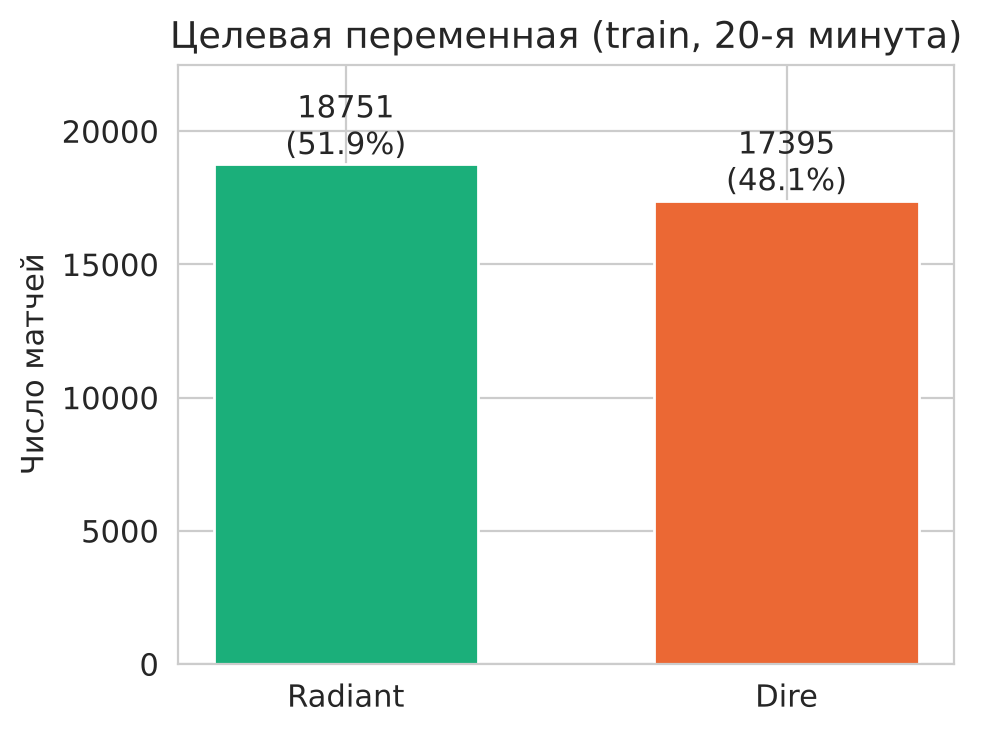

In [17]:
# Целевая переменная
fig, ax = plt.subplots(figsize=(5, 3.8))
counts = train_df['Победитель'].value_counts()[['Radiant', 'Dire']]
bars = ax.bar(counts.index, counts.values, color=[C_RAD, C_DIRE], width=0.6)
for b, v in zip(bars, counts.values):
    ax.text(b.get_x() + b.get_width() / 2, v, f'{v}\n({v / counts.sum():.1%})', ha='center', va='bottom')
ax.set_ylim(0, counts.max() * 1.2)
ax.set_ylabel('Число матчей')
ax.set_title('Целевая переменная (train, 20-я минута)')
plt.tight_layout()
plt.show()

### 3.1 Распределения признаков

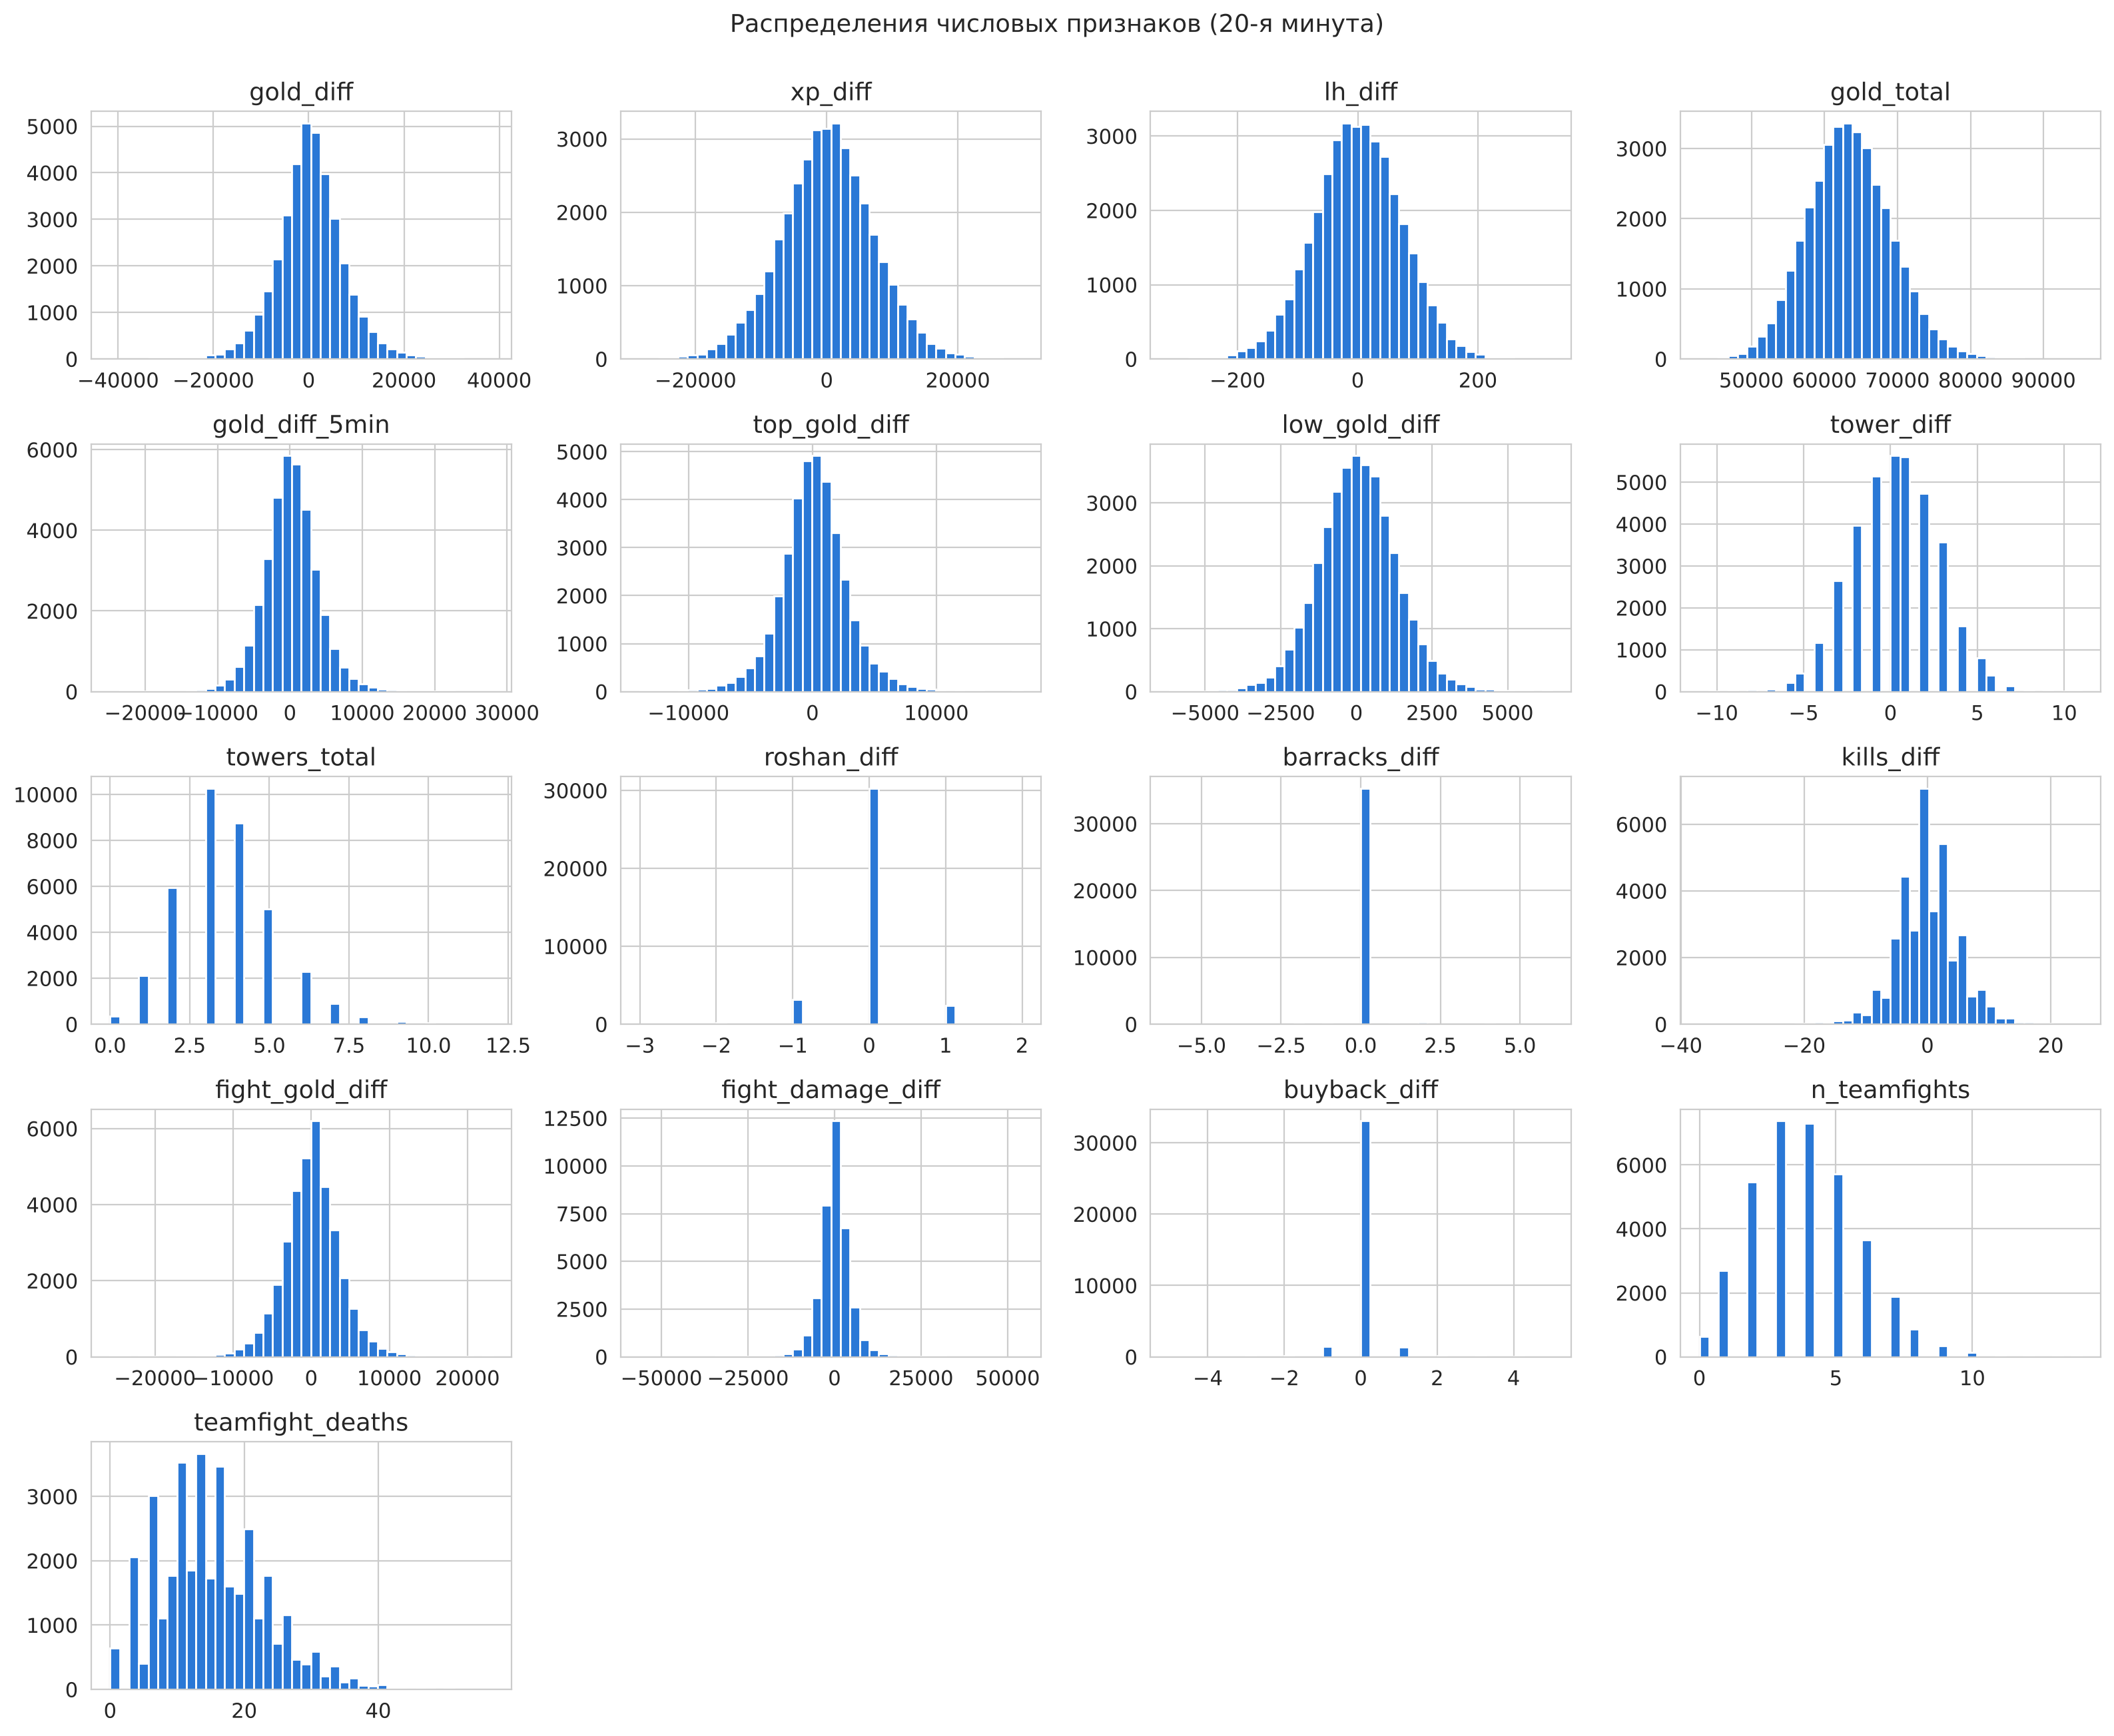

In [18]:
axes = train_df[num_features].hist(bins=40, figsize=(16, 13), color=C_MAIN, edgecolor='white')
plt.suptitle('Распределения числовых признаков (20-я минута)', y=1.0)
plt.tight_layout()
plt.show()

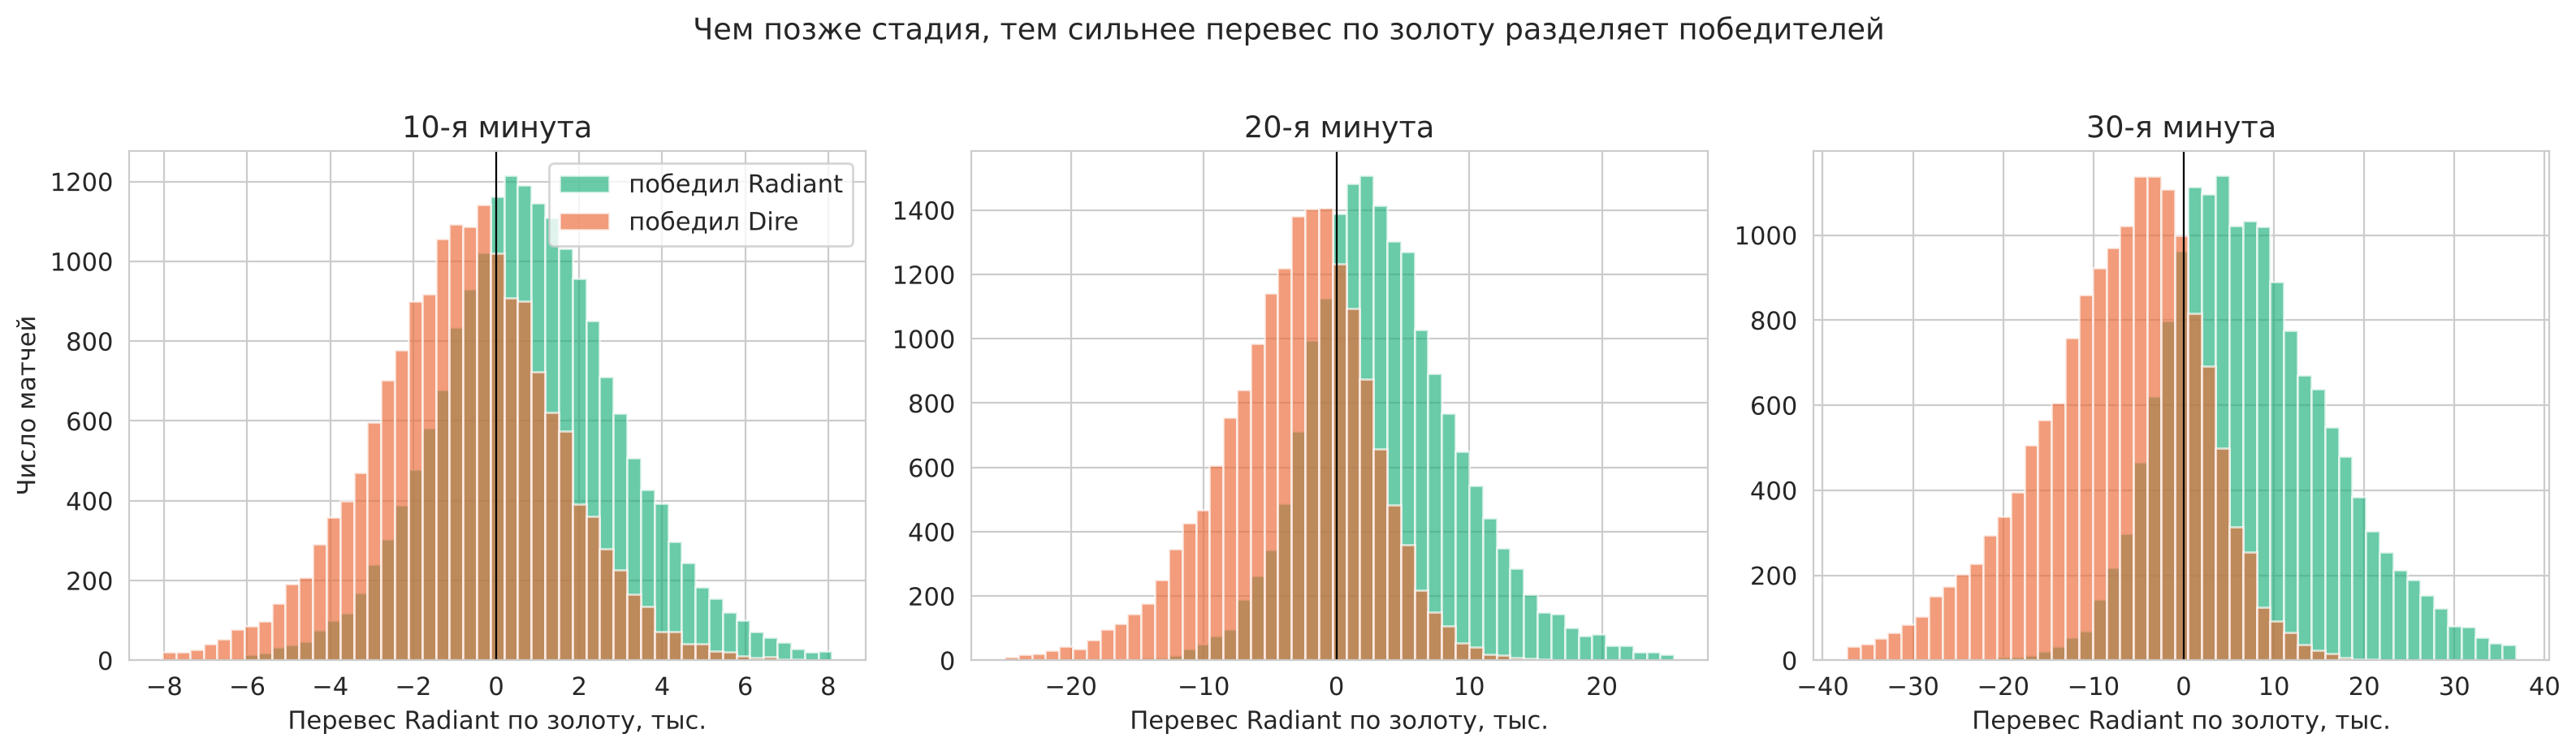

In [19]:
# Главный признак - перевес по золоту - на трёх стадиях матча
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, minute in zip(axes, STAGES):
    table = stages[minute][stages[minute]['match_id'].isin(train_ids)]
    gold_k = table['gold_diff'] / 1000
    bins = np.linspace(gold_k.quantile(0.002), gold_k.quantile(0.998), 50)
    ax.hist(gold_k[table[target] == 1], bins=bins, alpha=0.65, color=C_RAD, label='победил Radiant')
    ax.hist(gold_k[table[target] == 0], bins=bins, alpha=0.65, color=C_DIRE, label='победил Dire')
    ax.axvline(0, color='black', linewidth=0.8)
    ax.set_title(f'{minute}-я минута')
    ax.set_xlabel('Перевес Radiant по золоту, тыс.')
axes[0].set_ylabel('Число матчей')
axes[0].legend()
plt.suptitle('Чем позже стадия, тем сильнее перевес по золоту разделяет победителей', y=1.02)
plt.tight_layout()
plt.savefig('figures/gold_diff_by_stage.png', dpi=150, bbox_inches='tight')
plt.show()

### 3.2 Box-plot признаков по победителю

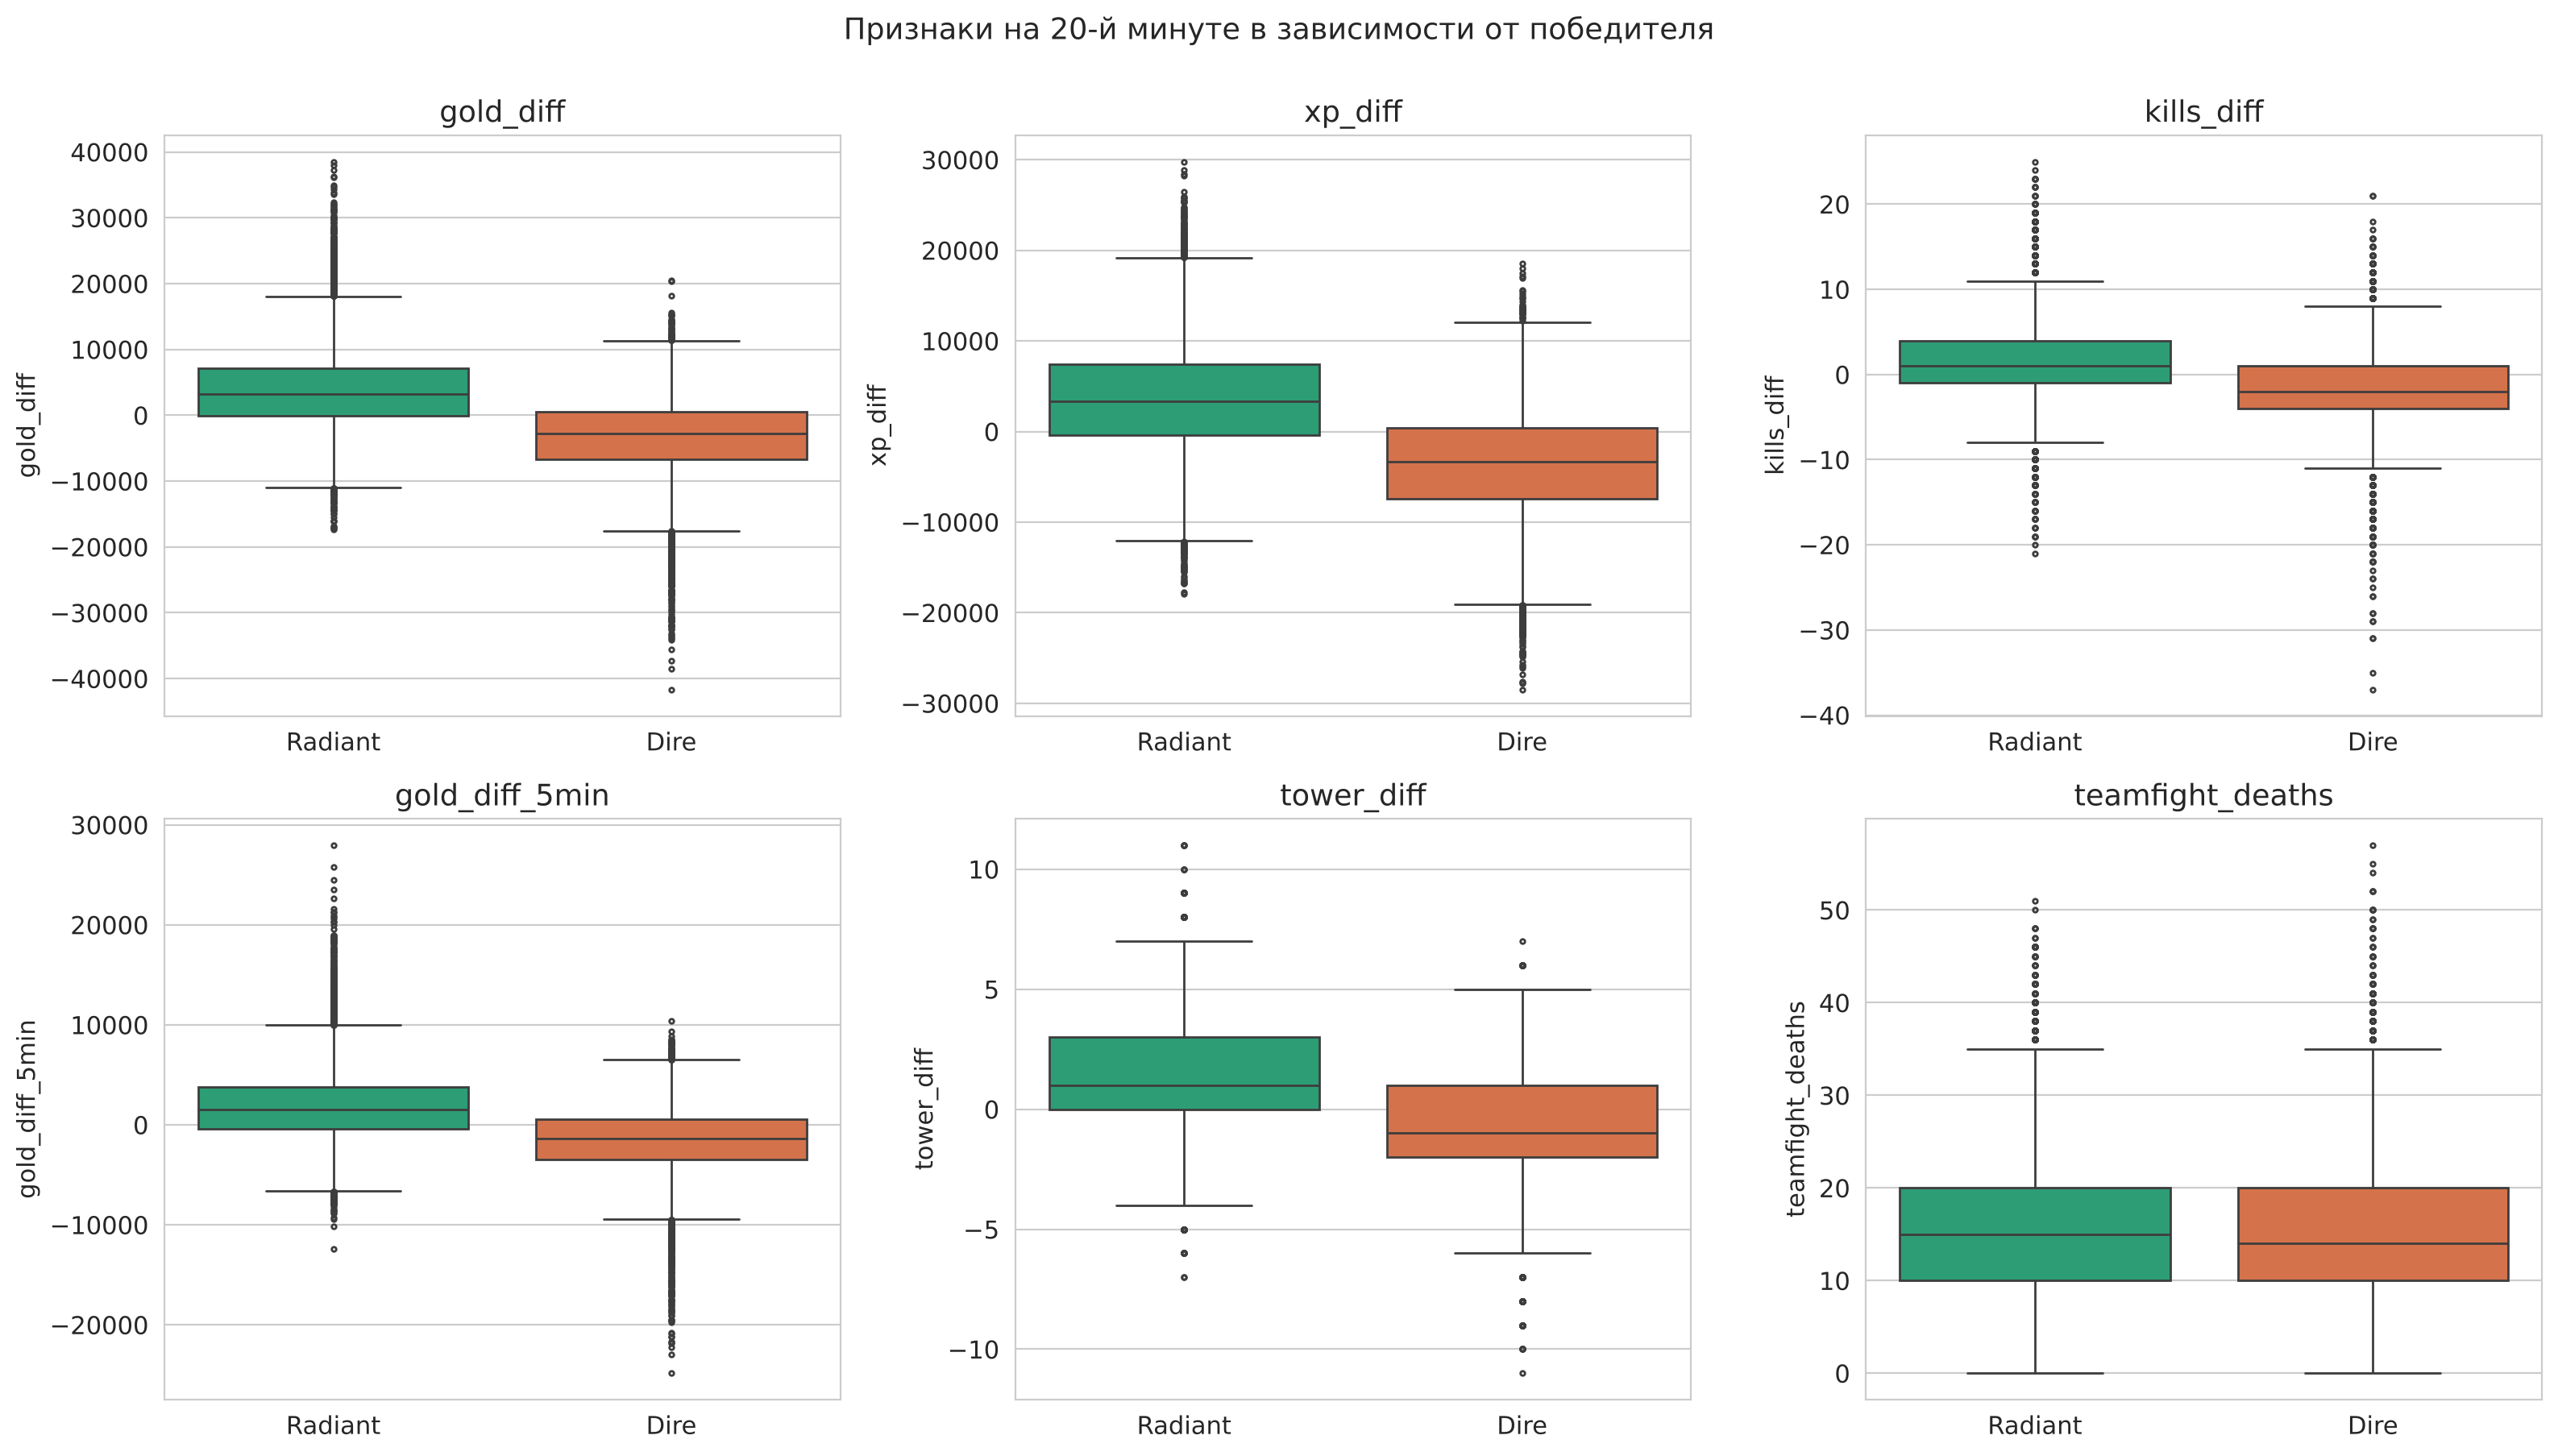

In [20]:
box_features = ['gold_diff', 'xp_diff', 'kills_diff', 'gold_diff_5min', 'tower_diff', 'teamfight_deaths']
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for ax, col in zip(axes.flatten(), box_features):
    sns.boxplot(data=train_df, x='Победитель', y=col, order=['Radiant', 'Dire'],
                palette={'Radiant': C_RAD, 'Dire': C_DIRE}, ax=ax, fliersize=2)
    ax.set_title(col)
    ax.set_xlabel('')
plt.suptitle('Признаки на 20-й минуте в зависимости от победителя', y=1.0)
plt.tight_layout()
plt.savefig('figures/boxplots.png', dpi=150, bbox_inches='tight')
plt.show()

### 3.3 Корреляционная матрица

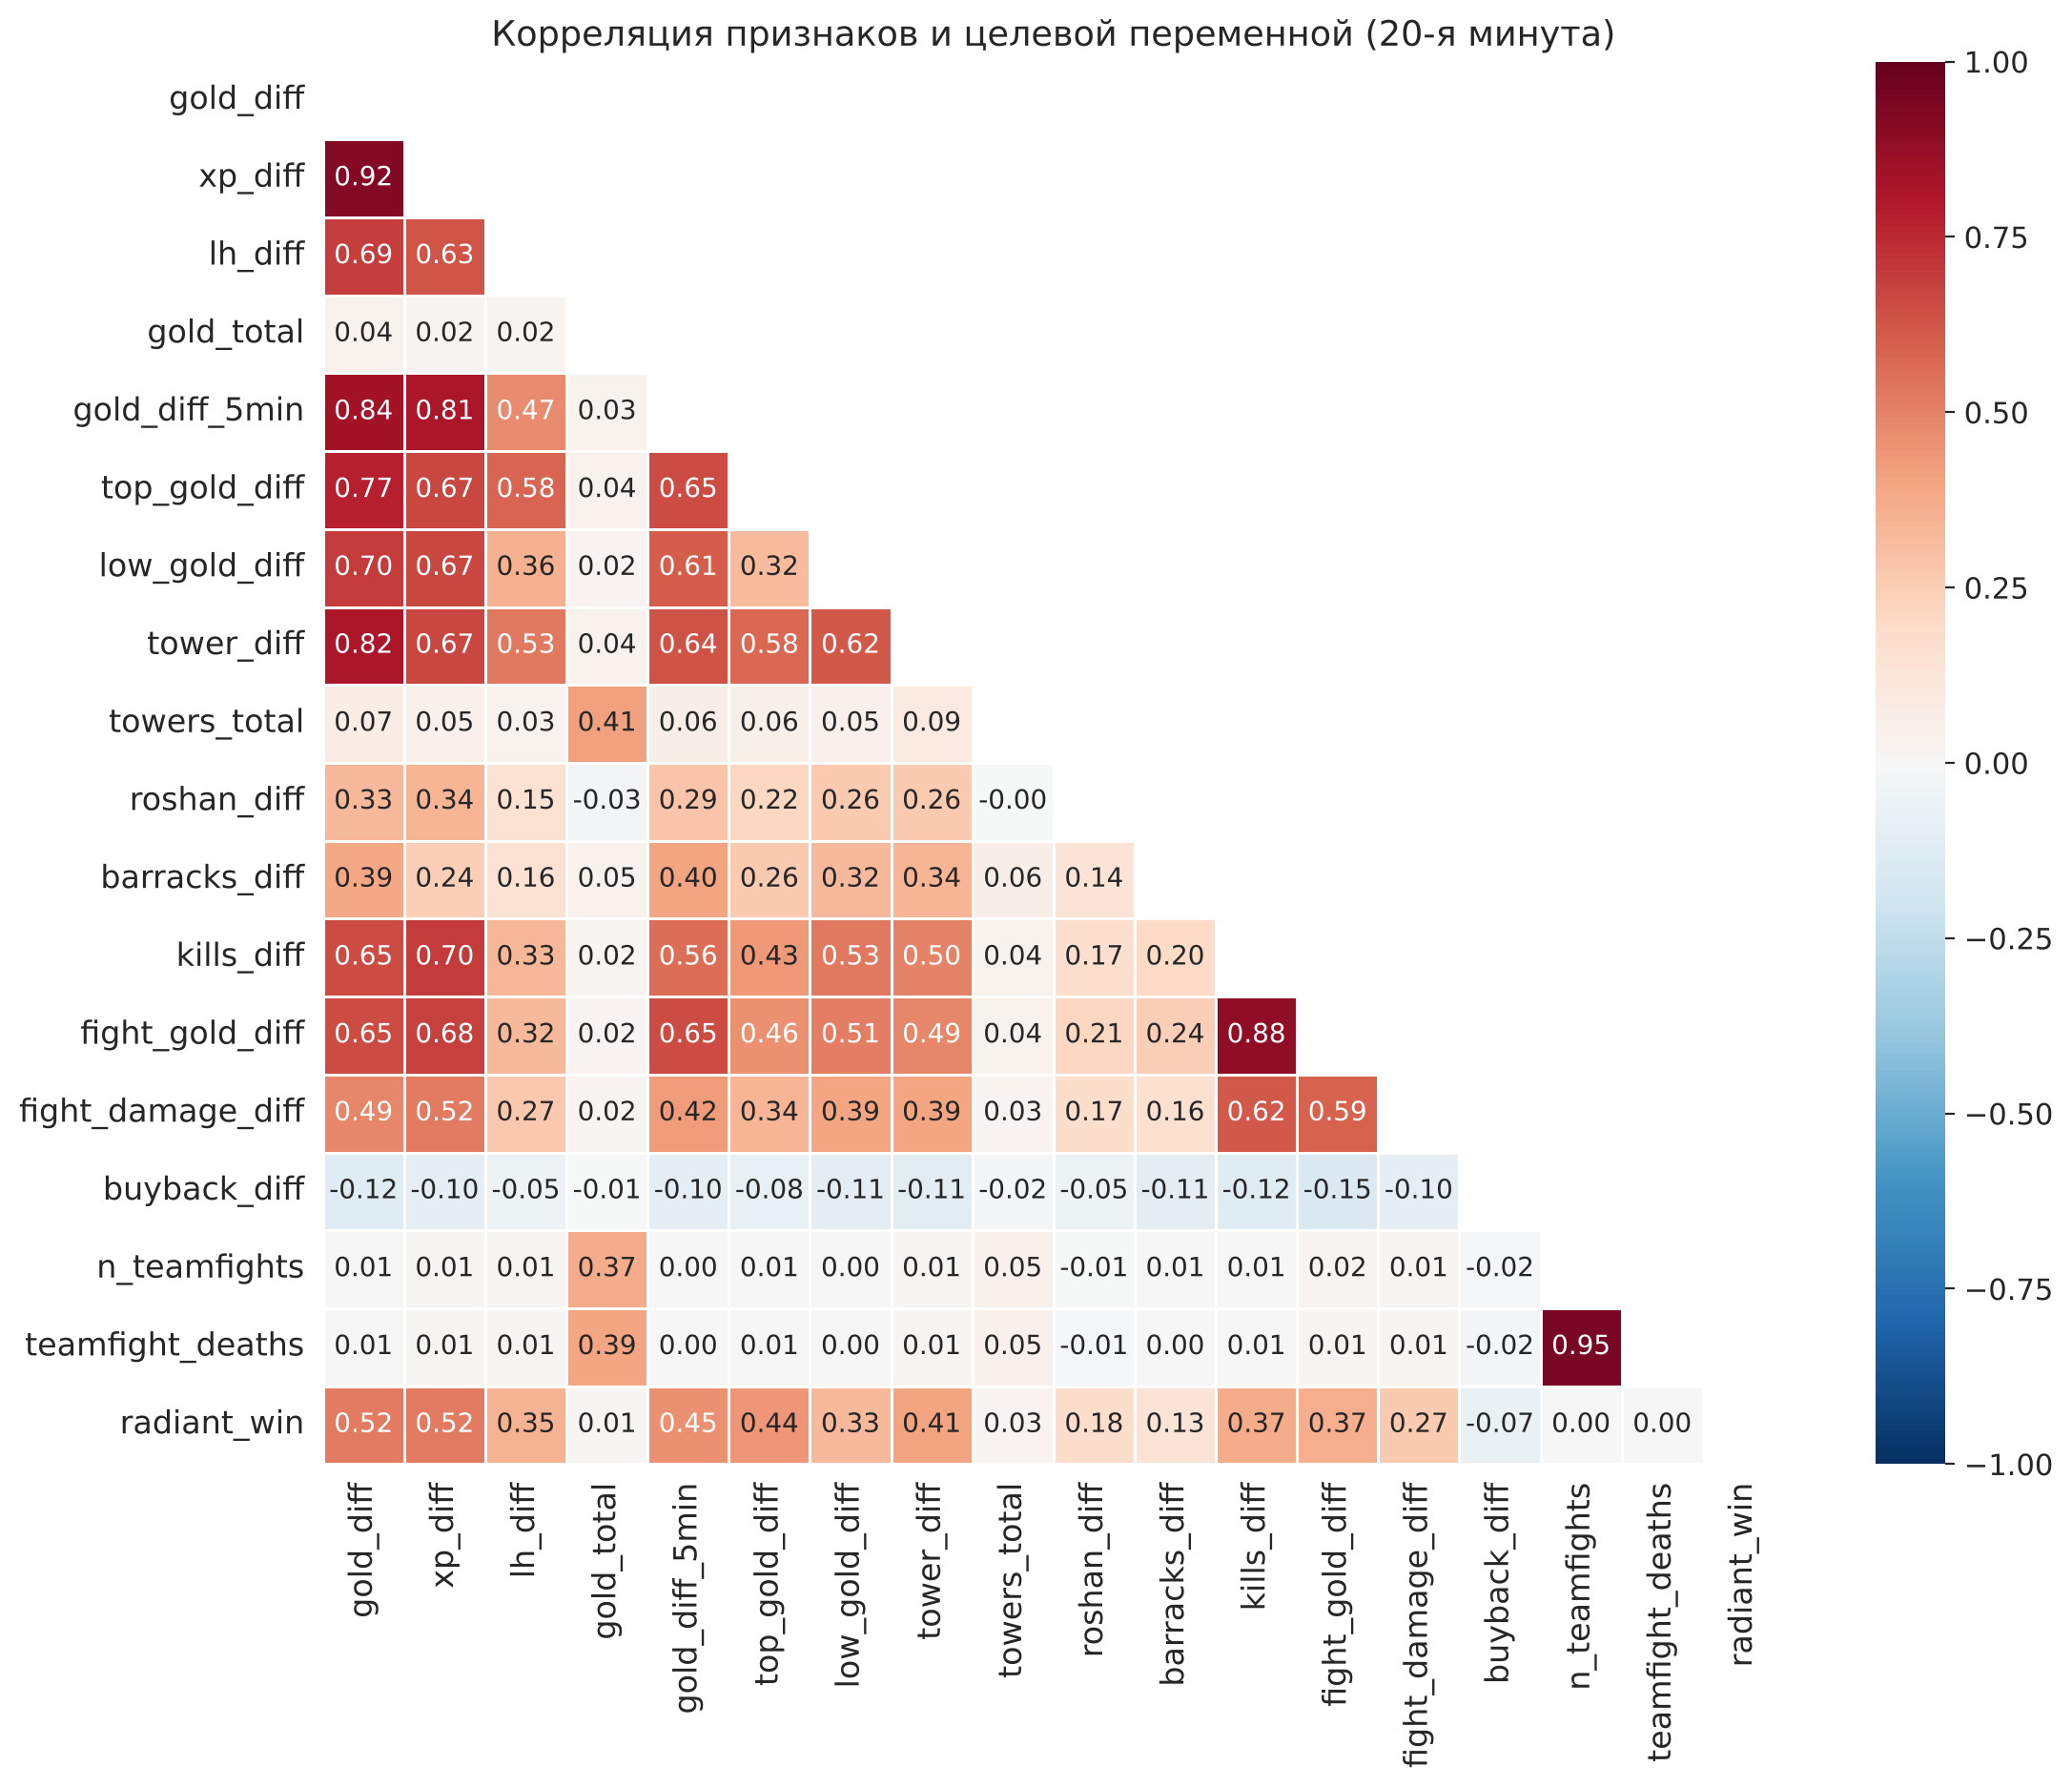

In [21]:
corr = train_df[num_features + [target]].corr()
mask = np.triu(np.ones_like(corr, dtype=bool))

fig, ax = plt.subplots(figsize=(11.5, 9.5))
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='RdBu_r', center=0, vmin=-1, vmax=1, linewidths=0.5, ax=ax,
            annot_kws={'size': 10})
ax.tick_params(labelsize=12)
ax.grid(False)
ax.set_title('Корреляция признаков и целевой переменной (20-я минута)')
plt.tight_layout()
plt.savefig('figures/corr_matrix.png', dpi=150, bbox_inches='tight')
plt.show()

### 3.4 Выбросы

In [22]:
# Правило 1.5 * IQR: сколько наблюдений выходит за "усы" box-plot
rows = []
for col in num_features:
    q1, q3 = train_df[col].quantile(0.25), train_df[col].quantile(0.75)
    iqr = q3 - q1
    out = (train_df[col] < q1 - 1.5 * iqr) | (train_df[col] > q3 + 1.5 * iqr)
    rows.append({'признак': col, 'min': train_df[col].min(), 'max': train_df[col].max(),
                 'доля выбросов, %': round(out.mean() * 100, 2)})
pd.DataFrame(rows).set_index('признак')

,min,max,"доля выбросов, %"
признак,,,
gold_diff,-41678.0,38532.0,3.15
xp_diff,-28491.0,29794.0,1.19
lh_diff,-313.0,323.0,0.93
gold_total,42882.0,95210.0,0.98
gold_diff_5min,-24842.0,27961.0,2.79
top_gold_diff,-13922.0,16910.0,3.50
low_gold_diff,-6171.0,6459.0,1.75
tower_diff,-11.0,11.0,1.40
towers_total,0.0,12.0,17.06


In [23]:
# Выбросы по золоту - это ошибки в данных или настоящие разгромы? Смотрим, кто в них побеждает
q1, q3 = train_df['gold_diff'].quantile(0.25), train_df['gold_diff'].quantile(0.75)
iqr = q3 - q1
high = train_df[train_df['gold_diff'] > q3 + 1.5 * iqr]
low = train_df[train_df['gold_diff'] < q1 - 1.5 * iqr]
print(f'Огромный перевес Radiant: {len(high)} матчей, Radiant победил в {high[target].mean():.1%}')
print(f'Огромный перевес Dire:    {len(low)} матчей, Radiant победил в {low[target].mean():.1%}')

Огромный перевес Radiant: 611 матчей, Radiant победил в 99.5%
Огромный перевес Dire:    528 матчей, Radiant победил в 1.5%


### 3.5 Категориальные признаки

first_blood {'radiant': {'mean': 0.569, 'count': 17280}, 'dire': {'mean': 0.468, 'count': 17944}, 'unknown': {'mean': 0.555, 'count': 922}}
game_mode {22: {'mean': 0.519, 'count': 35160}, 2: {'mean': 0.498, 'count': 986}}


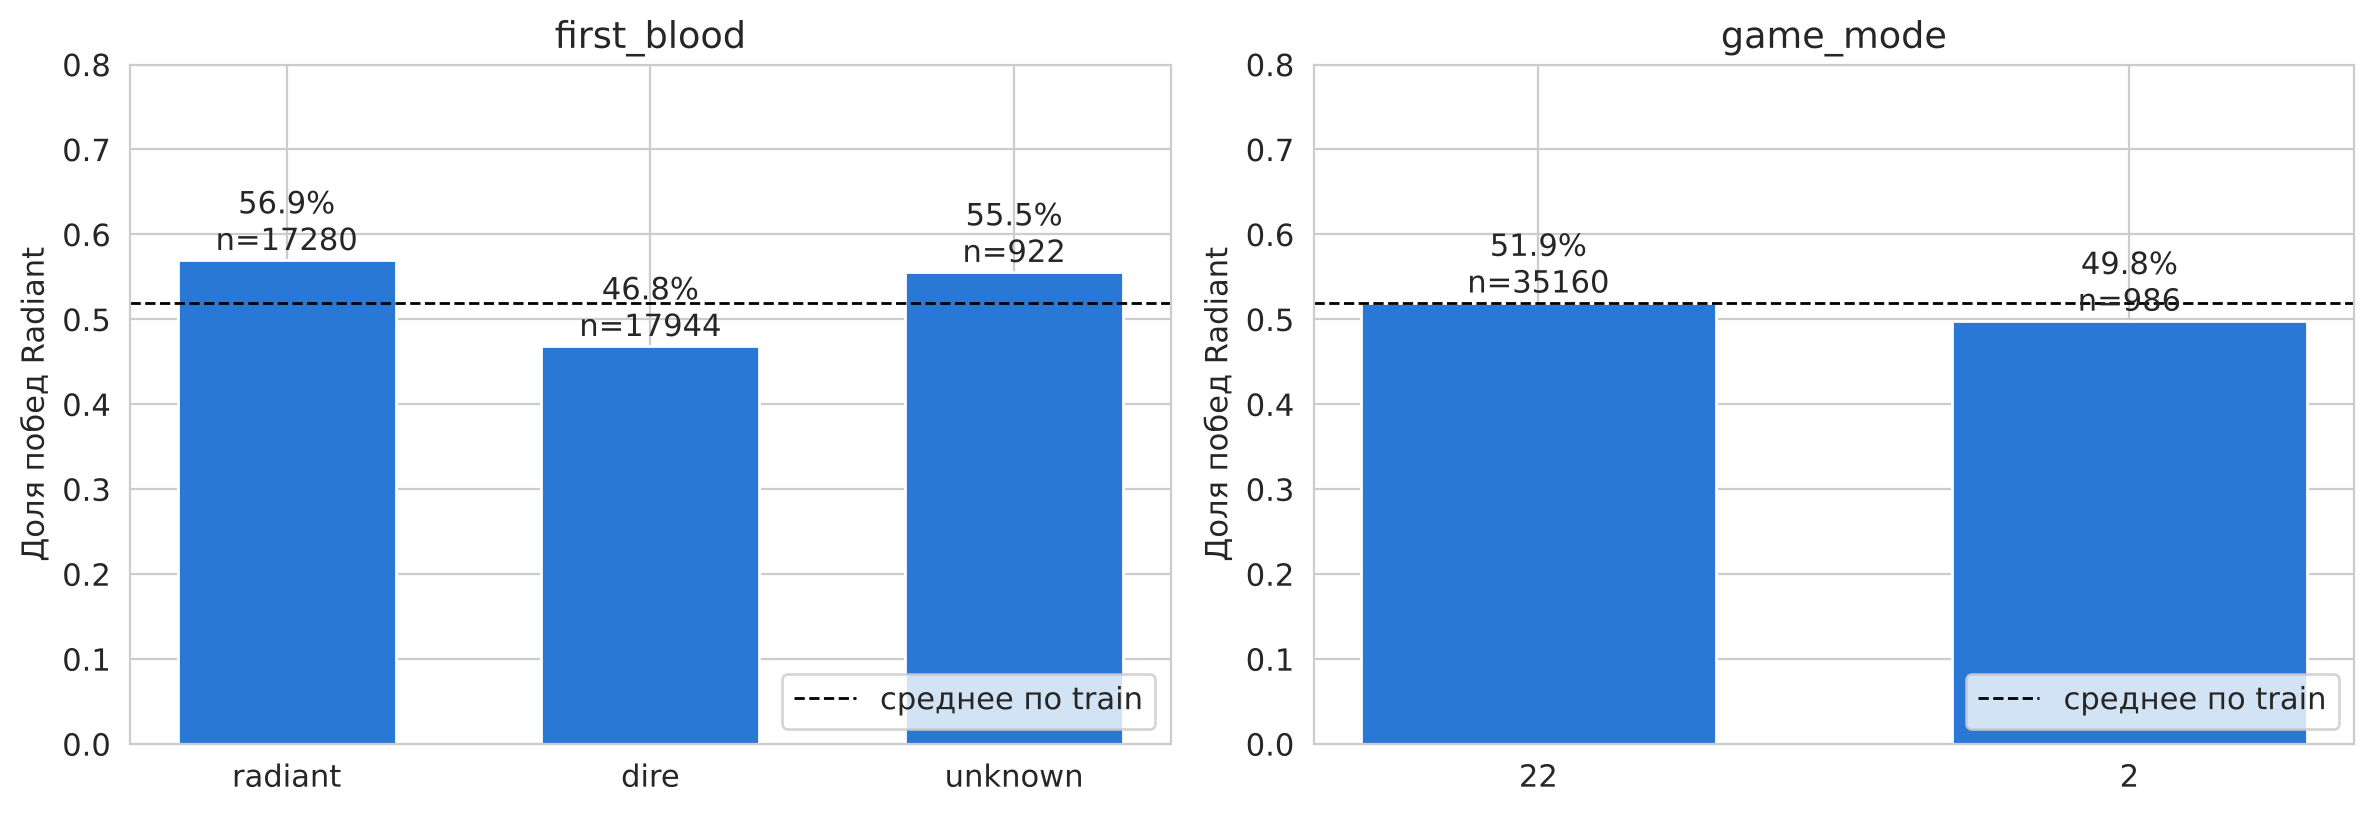

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
for ax, col, order in zip(axes, cat_features, [['radiant', 'dire', 'unknown'], [22, 2]]):
    stat = train_df.groupby(col)[target].agg(['mean', 'count']).loc[order]
    bars = ax.bar([str(v) for v in stat.index], stat['mean'], color=C_MAIN, width=0.6)
    for b, (m, n) in zip(bars, stat.values):
        ax.text(b.get_x() + b.get_width() / 2, m, f'{m:.1%}\nn={int(n)}', ha='center', va='bottom')
    ax.axhline(train_df[target].mean(), color='black', linestyle='--', linewidth=1, label='среднее по train')
    ax.set_ylim(0, 0.8)
    ax.set_ylabel('Доля побед Radiant')
    ax.set_title(col)
    ax.legend(loc='lower right')
    print(col, stat.round(3).to_dict('index'))
plt.tight_layout()
plt.show()

### 3.6 Герои (драфт)

Герой - категориальный признак с большим числом значений. Смотрим, насколько различаются доли побед героев: если различий нет, кодировать драфт незачем.

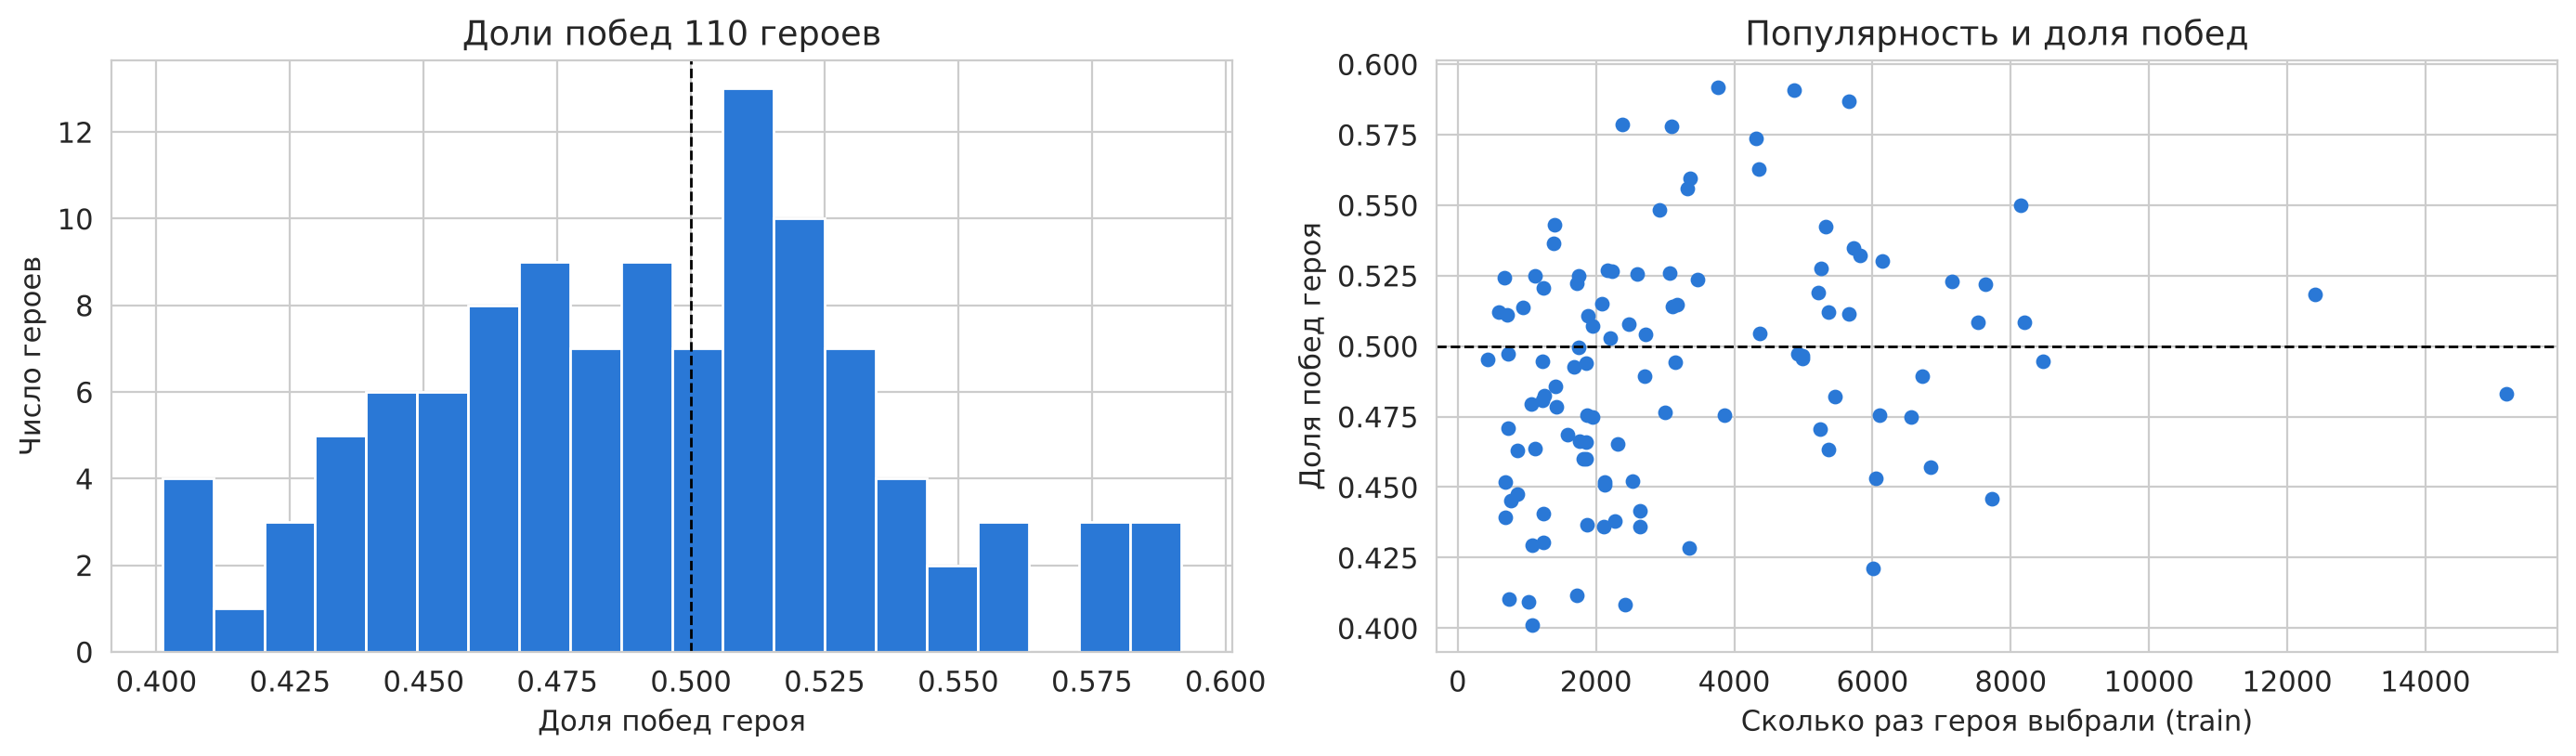

Доля побед героев: от 40.1% до 59.2%; реже всего героя выбирали 430 раз, чаще всего 15172
Пять героев с самой высокой и самой низкой долей побед (hero_id):


,доля побед,матчей
hero_id,,
57,0.592,3760
67,0.591,4860
42,0.587,5655
102,0.579,2378
70,0.578,3097
61,0.401,1072
53,0.408,2418
79,0.409,1031
58,0.410,736


In [25]:
hero_train = heroes[heroes['match_id'].isin(train_ids)].merge(match_clean[['match_id', 'radiant_win']], on='match_id')
hero_train['win'] = ((hero_train['player_slot'] < 5) == (hero_train['radiant_win'] == 1)).astype(int)
hero_stat = hero_train.groupby('hero_id')['win'].agg(['mean', 'count']).rename(columns={'mean': 'доля побед', 'count': 'матчей'})

fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
axes[0].hist(hero_stat['доля побед'], bins=20, color=C_MAIN, edgecolor='white')
axes[0].axvline(0.5, color='black', linestyle='--', linewidth=1)
axes[0].set_xlabel('Доля побед героя')
axes[0].set_ylabel('Число героев')
axes[0].set_title('Доли побед 110 героев')
axes[1].scatter(hero_stat['матчей'], hero_stat['доля побед'], color=C_MAIN, s=22)
axes[1].axhline(0.5, color='black', linestyle='--', linewidth=1)
axes[1].set_xlabel('Сколько раз героя выбрали (train)')
axes[1].set_ylabel('Доля побед героя')
axes[1].set_title('Популярность и доля побед')
plt.tight_layout()
plt.savefig('figures/heroes.png', dpi=150, bbox_inches='tight')
plt.show()

print(f"Доля побед героев: от {hero_stat['доля побед'].min():.1%} до {hero_stat['доля побед'].max():.1%}; "
      f"реже всего героя выбирали {hero_stat['матчей'].min()} раз, чаще всего {hero_stat['матчей'].max()}")
print('Пять героев с самой высокой и самой низкой долей побед (hero_id):')
display(pd.concat([hero_stat.sort_values('доля побед', ascending=False).head(5),
                   hero_stat.sort_values('доля побед').head(5)]).round(3))

### 3.7 Итоговый KDA: почему его нельзя брать в модель

Убийства и смерти в драках **до выбранной минуты** мы уже посчитали (`kills_diff`) — это честный признак. А вот итоговые убийства, смерти и ассисты из `players.csv` известны только после конца матча.

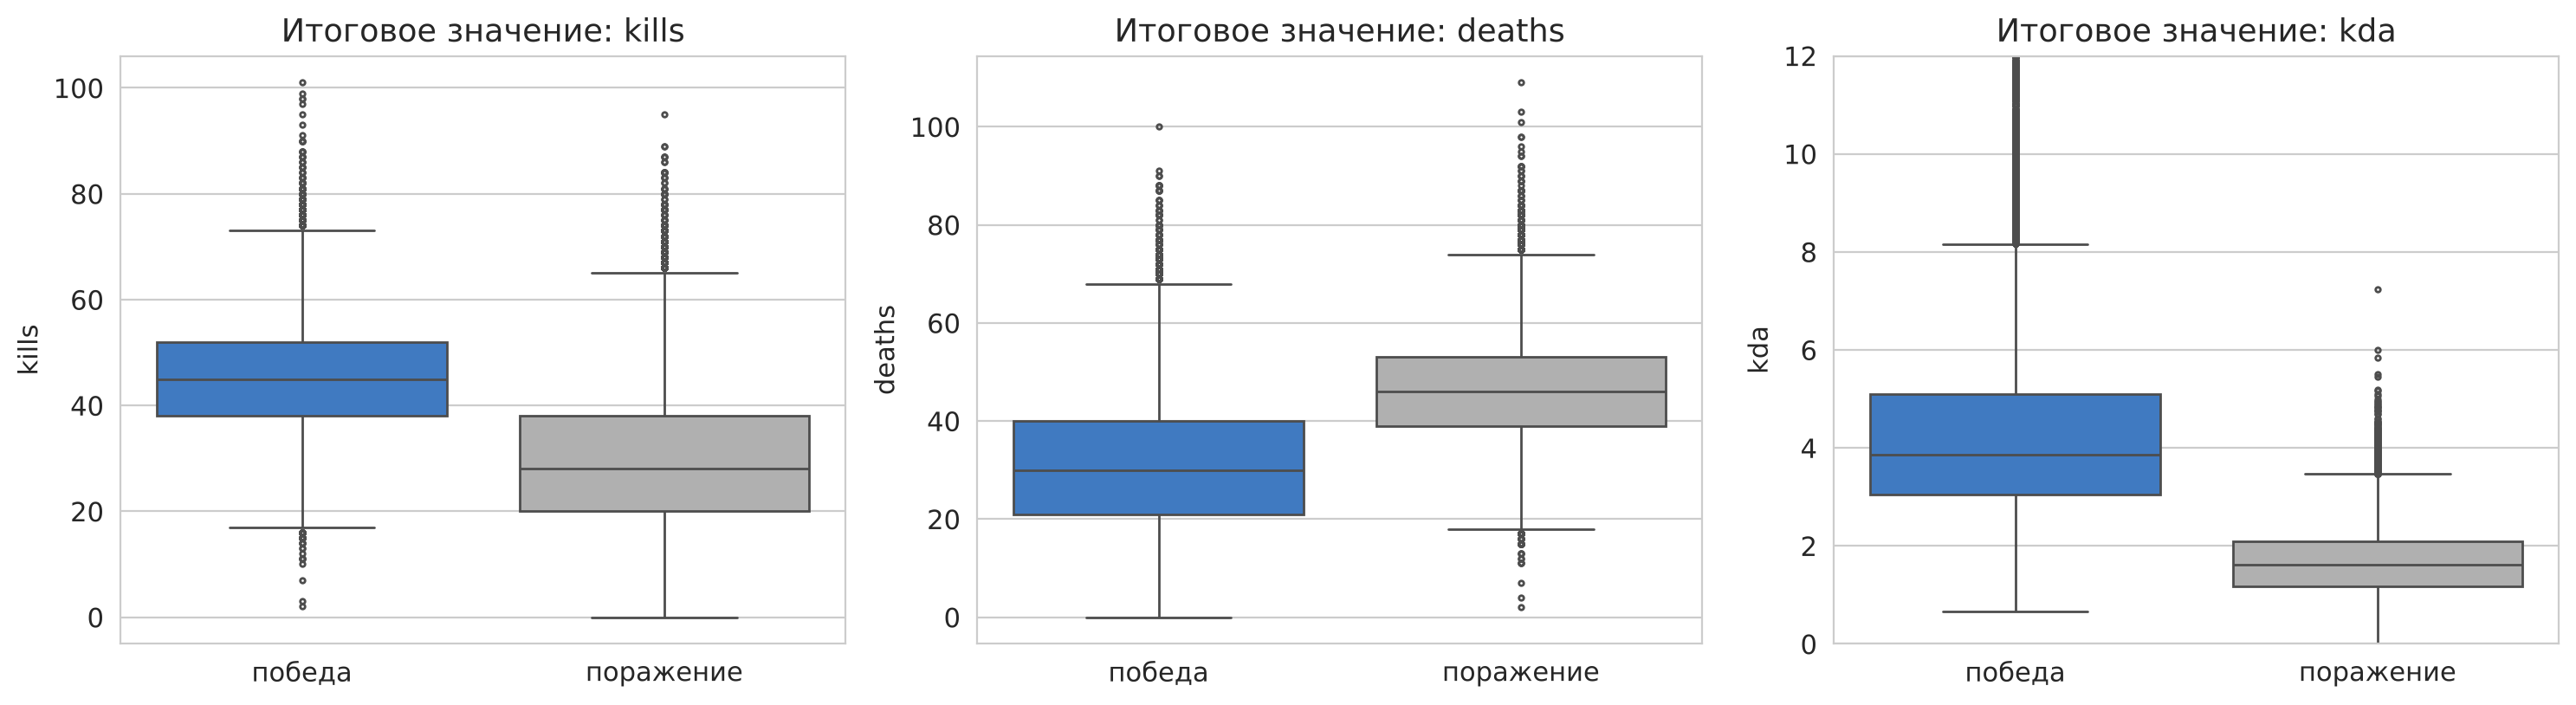

Победившая команда имеет KDA выше проигравшей в 90.3% матчей


In [26]:
# Итоговые убийства, смерти и ассисты команд - из players.csv (статистика на конец матча)
p = players[players['match_id'].isin(train_ids)].copy()
p['side'] = np.where(p['player_slot'] < 5, 'radiant', 'dire')
team_final = p.groupby(['match_id', 'side'])[['kills', 'deaths', 'assists']].sum().reset_index()
team_final['kda'] = (team_final['kills'] + team_final['assists']) / team_final['deaths'].clip(lower=1)
team_final = team_final.merge(match_clean[['match_id', 'radiant_win']], on='match_id')
team_final['Результат'] = np.where((team_final['side'] == 'radiant') == (team_final['radiant_win'] == 1),
                                   'победа', 'поражение')

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
for ax, col in zip(axes, ['kills', 'deaths', 'kda']):
    sns.boxplot(data=team_final, x='Результат', y=col, order=['победа', 'поражение'],
                palette={'победа': C_MAIN, 'поражение': '#b0b0b0'}, ax=ax, fliersize=2)
    ax.set_title(f'Итоговое значение: {col}')
    ax.set_xlabel('')
axes[2].set_ylim(0, 12)
plt.tight_layout()
plt.show()

win_kda = team_final.pivot(index='match_id', columns='Результат', values='kda')
print(f'Победившая команда имеет KDA выше проигравшей в {(win_kda["победа"] > win_kda["поражение"]).mean():.1%} матчей')

**Выводы из EDA.**

1. **Главный сигнал — экономика.** Корреляция `gold_diff` и `xp_diff` с победой Radiant равна 0,52. На гистограммах видно, что с каждой стадией распределения победителей расходятся всё сильнее: на 10-й минуте они почти накладываются друг на друга, на 30-й разделены заметно.
2. **Убийства информативны, но слабее золота.** Корреляция `kills_diff` с победой — 0,37. При этом `kills_diff` сам коррелирует с `gold_diff` на 0,65: за убийства дают золото и опыт, поэтому значительная часть этой информации уже есть в экономике.
3. **Сильная мультиколлинеарность.** `gold_diff` и `xp_diff` коррелируют на 0,92, `gold_diff` и `tower_diff` — на 0,82, `kills_diff` и `fight_gold_diff` — на 0,88, `n_teamfights` и `teamfight_deaths` — на 0,95. Для качества прогноза это не страшно, но коэффициенты линейной модели и важности отдельных признаков нужно читать осторожно: коррелирующие признаки делят вклад между собой.
4. **Число драк без привязки к команде бесполезно.** Корреляция `n_teamfights` и `teamfight_deaths` с целью равна 0,00: важно не сколько было драк, а кто их выиграл.
5. **Выбросы.** По правилу 1,5·IQR у `gold_diff` 3,2% выбросов. Это не ошибки, а разгромы: при огромном перевесе Radiant побеждает в 99,5% таких матчей, при огромном отставании — в 1,5%. Удалять их нельзя, это самые информативные наблюдения. У `towers_total`, `roshan_diff` и `buyback_diff` «выбросов» 9–17% только потому, что это счётчики с несколькими значениями, и правило IQR к ним неприменимо. Реальные аномалии — матчи с вышедшими игроками — убраны на шаге 2.2. Масштаб признаков выравнивает `StandardScaler`.
6. **Категориальные признаки.** Если первую кровь сделал Radiant, он побеждает в 56,9% матчей, если Dire — в 46,8%. Режим игры на исход почти не влияет: доля побед Radiant 51,9% в Ranked All Pick и 49,8% в Captains Mode, причём матчей Captains Mode меньше 3%.
7. **Герои различаются по силе.** Доля побед героя меняется от 40,1% до 59,2%, и это не шум: даже самого редкого героя выбирали 430 раз. Значит, драфт несёт информацию ещё до начала игры.
8. **Итоговый KDA в модель брать нельзя.** Команда-победитель имеет более высокий итоговый KDA в 90,3% матчей — но это значение известно только после конца игры. В разделе 11.3 показано, к чему приводит такая утечка.

## 4. Feature engineering

Исходные таблицы содержат показатели отдельных игроков и отдельные события. Модели нужен взгляд «команда против команды», поэтому все признаки ниже — сконструированные.

| Новый признак | Как считается | Зачем |
|---|---|---|
| `gold_diff`, `xp_diff`, `lh_diff` | сумма по пяти игрокам Radiant минус сумма по Dire | исход зависит от **перевеса**, а не от абсолютных значений; один признак вместо десяти столбцов |
| `gold_diff_5min` | `gold_diff` сейчас минус `gold_diff` пять минут назад | динамика: кто наращивает преимущество прямо сейчас |
| `top_gold_diff` | золото самого богатого героя Radiant минус самого богатого Dire | в Dota исход поздней игры часто решает один «керри» |
| `low_gold_diff` | то же для самых бедных героев | слабое звено команды — насколько отстаёт поддержка |
| `tower_diff`, `towers_total` | разность и сумма разрушенных башен | контроль карты и общий темп игры |
| `roshan_diff`, `barracks_diff` | разность убийств Рошана и разрушенных бараков | ключевые объекты середины и конца игры |
| `kills_diff` | убийства Radiant в драках минус убийства Dire (до минуты `T`) | K и D из KDA: кто выигрывает сражения |
| `fight_gold_diff`, `fight_damage_diff` | разница золота, заработанного в драках, и нанесённого в них урона | исход драк точнее, чем просто счёт убийств |
| `buyback_diff` | разница числа выкупов | выкуп — вынужденная трата золота, признак трудного положения |
| `n_teamfights`, `teamfight_deaths` | число драк и смертей в них до минуты `T` | насколько «кровавая» игра |
| `first_blood` | кто сделал первое убийство | ранний сигнал о линии |
| `r_hero_*`, `d_hero_*` | one-hot героев отдельно для каждой команды (220 столбцов) | герои различаются по силе; драфт известен до начала матча |

Ниже проверяем, насколько каждый признак полезен сам по себе: ROC-AUC, если ранжировать матчи только по нему.

In [27]:
from sklearn.metrics import roc_auc_score

rows = {}
for minute in STAGES:
    table = stages[minute][stages[minute]['match_id'].isin(train_ids)]
    rows[f'{minute} мин'] = {col: roc_auc_score(table[target], table[col]) for col in num_features}
single_auc = pd.DataFrame(rows).round(3)
single_auc.sort_values('20 мин', ascending=False)

,10 мин,20 мин,30 мин
gold_diff,0.703,0.812,0.883
xp_diff,0.682,0.808,0.874
gold_diff_5min,0.686,0.769,0.817
top_gold_diff,0.670,0.764,0.815
tower_diff,0.556,0.731,0.819
kills_diff,0.582,0.715,0.778
fight_gold_diff,0.582,0.709,0.788
lh_diff,0.623,0.701,0.741
low_gold_diff,0.581,0.684,0.750
fight_damage_diff,0.564,0.663,0.675


**Что видно по таблице.**

- На любой стадии лучший одиночный признак — `gold_diff` (ROC-AUC 0,70 → 0,81 → 0,88), сразу за ним `xp_diff`.
- Новые признаки работают: динамика `gold_diff_5min` и золото самого богатого героя `top_gold_diff` сами по себе дают 0,77 и 0,76 на 20-й минуте.
- **Убийства — рабочий признак среднего уровня.** `kills_diff` даёт 0,58 → 0,72 → 0,78, золото из драк `fight_gold_diff` — почти столько же. Это намного лучше, чем просто число драк (0,50), но хуже, чем общий перевес по золоту.
- **Выкупы работают «наоборот».** У `buyback_diff` на 30-й минуте ROC-AUC 0,40, то есть меньше 0,5: команда, которая чаще выкупается, чаще проигрывает.
- **Объекты «включаются» позже.** `tower_diff` на 10-й минуте почти бесполезен (0,56), а к 30-й выходит на уровень второстепенных экономических признаков вроде `gold_diff_5min` (0,82 у обоих), хотя до `gold_diff` (0,88) не дотягивает. Рошан и бараки начинают работать только к 30-й минуте (0,70 и 0,71): раньше этих событий почти не бывает.
- `gold_total`, `towers_total`, `n_teamfights` и `teamfight_deaths` дают 0,50 — уровень случайного угадывания. Они описывают темп игры, а не перевес одной из команд. В модели их оставляем: деревья и сеть могут использовать их в сочетании с другими, а дальше ablation покажет, есть ли от них польза.

## 5. Классические модели

Предобработка лежит **внутри `Pipeline`**: `StandardScaler` для числовых признаков и `OneHotEncoder` для категориальных обучаются только на обучающей части каждого фолда. Так мы избегаем утечки «fit на всём датасете, потом split».

- Кросс-валидация: `StratifiedKFold`, 5 фолдов.
- Метрики одинаковы для всех моделей: **ROC-AUC** (основная), accuracy и F1.
- Подбор гиперпараметров: `GridSearchCV` для логистической регрессии и дерева, `RandomizedSearchCV` для Random Forest и бустинга.

In [28]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.model_selection import StratifiedKFold, cross_val_score, GridSearchCV, RandomizedSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, f1_score
from sklearn.base import clone

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)


hero_set = set(hero_features)


def make_prep(cols=None):
    """Предобработка для набора столбцов cols: числовые масштабируем, категориальные кодируем one-hot,
    столбцы драфта (уже 0/1) передаём как есть."""
    cols = features if cols is None else cols
    num_cols = [c for c in cols if c in num_features]
    cat_cols = [c for c in cols if c in cat_features]
    hero_cols = [c for c in cols if c in hero_set]
    steps = []
    if num_cols:
        steps.append(('num', StandardScaler(), num_cols))
    if cat_cols:
        steps.append(('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), cat_cols))
    if hero_cols:
        steps.append(('hero', 'passthrough', hero_cols))
    return ColumnTransformer(steps)


def make_pipe(model, cols=None):
    return Pipeline([('prep', make_prep(cols)), ('model', model)])


def test_metrics(y_true, proba):
    """Три метрики на тесте по предсказанной вероятности победы Radiant."""
    pred = (proba >= 0.5).astype(int)
    return {'Test Accuracy': accuracy_score(y_true, pred),
            'Test F1': f1_score(y_true, pred),
            'Test ROC-AUC': roc_auc_score(y_true, proba)}


results = []        # сюда собираем строки итоговой таблицы
test_proba = {}     # вероятности на тесте - пригодятся для анализа


def add_result(name, cv_scores, fit_time, proba):
    row = {'Модель': name, 'CV ROC-AUC': np.mean(cv_scores), 'CV std': np.std(cv_scores)}
    row.update(test_metrics(y_test, proba))
    row['Время обучения, с'] = fit_time
    results.append(row)
    test_proba[name] = proba
    print(f"{name}: CV ROC-AUC = {row['CV ROC-AUC']:.4f} ± {row['CV std']:.4f} | "
          f"test ROC-AUC = {row['Test ROC-AUC']:.4f}, accuracy = {row['Test Accuracy']:.4f}, F1 = {row['Test F1']:.4f} | "
          f"{fit_time:.1f} c")


def evaluate(name, model):
    """5-fold CV на train, затем обучение на всём train и метрики на test."""
    cv_scores = cross_val_score(model, X_train, y_train, cv=cv, scoring='roc_auc')
    t0 = time.time()
    model.fit(X_train, y_train)
    fit_time = time.time() - t0
    add_result(name, cv_scores, fit_time, model.predict_proba(X_test)[:, 1])
    return model


def search_cv_scores(search):
    """ROC-AUC лучшей конфигурации на каждом из 5 фолдов."""
    return [search.cv_results_[f'split{i}_test_score'][search.best_index_] for i in range(cv.get_n_splits())]

### 5.1 Точки отсчёта (baseline)

1. Всегда предсказывать самый частый класс.
2. Логистическая регрессия на **одном** признаке `gold_diff` — по сути правило «кто впереди по золоту, тот и победит».
3. Логистическая регрессия **без драфта** — только на признаках, которые появляются по ходу игры.

In [29]:
dummy = evaluate('Baseline: частый класс', DummyClassifier(strategy='most_frequent'))
gold_only = evaluate('Baseline: только gold_diff',
                     make_pipe(LogisticRegression(max_iter=1000), cols=['gold_diff']))
no_draft = evaluate('Baseline: LogReg без драфта',
                    make_pipe(LogisticRegression(max_iter=1000), cols=game_features))

Baseline: частый класс: CV ROC-AUC = 0.5000 ± 0.0000 | test ROC-AUC = 0.5000, accuracy = 0.5188, F1 = 0.6832 | 0.0 c


Baseline: только gold_diff: CV ROC-AUC = 0.8117 ± 0.0058 | test ROC-AUC = 0.8146, accuracy = 0.7336, F1 = 0.7463 | 0.0 c


Baseline: LogReg без драфта: CV ROC-AUC = 0.8215 ± 0.0061 | test ROC-AUC = 0.8239, accuracy = 0.7442, F1 = 0.7559 | 0.1 c


### 5.2 Логистическая регрессия (linear) — GridSearchCV

In [30]:
grid_lr = GridSearchCV(make_pipe(LogisticRegression(max_iter=2000)),
                       {'model__C': [0.001, 0.01, 0.1, 1, 10, 100]},
                       cv=cv, scoring='roc_auc', n_jobs=-1)
grid_lr.fit(X_train, y_train)
print('Лучшие параметры:', grid_lr.best_params_)
print(pd.DataFrame(grid_lr.cv_results_)[['param_model__C', 'mean_test_score', 'std_test_score']].round(4).to_string(index=False))

best_lr = grid_lr.best_estimator_
print('Итераций до сходимости:', best_lr.named_steps['model'].n_iter_[0], 'из 2000 разрешённых')
add_result('Logistic Regression', search_cv_scores(grid_lr), grid_lr.refit_time_, best_lr.predict_proba(X_test)[:, 1])

Лучшие параметры: {'model__C': 0.1}
 param_model__C  mean_test_score  std_test_score
          0.001           0.8323          0.0057
          0.010           0.8486          0.0061
          0.100           0.8510          0.0062
          1.000           0.8508          0.0063
         10.000           0.8508          0.0063
        100.000           0.8508          0.0063
Итераций до сходимости: 40 из 2000 разрешённых
Logistic Regression: CV ROC-AUC = 0.8510 ± 0.0062 | test ROC-AUC = 0.8466, accuracy = 0.7588, F1 = 0.7694 | 0.5 c


### 5.3 Дерево решений (tree-based) — GridSearchCV

In [31]:
grid_dt = GridSearchCV(make_pipe(DecisionTreeClassifier(random_state=RANDOM_STATE)),
                       {'model__max_depth': [2, 3, 4, 5, 6, 8, 10, 14],
                        'model__min_samples_leaf': [1, 20, 100]},
                       cv=cv, scoring='roc_auc', n_jobs=-1, return_train_score=True)
grid_dt.fit(X_train, y_train)
print('Лучшие параметры:', grid_dt.best_params_)

best_dt = grid_dt.best_estimator_
add_result('Decision Tree', search_cv_scores(grid_dt), grid_dt.refit_time_, best_dt.predict_proba(X_test)[:, 1])

Лучшие параметры: {'model__max_depth': 8, 'model__min_samples_leaf': 100}
Decision Tree: CV ROC-AUC = 0.8183 ± 0.0067 | test ROC-AUC = 0.8188, accuracy = 0.7408, F1 = 0.7511 | 0.8 c


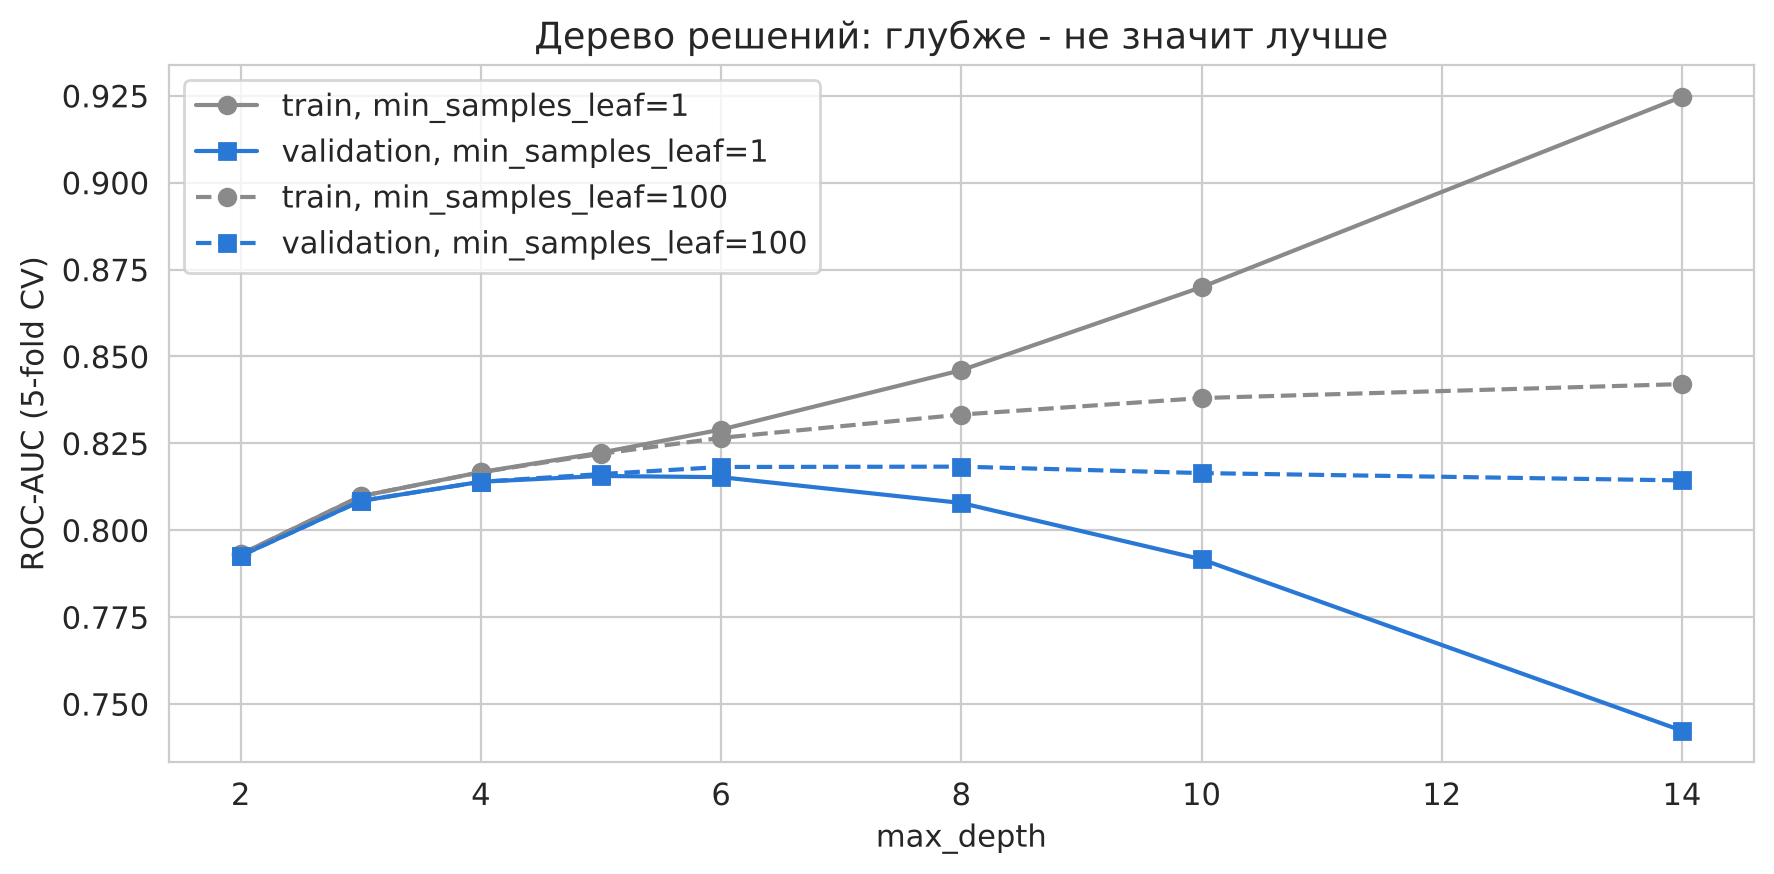

In [32]:
# Глубина дерева и переобучение: ROC-AUC на обучающих и валидационных фолдах
res_dt = pd.DataFrame(grid_dt.cv_results_)
fig, ax = plt.subplots(figsize=(9, 4.5))
for leaf, style in zip([1, 100], ['-', '--']):
    part = res_dt[res_dt['param_model__min_samples_leaf'] == leaf]
    ax.plot(part['param_model__max_depth'], part['mean_train_score'], style, marker='o', color='#8a8a8a',
            label=f'train, min_samples_leaf={leaf}')
    ax.plot(part['param_model__max_depth'], part['mean_test_score'], style, marker='s', color=C_MAIN,
            label=f'validation, min_samples_leaf={leaf}')
ax.set_xlabel('max_depth')
ax.set_ylabel('ROC-AUC (5-fold CV)')
ax.set_title('Дерево решений: глубже - не значит лучше')
ax.legend()
plt.tight_layout()
plt.show()

### 5.4 Random Forest (ensemble, bagging) — RandomizedSearchCV

In [33]:
N_ITER_RF = 12
rand_rf = RandomizedSearchCV(
    make_pipe(RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1)),
    {'model__n_estimators': [100, 200],
     'model__max_depth': [8, 14, 20, None],
     'model__min_samples_leaf': [1, 5, 20, 50],
     'model__max_features': ['sqrt', 0.2, 0.4]},
    n_iter=N_ITER_RF, cv=cv, scoring='roc_auc', random_state=RANDOM_STATE)
rand_rf.fit(X_train, y_train)
print('Лучшие параметры:', rand_rf.best_params_)

rf_res = pd.DataFrame(rand_rf.cv_results_)[['param_model__n_estimators', 'param_model__max_depth',
                                             'param_model__min_samples_leaf', 'param_model__max_features',
                                             'mean_test_score', 'std_test_score']]
rf_res.columns = ['n_estimators', 'max_depth', 'min_samples_leaf', 'max_features', 'CV ROC-AUC', 'std']
print(rf_res.sort_values('CV ROC-AUC', ascending=False).round(4).to_string(index=False))

best_rf = rand_rf.best_estimator_
add_result('Random Forest', search_cv_scores(rand_rf), rand_rf.refit_time_, best_rf.predict_proba(X_test)[:, 1])

Лучшие параметры: {'model__n_estimators': 200, 'model__min_samples_leaf': 1, 'model__max_features': 'sqrt', 'model__max_depth': None}
 n_estimators max_depth  min_samples_leaf max_features  CV ROC-AUC    std
          200      None                 1         sqrt      0.8305 0.0052
          200        14                 1          0.2      0.8304 0.0055
          200        20                20          0.4      0.8303 0.0055
          100        14                 5          0.4      0.8301 0.0055
          100        20                 1          0.4      0.8290 0.0055
          100      None                 1          0.2      0.8282 0.0052
          200      None                20         sqrt      0.8280 0.0052
          100      None                50          0.4      0.8280 0.0051
          100         8                 5          0.2      0.8265 0.0056
          200      None                50         sqrt      0.8251 0.0051
          100        14                50         sq

Random Forest: CV ROC-AUC = 0.8305 ± 0.0052 | test ROC-AUC = 0.8320, accuracy = 0.7523, F1 = 0.7642 | 8.2 c


### 5.5 Градиентный бустинг (ensemble, boosting) — RandomizedSearchCV

In [34]:
N_ITER_GB = 10
rand_gb = RandomizedSearchCV(
    make_pipe(HistGradientBoostingClassifier(random_state=RANDOM_STATE)),
    {'model__learning_rate': [0.02, 0.05, 0.1, 0.2],
     'model__max_iter': [100, 200, 300],
     'model__max_leaf_nodes': [4, 8, 15, 31],
     'model__min_samples_leaf': [20, 50, 100],
     'model__l2_regularization': [0, 1, 10]},
    n_iter=N_ITER_GB, cv=cv, scoring='roc_auc', random_state=RANDOM_STATE, n_jobs=-1)
rand_gb.fit(X_train, y_train)
print('Лучшие параметры:', rand_gb.best_params_)

best_gb = rand_gb.best_estimator_
add_result('Gradient Boosting', search_cv_scores(rand_gb), rand_gb.refit_time_, best_gb.predict_proba(X_test)[:, 1])

Лучшие параметры: {'model__min_samples_leaf': 100, 'model__max_leaf_nodes': 15, 'model__max_iter': 300, 'model__learning_rate': 0.1, 'model__l2_regularization': 10}
Gradient Boosting: CV ROC-AUC = 0.8455 ± 0.0057 | test ROC-AUC = 0.8431, accuracy = 0.7573, F1 = 0.7680 | 3.9 c


**Промежуточные итоги по классическим моделям (20-я минута).**

| Модель | Лучшие гиперпараметры | CV ROC-AUC | Test ROC-AUC |
|---|---|---|---|
| Logistic Regression | `C = 0.1` | 0,8510 ± 0,0062 | 0,8466 |
| Decision Tree | `max_depth = 8`, `min_samples_leaf = 100` | 0,8183 ± 0,0067 | 0,8188 |
| Random Forest | 200 деревьев, `max_features = sqrt`, без ограничения глубины | 0,8305 ± 0,0052 | 0,8320 |
| Gradient Boosting | `learning_rate = 0.1`, 300 итераций, 15 листьев, `l2 = 10` | 0,8455 ± 0,0057 | 0,8431 |

- Все модели заметно лучше правила «кто впереди по золоту» (test 0,8146).
- Драфт даёт больше, чем выбор между сильными моделями: логистическая регрессия без драфта — 0,8239, с драфтом — 0,8466.
- Логистическая регрессия сошлась за 40 итераций из 2000 разрешённых.
- На графике для дерева видно переобучение: при `min_samples_leaf = 1` качество на обучении растёт с глубиной, а на валидации падает.
- **Random Forest упирается в потолок около 0,830.** Из 12 случайных конфигураций четыре лучшие отличаются на 0,0004, хотя у них разные `max_features` (sqrt, 0,2 и 0,4), глубина и размер листа. Перебрано 12 конфигураций из 96 возможных, лучшая стоит на границе сетки (200 деревьев, без ограничения глубины), так что небольшой запас у леса мог остаться. Но разброс между хорошими конфигурациями в десятки раз меньше отставания от бустинга (0,015), поэтому дело не в настройке.
- CV-оценка лучшей конфигурации слегка оптимистична, потому что по ней же выбирались гиперпараметры. Поэтому финальное сравнение делаем на отложенном тесте. Расхождение CV и test у всех моделей меньше разброса по фолдам (0,005–0,007).

## 6. Нейронная сеть MLP (PyTorch)

Сеть получает те же признаки после той же предобработки (`StandardScaler` + one-hot). Для подбора архитектуры и числа эпох отделяем от train валидационную часть (20%); тест по-прежнему не трогаем.

Общие решения (по лекции 3):
- активация скрытых слоёв — **ReLU**: стандартный выбор для полносвязных сетей, другие активации не перебирались;
- выход — один нейрон без активации, функция потерь `BCEWithLogitsLoss` (сигмоида внутри), так как задача бинарная;
- оптимизатор — **Adam**, `lr = 1e-3`, mini-batch 256;
- регуляризация — **Dropout** и **weight decay** (L2); число эпох выбираем по минимуму loss на валидации и затем обучаем сеть заново с этим числом эпох.

In [35]:
import torch.nn as nn

X_main, X_val, y_main, y_val = train_test_split(X_train, y_train, test_size=0.2, random_state=RANDOM_STATE,
                                                stratify=y_train)
prep_mlp = make_prep()
X_main_p = prep_mlp.fit_transform(X_main)      # fit только на обучающей части
X_val_p = prep_mlp.transform(X_val)
print('Размер входа сети:', X_main_p.shape[1], '| train:', X_main_p.shape[0], '| val:', X_val_p.shape[0])

Размер входа сети: 242 | train: 28916 | val: 7230


In [36]:
def make_mlp(input_dim, hidden=(32,), dropout=0.5):
    """Полносвязная сеть: [Linear -> ReLU -> Dropout] для каждого скрытого слоя и один выходной нейрон."""
    layers = []
    prev = input_dim
    for h in hidden:
        layers.append(nn.Linear(prev, h))
        layers.append(nn.ReLU())
        if dropout > 0:
            layers.append(nn.Dropout(dropout))
        prev = h
    layers.append(nn.Linear(prev, 1))
    return nn.Sequential(*layers)


def mlp_proba(model, X):
    """Вероятность победы Radiant."""
    model.eval()
    with torch.no_grad():
        logits = model(torch.tensor(np.asarray(X), dtype=torch.float32))
    return torch.sigmoid(logits).numpy().ravel()


def train_mlp(X_tr, y_tr, X_va=None, y_va=None, hidden=(32,), dropout=0.5, weight_decay=1e-3,
              lr=1e-3, epochs=30, batch_size=256):
    """Обучение MLP. Если передана валидация, после каждой эпохи пишем loss и ROC-AUC на train и val."""
    torch.manual_seed(RANDOM_STATE)
    X_t = torch.tensor(np.asarray(X_tr), dtype=torch.float32)
    y_t = torch.tensor(np.asarray(y_tr), dtype=torch.float32).reshape(-1, 1)

    model = make_mlp(X_t.shape[1], hidden, dropout)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    criterion = nn.BCEWithLogitsLoss()
    history = {'train_loss': [], 'val_loss': [], 'train_auc': [], 'val_auc': []}

    for epoch in range(epochs):
        model.train()
        order = torch.randperm(len(X_t))               # перемешиваем объекты каждую эпоху
        for start in range(0, len(X_t), batch_size):
            idx = order[start:start + batch_size]
            optimizer.zero_grad()                      # обнуляем градиенты
            loss = criterion(model(X_t[idx]), y_t[idx])
            loss.backward()                            # backpropagation
            optimizer.step()                           # шаг оптимизатора

        if X_va is not None:
            model.eval()
            with torch.no_grad():
                X_v = torch.tensor(np.asarray(X_va), dtype=torch.float32)
                y_v = torch.tensor(np.asarray(y_va), dtype=torch.float32).reshape(-1, 1)
                history['train_loss'].append(criterion(model(X_t), y_t).item())
                history['val_loss'].append(criterion(model(X_v), y_v).item())
            history['train_auc'].append(roc_auc_score(y_tr, mlp_proba(model, X_tr)))
            history['val_auc'].append(roc_auc_score(y_va, mlp_proba(model, X_va)))
    return model, history

### 6.1 Выбор архитектуры

На входе 242 числа: 17 числовых признаков, 5 столбцов one-hot и 220 столбцов драфта. Объектов около 29 тысяч. Сравним несколько вариантов глубины и ширины по качеству на валидации (все с Dropout 0.5 и weight decay 1e-3).

In [37]:
MLP_DROPOUT = 0.5      # доля отключаемых нейронов
MLP_WD = 1e-3          # weight decay (L2-штраф на веса)
ARCH_EPOCHS = 30

architectures = {'1 слой: 32': (32,), '2 слоя: 64-32': (64, 32), '2 слоя: 128-64': (128, 64),
                 '3 слоя: 256-128-64': (256, 128, 64)}
arch_rows = []
for name, hidden in architectures.items():
    t0 = time.time()
    model, hist = train_mlp(X_main_p, y_main, X_val_p, y_val, hidden=hidden, dropout=MLP_DROPOUT,
                            weight_decay=MLP_WD, epochs=ARCH_EPOCHS)
    best = int(np.argmin(hist['val_loss']))
    arch_rows.append({'Архитектура': name, 'Параметров': sum(p.numel() for p in model.parameters()),
                      'Лучшая эпоха': best + 1, 'Лучший val loss': hist['val_loss'][best],
                      'Val ROC-AUC на лучшей эпохе': hist['val_auc'][best],
                      f'Val loss на {ARCH_EPOCHS}-й эпохе': hist['val_loss'][-1],
                      'Время, с': time.time() - t0})
arch_table = pd.DataFrame(arch_rows).set_index('Архитектура')
arch_table.to_csv('results/mlp_architectures.csv')
arch_table.round(4)

,Параметров,Лучшая эпоха,Лучший val loss,Val ROC-AUC на лучшей эпохе,Val loss на 30-й эпохе,"Время, с"
Архитектура,,,,,,
1 слой: 32,7809,29,0.4855,0.8439,0.4868,6.5117
2 слоя: 64-32,17665,10,0.4854,0.8440,0.4940,7.1888
2 слоя: 128-64,39425,5,0.4853,0.8443,0.5190,11.1547
3 слоя: 256-128-64,103425,4,0.4875,0.8429,0.5780,25.0370


**Выбор архитектуры.** Все четыре сети выходят на один и тот же уровень: лучший val ROC-AUC 0,843–0,844, лучший val loss 0,485–0,488. Усложнение ничего не даёт, а вредит заметно: чем больше параметров, тем раньше начинается переобучение. У сети с одним слоем val loss на 30-й эпохе почти равен лучшему (0,4868 против 0,4855), а у трёхслойной вырастает до 0,578.

Берём самую простую сеть: **один скрытый слой из 32 нейронов** (7 809 параметров). Обоснование:
- зависимость исхода от главных признаков близка к линейной, а вклад героев близок к аддитивному — глубина для такой задачи не нужна;
- на 29 тысяч объектов 100 тысяч параметров избыточны: сеть запоминает редкие сочетания героев вместо общих закономерностей;
- у простой сети качество не хуже, а обучение устойчивее и быстрее.

### 6.2 Регуляризация и графики обучения

Обучаем выбранную архитектуру двумя способами: без регуляризации и с Dropout + weight decay. Сплошные линии — валидация, пунктир — обучение.

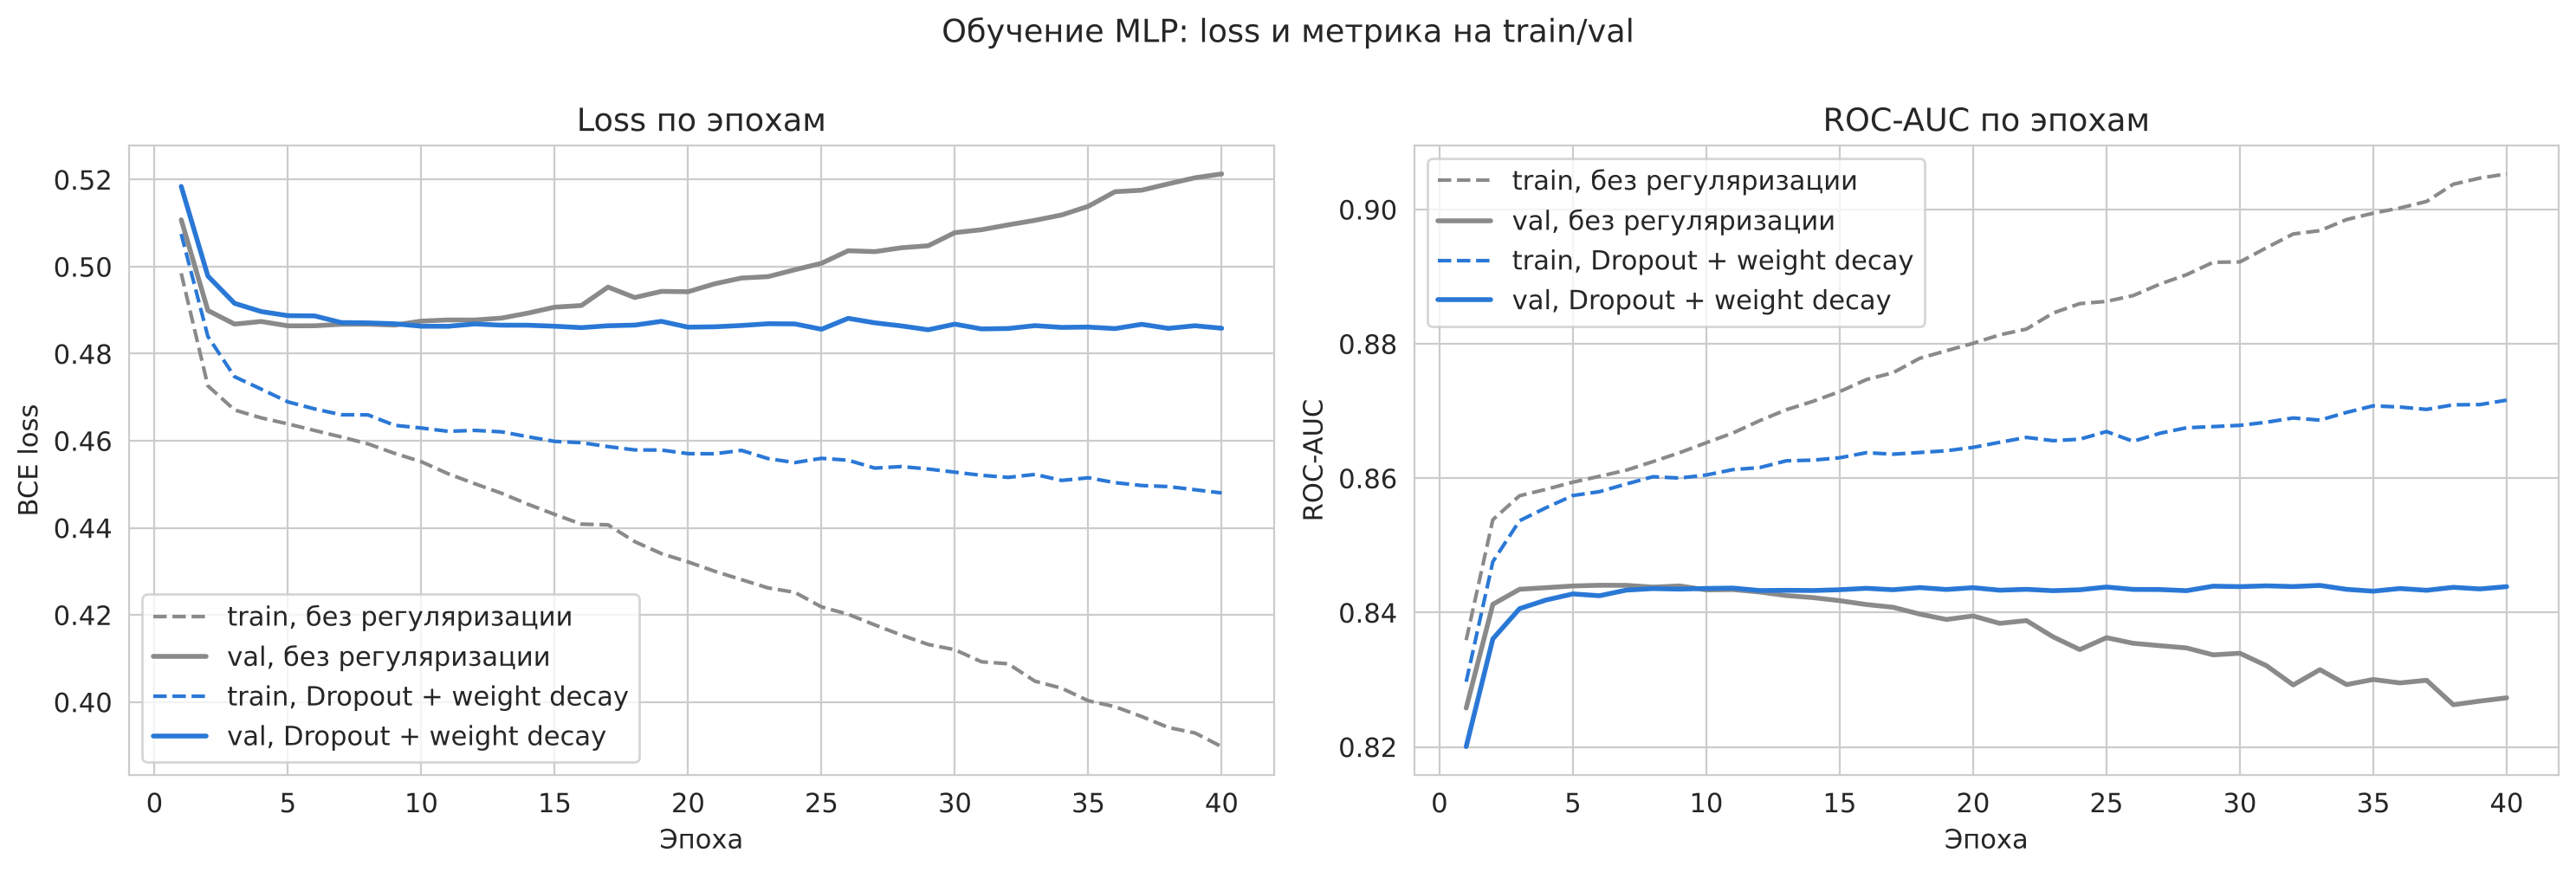

Без регуляризации: лучшая эпоха 5 (val loss 0.4864, val ROC-AUC 0.8440); на последней эпохе train loss 0.3897, val loss 0.5213, val ROC-AUC 0.8273
С регуляризацией: лучшая эпоха 29 (val loss 0.4855, val ROC-AUC 0.8439); на последней эпохе train loss 0.4480, val loss 0.4858, val ROC-AUC 0.8438


In [38]:
MLP_HIDDEN = (32,)
MAX_EPOCHS = 40

model_noreg, hist_noreg = train_mlp(X_main_p, y_main, X_val_p, y_val, hidden=MLP_HIDDEN,
                                    dropout=0.0, weight_decay=0.0, epochs=MAX_EPOCHS)
model_reg, hist_reg = train_mlp(X_main_p, y_main, X_val_p, y_val, hidden=MLP_HIDDEN,
                                dropout=MLP_DROPOUT, weight_decay=MLP_WD, epochs=MAX_EPOCHS)

epochs_axis = range(1, MAX_EPOCHS + 1)
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for hist, color, name in [(hist_noreg, '#8a8a8a', 'без регуляризации'), (hist_reg, C_MAIN, 'Dropout + weight decay')]:
    axes[0].plot(epochs_axis, hist['train_loss'], color=color, linestyle='--', label=f'train, {name}')
    axes[0].plot(epochs_axis, hist['val_loss'], color=color, linewidth=2, label=f'val, {name}')
    axes[1].plot(epochs_axis, hist['train_auc'], color=color, linestyle='--', label=f'train, {name}')
    axes[1].plot(epochs_axis, hist['val_auc'], color=color, linewidth=2, label=f'val, {name}')
axes[0].set_title('Loss по эпохам')
axes[0].set_ylabel('BCE loss')
axes[1].set_title('ROC-AUC по эпохам')
axes[1].set_ylabel('ROC-AUC')
for ax in axes:
    ax.set_xlabel('Эпоха')
    ax.legend()
plt.suptitle('Обучение MLP: loss и метрика на train/val', y=1.0)
plt.tight_layout()
plt.savefig('figures/mlp_curves.png', dpi=150, bbox_inches='tight')
plt.show()

for title, hist in [('Без регуляризации', hist_noreg), ('С регуляризацией', hist_reg)]:
    best = int(np.argmin(hist['val_loss']))
    print(f"{title}: лучшая эпоха {best + 1} (val loss {hist['val_loss'][best]:.4f}, val ROC-AUC {hist['val_auc'][best]:.4f}); "
          f"на последней эпохе train loss {hist['train_loss'][-1]:.4f}, val loss {hist['val_loss'][-1]:.4f}, "
          f"val ROC-AUC {hist['val_auc'][-1]:.4f}")

### 6.3 Финальная MLP

Число эпох берём по минимуму val loss для модели с регуляризацией. Затем, как и для классических моделей, считаем 5-fold CV на train и метрики на test. В каждом фолде предобработка обучается заново.

In [39]:
BEST_EPOCHS = int(np.argmin(hist_reg['val_loss'])) + 1
print('Число эпох:', BEST_EPOCHS)


def fit_predict_mlp(X_tr, y_tr, X_te, epochs=None):
    """Предобработка + обучение MLP на X_tr, вероятности для X_te."""
    prep = make_prep()
    A = prep.fit_transform(X_tr)
    B = prep.transform(X_te)
    model, _ = train_mlp(A, y_tr, hidden=MLP_HIDDEN, dropout=MLP_DROPOUT, weight_decay=MLP_WD, epochs=epochs or BEST_EPOCHS)
    return mlp_proba(model, B)


def cv_mlp(X, y):
    """ROC-AUC MLP на каждом из 5 фолдов."""
    scores = []
    for tr_idx, va_idx in cv.split(X, y):
        proba = fit_predict_mlp(X.iloc[tr_idx], y.iloc[tr_idx], X.iloc[va_idx])
        scores.append(roc_auc_score(y.iloc[va_idx], proba))
    return scores


# 5-fold CV
mlp_cv = cv_mlp(X_train, y_train)

# обучение на всём train и тест
t0 = time.time()
mlp_test_proba = fit_predict_mlp(X_train, y_train, X_test)
add_result('MLP (PyTorch)', mlp_cv, time.time() - t0, mlp_test_proba)

Число эпох: 29


MLP (PyTorch): CV ROC-AUC = 0.8493 ± 0.0062 | test ROC-AUC = 0.8460, accuracy = 0.7634, F1 = 0.7733 | 6.1 c


**Итоги по MLP.**

- **Без регуляризации сеть переобучается.** Loss на обучении падает все 40 эпох (до 0,390), а на валидации минимум достигается уже на 5-й эпохе (0,4864) и дальше растёт до 0,521; val ROC-AUC падает с 0,844 до 0,827.
- **С Dropout 0,5 и weight decay 1e-3** разрыв между train и val намного меньше, а val loss выходит на плато и не растёт: 0,4855 на лучшей, 29-й эпохе и 0,4858 на 40-й.
- Лучшее качество в обоих случаях одинаково (val ROC-AUC 0,844). Регуляризация здесь не повышает потолок, а делает обучение устойчивым: результат перестаёт зависеть от того, на какой эпохе мы остановимся.
- Финальная MLP: CV ROC-AUC 0,8493 ± 0,0062, test ROC-AUC 0,8460 — на уровне логистической регрессии.

## 7. Stacking и Blending

**Stacking:** базовые модели (логистическая регрессия, Random Forest, бустинг) дают out-of-fold предсказания, на которых обучается мета-модель — логистическая регрессия.

**Blending:** усредняем вероятности четырёх моделей (включая MLP) с весами. Веса подбираем на отложенной валидационной части.

In [40]:
from sklearn.ensemble import StackingClassifier

stacking = StackingClassifier(
    estimators=[('logreg', clone(best_lr)), ('rf', clone(best_rf)), ('gb', clone(best_gb))],
    final_estimator=LogisticRegression(max_iter=1000),
    cv=5, stack_method='predict_proba')
stacking = evaluate('Stacking (LR + RF + GB)', stacking)

print('Веса мета-модели:', dict(zip(['logreg', 'rf', 'gb'], stacking.final_estimator_.coef_[0].round(2))))

Stacking (LR + RF + GB): CV ROC-AUC = 0.8509 ± 0.0061 | test ROC-AUC = 0.8470, accuracy = 0.7603, F1 = 0.7705 | 68.8 c
Веса мета-модели: {'logreg': np.float64(4.47), 'rf': np.float64(0.64), 'gb': np.float64(0.29)}


In [41]:
# === Blending ===
# Базовые модели обучаем на X_main, веса подбираем на X_val, проверяем на test
blend_models = {'LogReg': clone(best_lr), 'RF': clone(best_rf), 'GB': clone(best_gb)}
val_pred, test_pred = {}, {}

t0 = time.time()
for name, model in blend_models.items():
    model.fit(X_main, y_main)
    val_pred[name] = model.predict_proba(X_val)[:, 1]
    test_pred[name] = model.predict_proba(X_test)[:, 1]

mlp_blend, _ = train_mlp(X_main_p, y_main, hidden=MLP_HIDDEN, dropout=MLP_DROPOUT, weight_decay=MLP_WD, epochs=BEST_EPOCHS)
val_pred['MLP'] = mlp_proba(mlp_blend, X_val_p)
test_pred['MLP'] = mlp_proba(mlp_blend, prep_mlp.transform(X_test))
blend_time = time.time() - t0

for name in val_pred:
    print(f'{name:7s} val ROC-AUC = {roc_auc_score(y_val, val_pred[name]):.4f}')

# перебираем веса с шагом 0.1 (сумма весов = 1)
names = list(val_pred)
best_w, best_auc = None, 0
grid = np.arange(0, 1.01, 0.1)
for w1 in grid:
    for w2 in grid:
        for w3 in grid:
            w4 = 1 - w1 - w2 - w3
            if w4 < -1e-9:
                continue
            w = [w1, w2, w3, max(w4, 0)]
            auc = roc_auc_score(y_val, sum(wi * val_pred[n] for wi, n in zip(w, names)))
            if auc > best_auc:
                best_w, best_auc = w, auc
print('Лучшие веса:', dict(zip(names, np.round(best_w, 1))), f'| val ROC-AUC = {best_auc:.4f}')

blend_simple = sum(test_pred[n] for n in names) / len(names)
blend_weighted = sum(wi * test_pred[n] for wi, n in zip(best_w, names))

# у блендинга нет 5-fold CV: его веса подбирались на одной отложенной части, поэтому CV-столбец пустой
for name, proba in [('Blending: среднее', blend_simple), ('Blending: веса', blend_weighted)]:
    add_result(name, [np.nan], blend_time, proba)

LogReg  val ROC-AUC = 0.8450
RF      val ROC-AUC = 0.8249
GB      val ROC-AUC = 0.8393
MLP     val ROC-AUC = 0.8439


Лучшие веса: {'LogReg': np.float64(0.7), 'RF': np.float64(0.0), 'GB': np.float64(0.0), 'MLP': np.float64(0.3)} | val ROC-AUC = 0.8452
Blending: среднее: CV ROC-AUC = nan ± nan | test ROC-AUC = 0.8452, accuracy = 0.7611, F1 = 0.7715 | 15.6 c
Blending: веса: CV ROC-AUC = nan ± nan | test ROC-AUC = 0.8457, accuracy = 0.7595, F1 = 0.7699 | 15.6 c


## 8. Сравнение моделей (20-я минута)

In [42]:
comparison = pd.DataFrame(results).set_index('Модель')
comparison.to_csv('results/comparison_stage20.csv')
comparison.sort_values('Test ROC-AUC', ascending=False).round(4)

,CV ROC-AUC,CV std,Test Accuracy,Test F1,Test ROC-AUC,"Время обучения, с"
Модель,,,,,,
Stacking (LR + RF + GB),0.8509,0.0061,0.7603,0.7705,0.8470,68.8171
Logistic Regression,0.8510,0.0062,0.7588,0.7694,0.8466,0.4798
MLP (PyTorch),0.8493,0.0062,0.7634,0.7733,0.8460,6.0824
Blending: веса,NaN,NaN,0.7595,0.7699,0.8457,15.5760
Blending: среднее,NaN,NaN,0.7611,0.7715,0.8452,15.5760
Gradient Boosting,0.8455,0.0057,0.7573,0.7680,0.8431,3.8974
Random Forest,0.8305,0.0052,0.7523,0.7642,0.8320,8.2387
Baseline: LogReg без драфта,0.8215,0.0061,0.7442,0.7559,0.8239,0.0749
Decision Tree,0.8183,0.0067,0.7408,0.7511,0.8188,0.7805


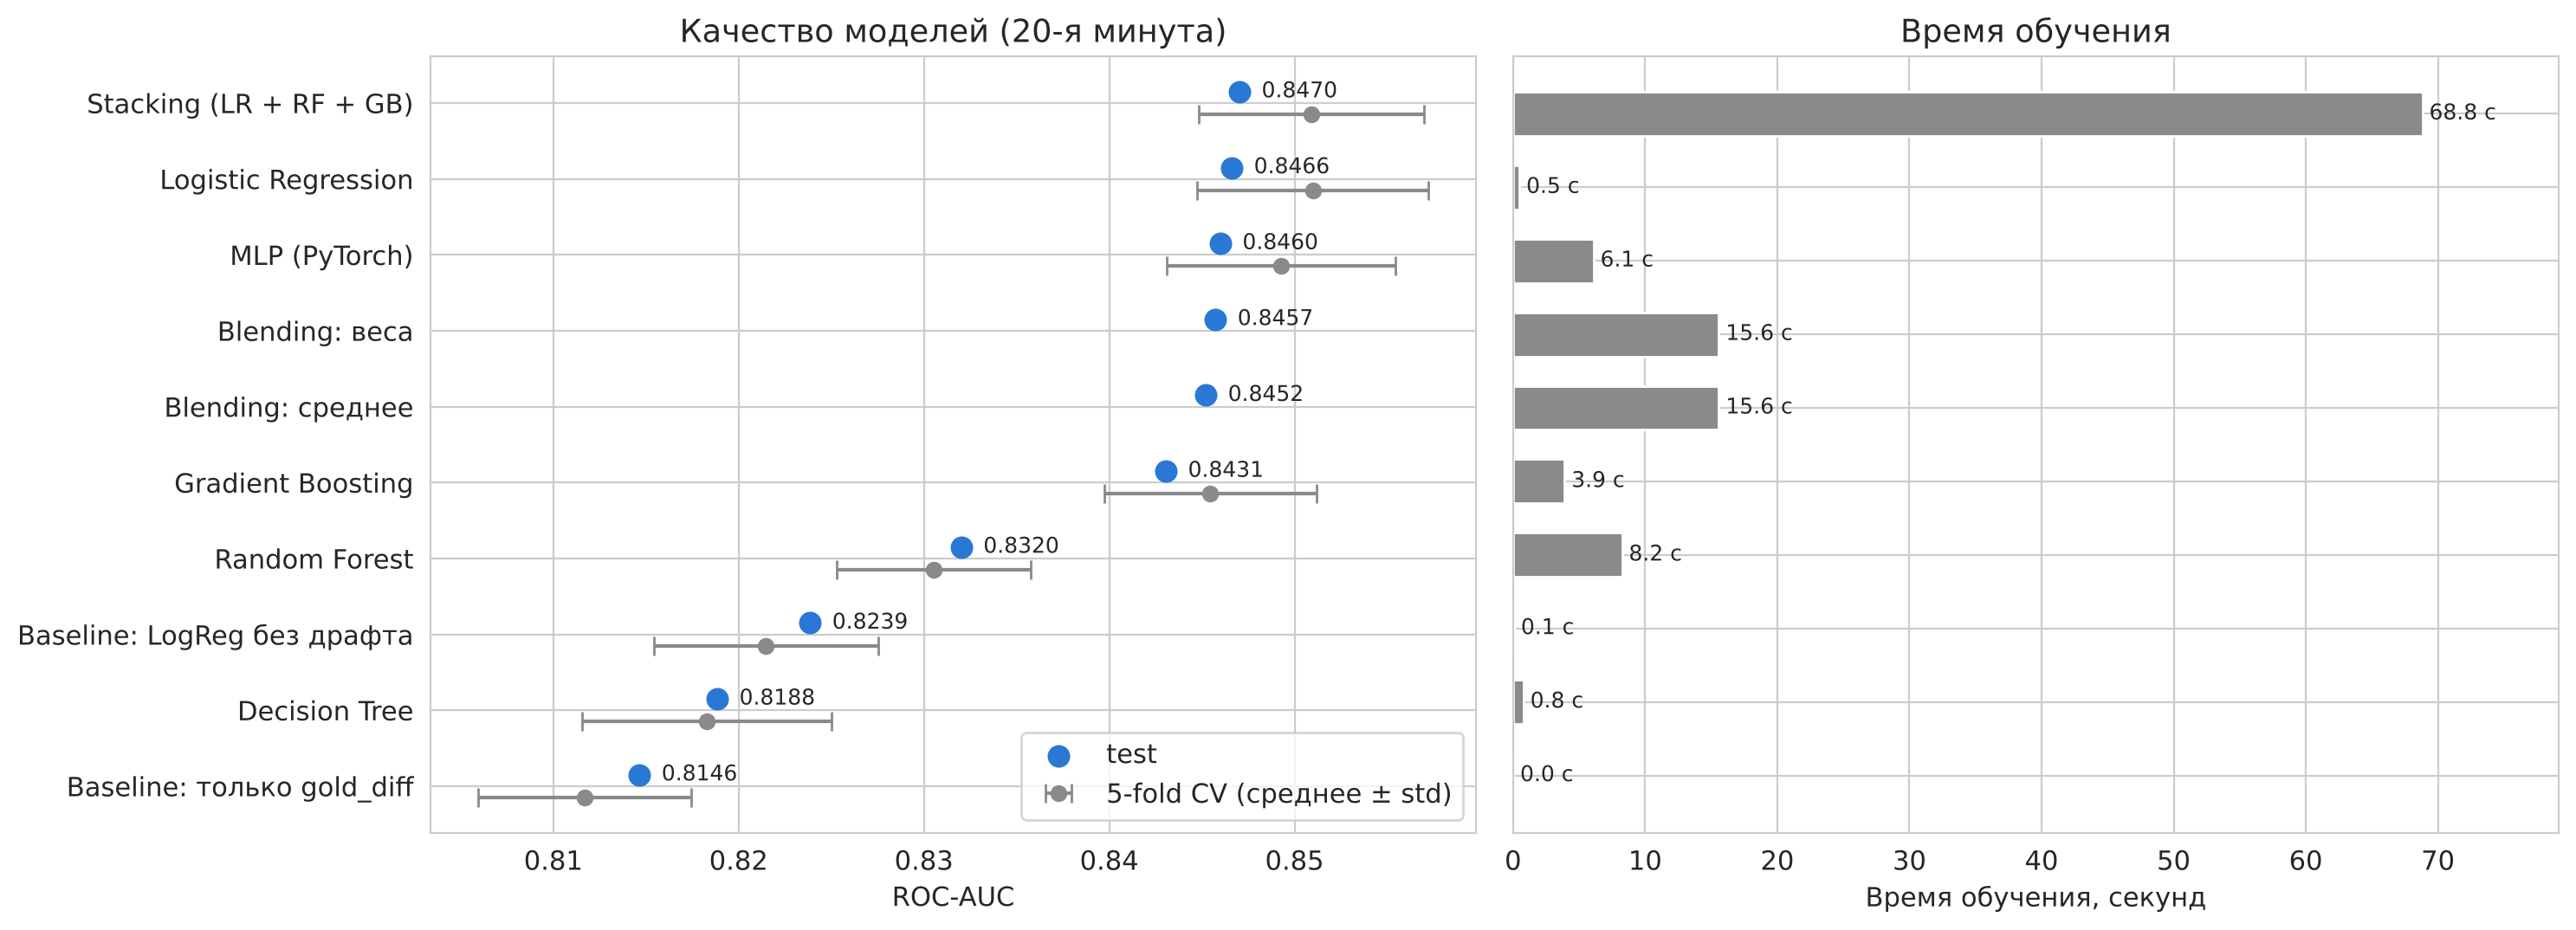

In [43]:
plot_df = comparison.drop(index='Baseline: частый класс').sort_values('Test ROC-AUC')
y_pos = np.arange(len(plot_df))
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

axes[0].errorbar(plot_df['CV ROC-AUC'], y_pos - 0.15, xerr=plot_df['CV std'], fmt='o', color='#8a8a8a',
                 capsize=4, label='5-fold CV (среднее ± std)')
axes[0].scatter(plot_df['Test ROC-AUC'], y_pos + 0.15, color=C_MAIN, s=70, zorder=3, label='test')
for i, v in enumerate(plot_df['Test ROC-AUC']):
    axes[0].text(v + 0.0012, i + 0.15, f'{v:.4f}', va='center', fontsize=9)
axes[0].set_yticks(y_pos)
axes[0].set_yticklabels(plot_df.index)
axes[0].set_xlabel('ROC-AUC')
axes[0].set_title('Качество моделей (20-я минута)')
axes[0].legend(loc='lower right')

axes[1].barh(y_pos, plot_df['Время обучения, с'], color='#8a8a8a', height=0.6)
for i, v in enumerate(plot_df['Время обучения, с']):
    axes[1].text(v, i, f' {v:.1f} c', va='center', fontsize=9)
axes[1].set_xlim(0, plot_df['Время обучения, с'].max() * 1.15)
axes[1].set_yticks(y_pos)
axes[1].set_yticklabels([])
axes[1].set_xlabel('Время обучения, секунд')
axes[1].set_title('Время обучения')
plt.tight_layout()
plt.savefig('figures/model_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

**Как читать таблицу.**

- Время обучения — это время одного обучения на всём train с уже выбранными гиперпараметрами; сам перебор в него не входит. У MLP и блендинга в это время входит ещё и предсказание на тесте, у стекинга — внутренняя кросс-валидация базовых моделей.
- У блендинга базовые модели обучены на 80% train (28,9 тыс. матчей), потому что остальные 20% нужны для подбора весов. Остальные модели обучены на всём train.

**Анализ: почему одни модели лучше других.**

1. **Лидеры неразличимы.** Stacking (0,8470), логистическая регрессия (0,8466), MLP (0,8460) и blending (0,8457) расходятся меньше чем на 0,002 по test ROC-AUC при разбросе по фолдам около 0,006. Утверждать, что одна из них лучше, нельзя.
2. **Почему простая линейная модель оказалась наверху.** Это видно из данных: у задачи почти линейная структура.
   - Главный сигнал — перевес по золоту и опыту, и вероятность победы растёт с ним монотонно. Одна логистическая регрессия на `gold_diff` уже даёт 0,8146.
   - Мета-модель стекинга дала логистической регрессии коэффициент 4,5 против 0,6 и 0,3 у леса и бустинга, а при подборе весов блендинга лес и бустинг получили 0. То есть нелинейные модели не нашли ничего, чего не видит линейная.
3. **Почему деревья хуже — факты и вероятная причина.**
   - Факт: одиночное дерево (0,8188) хуже даже логистической регрессии без драфта (0,8239), то есть 220 столбцов героев оно почти не использует.
   - Факт: Random Forest (0,8320) не становится лучше, если давать ему больше признаков на каждое разбиение (`max_features` 0,2 и 0,4 дают те же 0,830). Значит, дело не в том, что сигнал золота «теряется» среди столбцов героев.
   - Вероятная причина (отдельно не проверялась): вклад героя мал и аддитивен, а одно разбиение дерева по столбцу героя отделяет несколько процентов матчей. Чтобы учесть 220 таких поправок, нужны очень глубокие деревья, а они переобучаются. Бустинг (0,8431) ближе к линейной модели, потому что складывает сотни маленьких деревьев, и малые поправки накапливаются.
4. **Почему MLP не выиграла.** Факт: сеть вышла на тот же уровень, что логистическая регрессия, а без регуляризации переобучается. Вероятная причина (не проверялась): преимущество сети — взаимодействия признаков, например синергия героев, но пар героев тысячи, а матчей 36 тысяч, и надёжно выучить их не из чего.
5. **Ансамбли не дали прироста.** Stacking и blending помогают, когда модели ошибаются по-разному. Здесь сильные модели выучили один и тот же сигнал — это видно по весам из пункта 2.
6. **Цена.** Логистическая регрессия обучается за полсекунды, стекинг — больше минуты при том же качестве. Для практики разумный выбор — логистическая регрессия: быстро, интерпретируемо и, как показано в разделе 11.2, с хорошо откалиброванными вероятностями.

## 9. Разные стадии матча

Обучаем те же модели с теми же гиперпараметрами на данных 10-й, 20-й и 30-й минуты. Гиперпараметры подобраны на 20-й минуте и не меняются, чтобы стадии сравнивались при одинаковых настройках. Для каждой стадии считаем 5-fold CV на train и метрики на test.

Разбиение матчей на train и test одно и то же, но на каждой стадии в таблице остаются только матчи, которые к этой минуте ещё идут. Поэтому тестовые наборы разного размера, и к 30-й минуте короткие матчи из них выбывают.

In [44]:
stage_models = {'Logistic Regression': best_lr, 'Decision Tree': best_dt,
                'Random Forest': best_rf, 'Gradient Boosting': best_gb}
stage_rows = []
stage_fitted = {}       # обученные модели по стадиям - понадобятся для важности признаков


def stage_row(minute, name, cv_scores, y_true, proba):
    row = {'Минута': minute, 'Модель': name, 'CV ROC-AUC': np.mean(cv_scores), 'CV std': np.std(cv_scores)}
    row.update(test_metrics(y_true, proba))
    return row


for minute in STAGES:
    X_tr, y_tr, X_te, y_te = get_split(minute)

    # baseline: только gold_diff
    base = make_pipe(LogisticRegression(max_iter=1000), cols=['gold_diff'])
    cv_scores = cross_val_score(base, X_tr, y_tr, cv=cv, scoring='roc_auc')
    base.fit(X_tr, y_tr)
    stage_rows.append(stage_row(minute, 'Baseline: только gold_diff', cv_scores, y_te, base.predict_proba(X_te)[:, 1]))

    for name, model in stage_models.items():
        cv_scores = cross_val_score(clone(model), X_tr, y_tr, cv=cv, scoring='roc_auc')
        m = clone(model).fit(X_tr, y_tr)
        stage_fitted[(minute, name)] = m
        stage_rows.append(stage_row(minute, name, cv_scores, y_te, m.predict_proba(X_te)[:, 1]))

    stage_rows.append(stage_row(minute, 'MLP (PyTorch)', cv_mlp(X_tr, y_tr), y_te, fit_predict_mlp(X_tr, y_tr, X_te)))
    print(f'{minute}-я минута: train {len(X_tr)}, test {len(X_te)}, доля побед Radiant в test {y_te.mean():.3f} - готово')

stage_table = pd.DataFrame(stage_rows)
stage_table.to_csv('results/stages.csv', index=False)
stage_table['CV'] = stage_table['CV ROC-AUC'].map('{:.4f}'.format) + ' ± ' + stage_table['CV std'].map('{:.4f}'.format)
stage_cv = stage_table.pivot(index='Модель', columns='Минута', values='CV')
stage_auc = stage_table.pivot(index='Модель', columns='Минута', values='Test ROC-AUC')
stage_acc = stage_table.pivot(index='Модель', columns='Минута', values='Test Accuracy')
order_cv = stage_table[stage_table['Минута'] == MAIN_STAGE].sort_values('CV ROC-AUC', ascending=False)['Модель']
print('CV ROC-AUC (5 фолдов, среднее ± std):')
display(stage_cv.loc[order_cv])
print('Test ROC-AUC:')
display(stage_auc.loc[order_cv].round(4))
print('Test Accuracy:')
display(stage_acc.loc[order_cv].round(4))

10-я минута: train 36298, test 9075, доля побед Radiant в test 0.519 - готово


20-я минута: train 36146, test 9040, доля побед Radiant в test 0.519 - готово


30-я минута: train 31895, test 7983, доля побед Radiant в test 0.506 - готово
CV ROC-AUC (5 фолдов, среднее ± std):


Минута,10,20,30
Модель,,,
Logistic Regression,0.7602 ± 0.0082,0.8510 ± 0.0062,0.9067 ± 0.0035
MLP (PyTorch),0.7582 ± 0.0086,0.8493 ± 0.0062,0.9055 ± 0.0035
Gradient Boosting,0.7517 ± 0.0082,0.8455 ± 0.0057,0.9028 ± 0.0039
Random Forest,0.7300 ± 0.0080,0.8305 ± 0.0052,0.8944 ± 0.0037
Decision Tree,0.7091 ± 0.0084,0.8183 ± 0.0067,0.8858 ± 0.0032
Baseline: только gold_diff,0.7027 ± 0.0068,0.8117 ± 0.0058,0.8832 ± 0.0043


Test ROC-AUC:


Минута,10,20,30
Модель,,,
Logistic Regression,0.7547,0.8466,0.9056
MLP (PyTorch),0.7518,0.8460,0.9042
Gradient Boosting,0.7477,0.8431,0.9042
Random Forest,0.7270,0.8320,0.8963
Decision Tree,0.7056,0.8188,0.8859
Baseline: только gold_diff,0.7009,0.8146,0.8864


Test Accuracy:


Минута,10,20,30
Модель,,,
Logistic Regression,0.6902,0.7588,0.8169
MLP (PyTorch),0.6908,0.7634,0.8165
Gradient Boosting,0.6840,0.7573,0.8157
Random Forest,0.6691,0.7523,0.8108
Decision Tree,0.6532,0.7408,0.7973
Baseline: только gold_diff,0.6515,0.7336,0.7957


Только драфт, до начала матча: test ROC-AUC = 0.6385


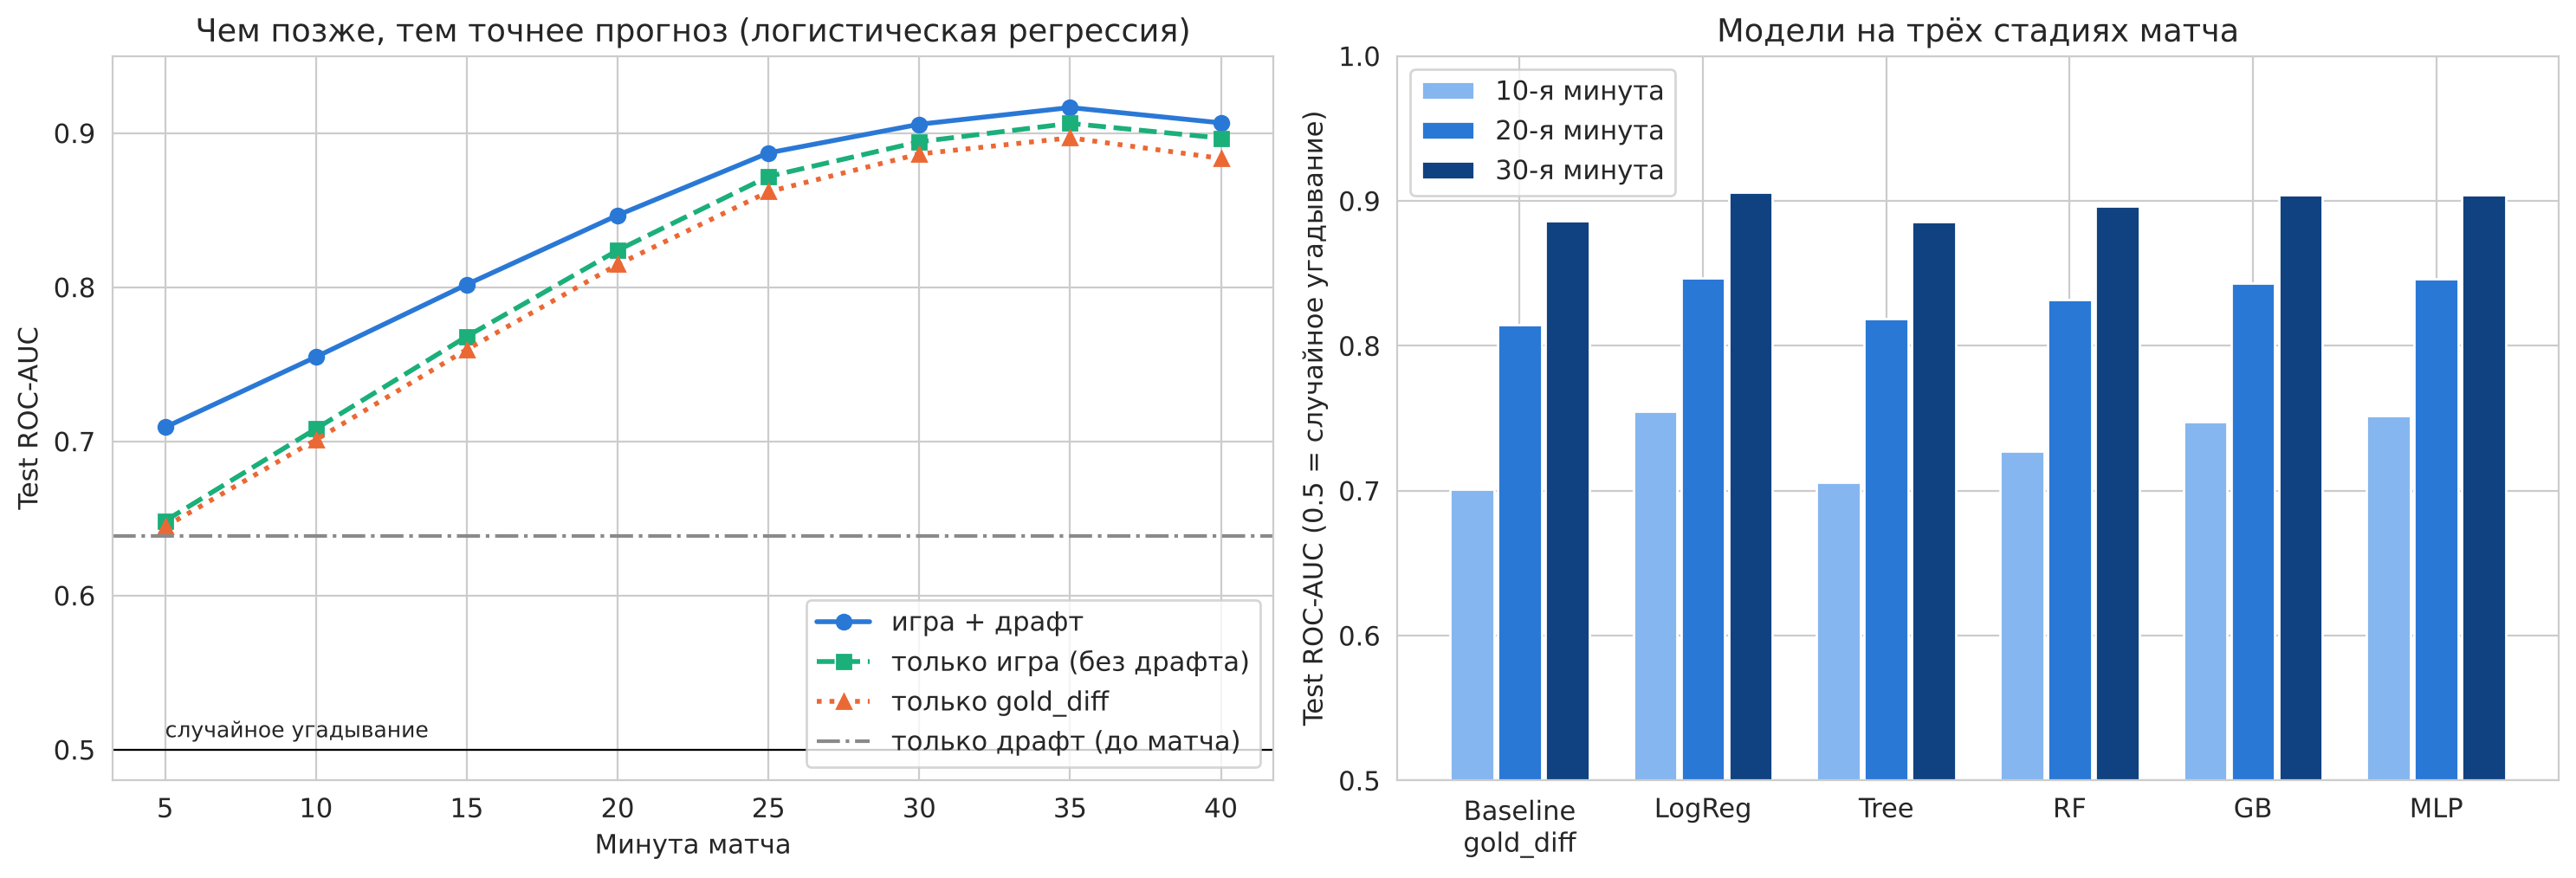

,Матчей в тесте,Игра + драфт,Только игра (без драфта),Только gold_diff,Только драфт (до матча)
Минута,,,,,
5,9075,0.7090,0.6483,0.6446,0.6385
10,9075,0.7547,0.7081,0.7009,0.6385
15,9071,0.8017,0.7680,0.7595,0.6385
20,9040,0.8466,0.8238,0.8146,0.6385
25,8812,0.8871,0.8718,0.8618,0.6385
30,7983,0.9056,0.8943,0.8864,0.6385
35,6490,0.9165,0.9062,0.8968,0.6385
40,4614,0.9065,0.8966,0.8835,0.6385


In [45]:
# Как растёт предсказуемость исхода с течением матча: каждые 5 минут
C_best = grid_lr.best_params_['model__C']
curve_sets = {'Игра + драфт': features, 'Только игра (без драфта)': game_features, 'Только gold_diff': ['gold_diff']}
curve_rows = []
for minute in range(5, 41, 5):
    table = add_draft(build_stage(minute))
    train = table[table['match_id'].isin(train_ids)]
    test = table[table['match_id'].isin(test_ids)]
    row = {'Минута': minute, 'Матчей в тесте': len(test)}
    for set_name, cols in curve_sets.items():
        model = make_pipe(LogisticRegression(C=C_best, max_iter=2000), cols=cols).fit(train[cols], train[target])
        row[set_name] = roc_auc_score(test[target], model.predict_proba(test[cols])[:, 1])
    curve_rows.append(row)
curve = pd.DataFrame(curve_rows).set_index('Минута')

# точка отсчёта: только драфт, то есть прогноз до начала матча
X_tr10, y_tr10, X_te10, y_te10 = get_split(10)
draft_only = make_pipe(LogisticRegression(C=C_best, max_iter=2000), cols=hero_features).fit(X_tr10, y_tr10)
draft_auc = roc_auc_score(y_te10, draft_only.predict_proba(X_te10)[:, 1])
curve['Только драфт (до матча)'] = draft_auc
curve.to_csv('results/auc_by_minute.csv')
print(f'Только драфт, до начала матча: test ROC-AUC = {draft_auc:.4f}')

fig, axes = plt.subplots(1, 2, figsize=(15, 5.2))
axes[0].plot(curve.index, curve['Игра + драфт'], marker='o', linewidth=2, color=C_MAIN, label='игра + драфт')
axes[0].plot(curve.index, curve['Только игра (без драфта)'], marker='s', linewidth=2, linestyle='--', color=C_RAD, label='только игра (без драфта)')
axes[0].plot(curve.index, curve['Только gold_diff'], marker='^', linewidth=2, linestyle=':', color=C_DIRE, label='только gold_diff')
axes[0].axhline(draft_auc, color='#8a8a8a', linewidth=1.5, linestyle='-.', label='только драфт (до матча)')
axes[0].axhline(0.5, color='black', linewidth=0.8)
axes[0].text(5, 0.508, 'случайное угадывание', fontsize=9)
axes[0].set_ylim(0.48, 0.95)
axes[0].set_xlabel('Минута матча')
axes[0].set_ylabel('Test ROC-AUC')
axes[0].set_title('Чем позже, тем точнее прогноз (логистическая регрессия)')
axes[0].legend(loc='lower right')

order = ['Baseline: только gold_diff', 'Logistic Regression', 'Decision Tree', 'Random Forest', 'Gradient Boosting', 'MLP (PyTorch)']
width = 0.26
for i, minute in enumerate(STAGES):
    axes[1].bar(np.arange(len(order)) + (i - 1) * width, stage_auc.loc[order, minute] - 0.5, bottom=0.5,
                width=width * 0.92, color=STAGE_COLORS[minute], label=f'{minute}-я минута')
axes[1].set_xticks(np.arange(len(order)))
axes[1].set_xticklabels(['Baseline\ngold_diff', 'LogReg', 'Tree', 'RF', 'GB', 'MLP'])
axes[1].set_ylim(0.5, 1.0)
axes[1].set_ylabel('Test ROC-AUC (0.5 = случайное угадывание)')
axes[1].set_title('Модели на трёх стадиях матча')
axes[1].legend(loc='upper left')
plt.tight_layout()
plt.savefig('figures/stages.png', dpi=150, bbox_inches='tight')
plt.show()

curve.round(4)

**Выводы по стадиям.**

- **Чем позже, тем точнее.** Логистическая регрессия: CV ROC-AUC 0,760 → 0,851 → 0,907, test ROC-AUC 0,755 → 0,847 → 0,906, test accuracy 69,0% → 75,9% → 81,7%.
- **Часть этого роста — эффект отбора.** Стадии сравниваются на разных наборах матчей: в тесте 9 075 матчей на 10-й минуте, 9 040 на 20-й и 7 983 на 30-й. К 30-й минуте из выборки выбывают матчи, которые уже закончились, то есть самые односторонние. Поэтому «0,906 на 30-й минуте» — это качество на матчах, которые дожили до 30-й минуты, а не на всех.
- **Три сильные модели неразличимы на всех стадиях.** По кросс-валидации логистическая регрессия и MLP расходятся на 0,001–0,002 при разбросе по фолдам 0,004–0,009. Бустинг отстаёт от регрессии на 0,009, 0,006 и 0,004 — это около одного стандартного отклонения, уверенно разделить их нельзя.
- **Random Forest и дерево отстают на всех стадиях** сильнее разброса по фолдам: лес на 0,030, 0,021 и 0,012, дерево на 0,051, 0,033 и 0,021 (CV). Разрыв сокращается к поздним стадиям.
- **Драфт важнее всего в начале.** До начала матча один драфт даёт 0,638 (test). Прибавка от драфта к игровым признакам на тесте: +0,061 на 5-й минуте, +0,047 на 10-й, +0,023 на 20-й, +0,011 на 30-й.
- **После 35-й минуты качество падает** (0,9165 → 0,9065 на 40-й). Это тот же эффект отбора: до 40-й минуты доживает только половина матчей, причём самые равные.

## 10. Важность признаков по стадиям

Используем **permutation importance** на тесте: насколько падает ROC-AUC, если перемешать значения признака. Считаем для бустинга: он учитывает нелинейности и взаимодействия признаков, а по качеству близок к лучшей модели. Взгляд линейной модели дан отдельно — через коэффициенты логистической регрессии. Идея та же, что в `sklearn.inspection.permutation_importance`, но написана вручную, чтобы можно было перемешивать **группу столбцов разом**:

- драфт — это 220 столбцов, по одному они почти ничего не значат, а вместе — один признак «состав команд»;
- коррелирующие признаки (`gold_diff`, `xp_diff`, `kills_diff`) делят важность между собой: если перемешать один, модель восстановит информацию по остальным. Перемешивание всей группы показывает её настоящий вклад.

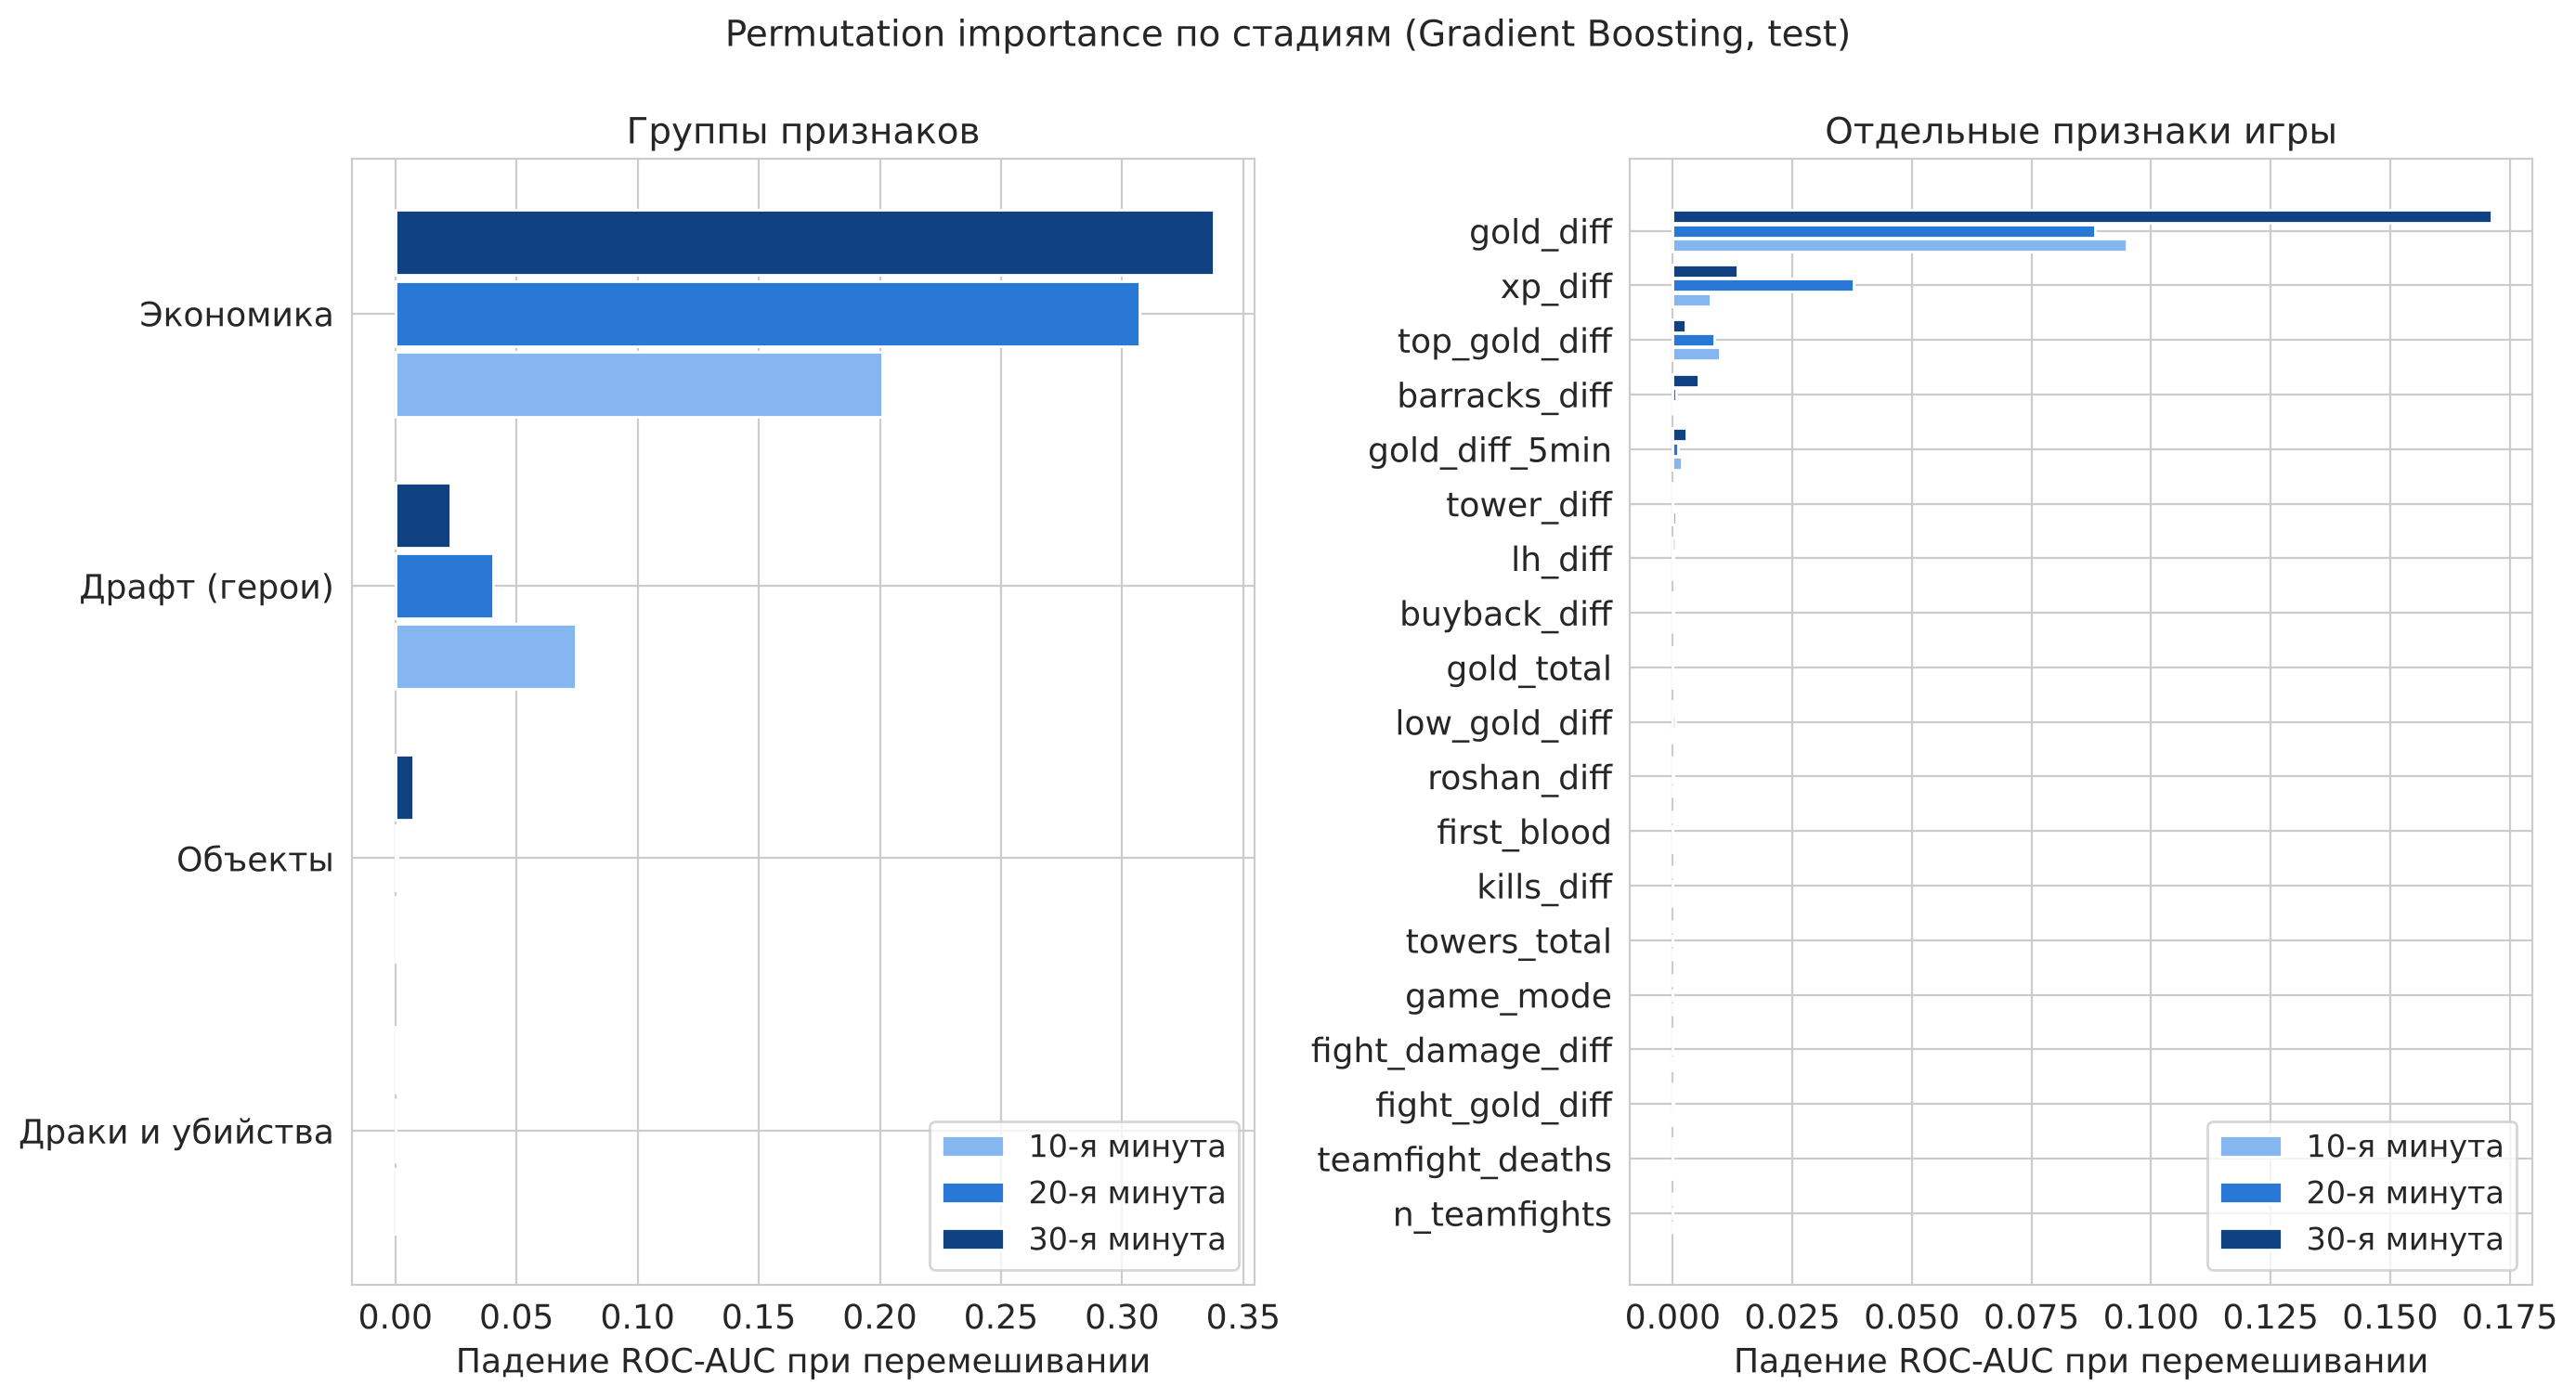

Группы признаков:


,10,20,30
Экономика,0.2011,0.3071,0.3377
Драфт (герои),0.0745,0.0402,0.0229
Объекты,0.0009,0.0010,0.0073
Драки и убийства,-0.0009,0.0001,0.0006


Отдельные признаки:


,10,20,30
gold_diff,0.0949,0.0882,0.1711
xp_diff,0.0079,0.0379,0.0136
top_gold_diff,0.0099,0.0086,0.0027
gold_diff_5min,0.0018,0.0012,0.0029
barracks_diff,0.0000,0.0007,0.0053
low_gold_diff,-0.0003,0.0005,0.0001
buyback_diff,0.0000,0.0002,0.0003
roshan_diff,0.0000,0.0001,0.0000
fight_gold_diff,-0.0003,0.0001,0.0002
lh_diff,0.0000,0.0000,0.0005


In [46]:
def permutation_drop(model, X, y, cols, n_repeats=5):
    """Среднее падение ROC-AUC на (X, y), если перемешать строки в столбцах cols."""
    rng = np.random.RandomState(RANDOM_STATE)
    base = roc_auc_score(y, model.predict_proba(X)[:, 1])
    drops = []
    for _ in range(n_repeats):
        X_perm = X.copy()
        X_perm[cols] = X[cols].values[rng.permutation(len(X))]
        drops.append(base - roc_auc_score(y, model.predict_proba(X_perm)[:, 1]))
    return np.mean(drops)


groups = {
    'Экономика': ['gold_diff', 'xp_diff', 'lh_diff', 'gold_total', 'gold_diff_5min', 'top_gold_diff', 'low_gold_diff'],
    'Объекты': ['tower_diff', 'towers_total', 'roshan_diff', 'barracks_diff', 'first_blood'],
    'Драки и убийства': ['kills_diff', 'fight_gold_diff', 'fight_damage_diff', 'buyback_diff', 'n_teamfights', 'teamfight_deaths'],
    'Драфт (герои)': hero_features,
}
IMPORTANCE_MODEL = 'Gradient Boosting'

group_rows, single_rows = {}, {}
for minute in STAGES:
    X_tr, y_tr, X_te, y_te = get_split(minute)
    model = stage_fitted[(minute, IMPORTANCE_MODEL)]
    group_rows[minute] = {name: permutation_drop(model, X_te, y_te, cols) for name, cols in groups.items()}
    single_rows[minute] = {col: permutation_drop(model, X_te, y_te, [col]) for col in game_features}
group_imp = pd.DataFrame(group_rows)
single_imp = pd.DataFrame(single_rows)
group_imp.to_csv('results/importance_groups.csv')
single_imp.to_csv('results/importance_features.csv')

fig, axes = plt.subplots(1, 2, figsize=(14, 7.5))
height = 0.26
for ax, table, title in [(axes[0], group_imp, 'Группы признаков'), (axes[1], single_imp, 'Отдельные признаки игры')]:
    order = table.mean(axis=1).sort_values().index
    for i, minute in enumerate(STAGES):
        ax.barh(np.arange(len(order)) + (i - 1) * height, table.loc[order, minute], height=height * 0.92,
                color=STAGE_COLORS[minute], label=f'{minute}-я минута')
    ax.set_yticks(np.arange(len(order)))
    ax.set_yticklabels(order)
    ax.set_xlabel('Падение ROC-AUC при перемешивании', fontsize=13)
    ax.set_title(title, fontsize=14)
    ax.tick_params(labelsize=13)
    ax.legend(loc='lower right', fontsize=12)
plt.suptitle(f'Permutation importance по стадиям ({IMPORTANCE_MODEL}, test)', y=1.0, fontsize=14)
plt.tight_layout()
plt.savefig('figures/permutation_importance.png', dpi=150, bbox_inches='tight')
plt.show()

print('Группы признаков:')
display(group_imp.sort_values(20, ascending=False).round(4))
print('Отдельные признаки:')
display(single_imp.sort_values(20, ascending=False).round(4))

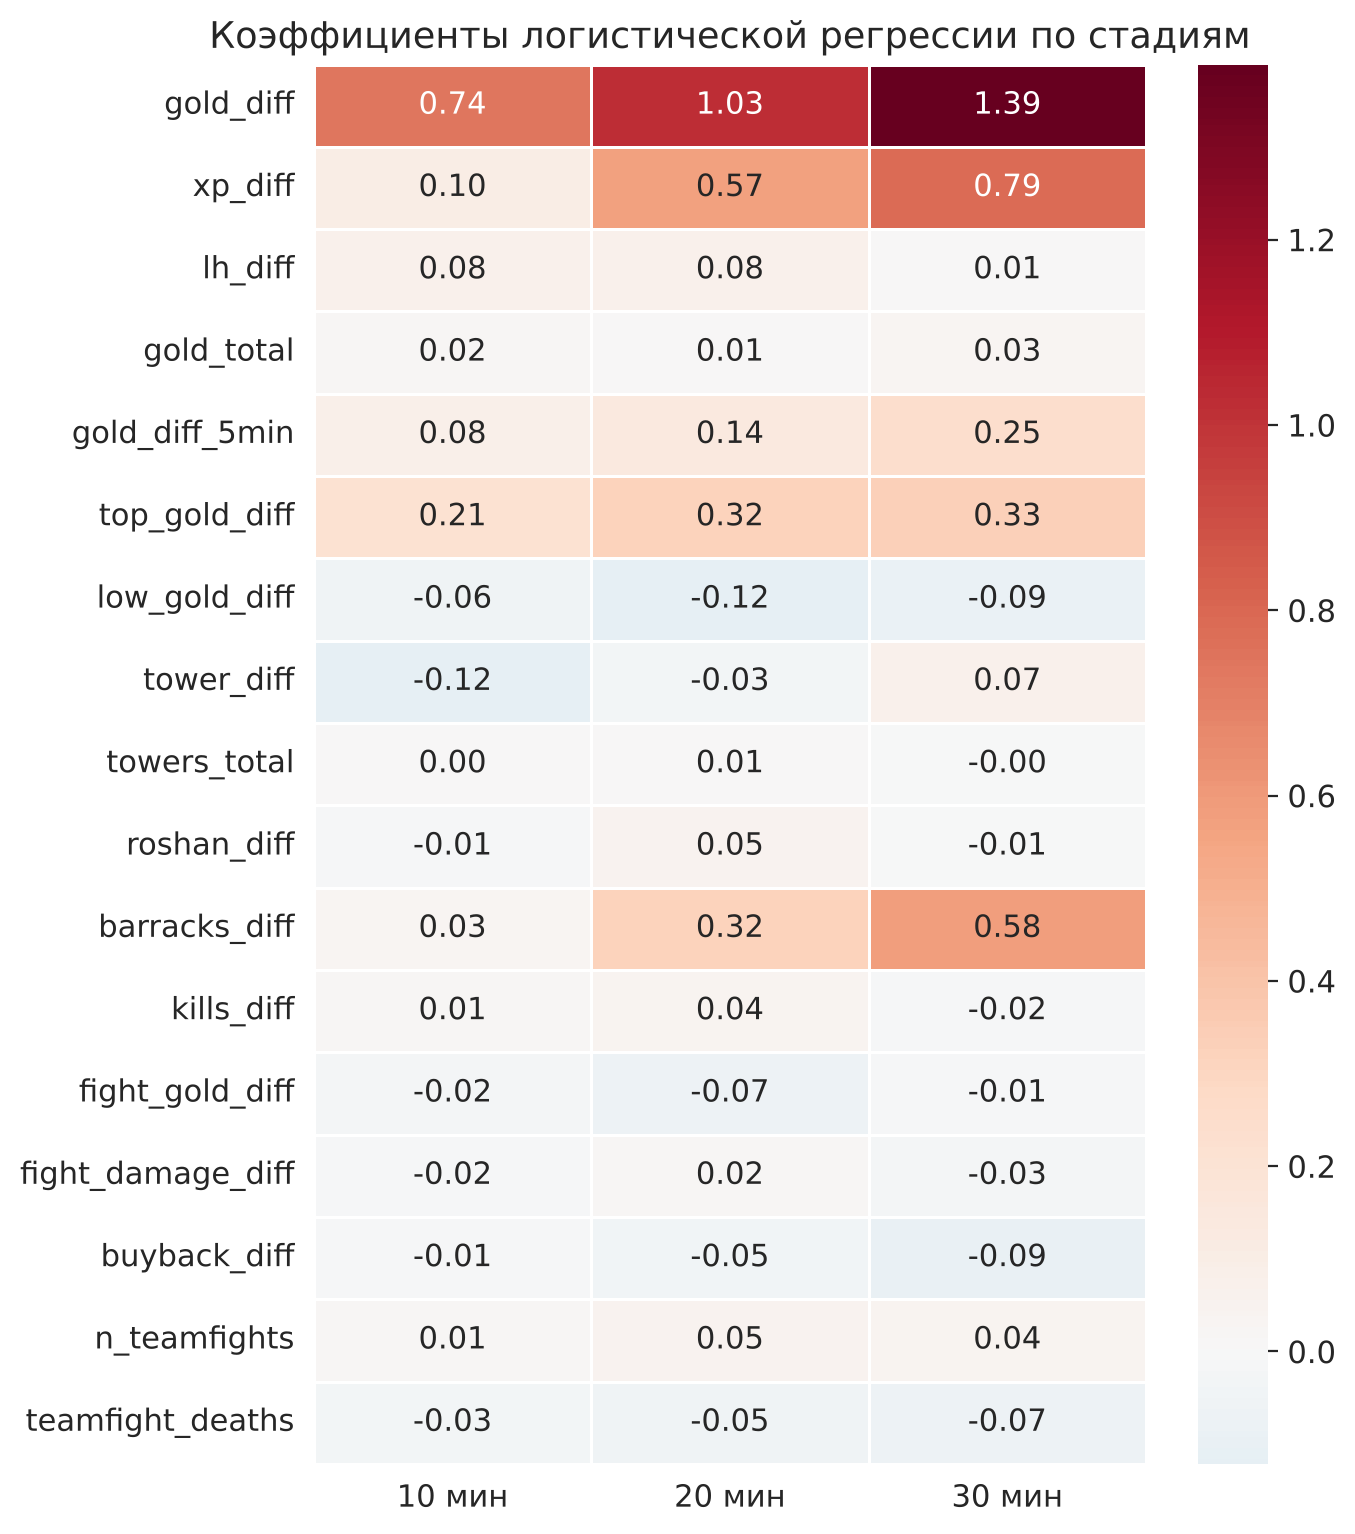

Средний модуль коэффициента при столбце героя: {'10 мин': 0.179, '20 мин': 0.187, '30 мин': 0.184}


In [47]:
# Второй взгляд: коэффициенты логистической регрессии (числовые признаки стандартизованы, их можно сравнивать)
coef_rows = {}
for minute in STAGES:
    model = stage_fitted[(minute, 'Logistic Regression')]
    names = model.named_steps['prep'].get_feature_names_out()
    coef_rows[f'{minute} мин'] = pd.Series(model.named_steps['model'].coef_[0], index=names)
coef_table = pd.DataFrame(coef_rows)
coef_game = coef_table[coef_table.index.str.startswith('num__')].copy()
coef_game.index = [n.replace('num__', '') for n in coef_game.index]

fig, ax = plt.subplots(figsize=(7, 7.8))
sns.heatmap(coef_game, annot=True, fmt='.2f', cmap='RdBu_r', center=0, linewidths=0.5, ax=ax)
ax.set_title('Коэффициенты логистической регрессии по стадиям')
plt.tight_layout()
plt.savefig('figures/logreg_coefs.png', dpi=150, bbox_inches='tight')
plt.show()

hero_coef = coef_table[coef_table.index.str.startswith('hero__')].abs()
print('Средний модуль коэффициента при столбце героя:', hero_coef.mean().round(3).to_dict())

**Какие признаки важны на разных стадиях.**

- **Экономика — главная группа на всех стадиях.** При её перемешивании ROC-AUC бустинга падает на 0,20, 0,31 и 0,34. Но говорить, что её вес «растёт», нельзя: вместе с этим растёт и само качество модели. В долях от запаса над случайным угадыванием (ROC-AUC минус 0,5) это 81%, 90% и 84% — то есть вес экономики примерно постоянен. А в ablation потеря от удаления экономики даже уменьшается (раздел 11.1), потому что к поздним стадиям её всё лучше заменяют убийства и объекты.
- **Драфт важен в начале и теряет вес:** 0,075 → 0,040 → 0,023. В долях от запаса над 0,5 — 30%, 12% и 6%.
- **Объекты набирают вес к поздней стадии:** 0,001 → 0,001 → 0,007. На 30-й минуте главным среди них становится `barracks_diff`; его коэффициент в логистической регрессии растёт с 0,03 до 0,58.
- **Драки и убийства почти ничего не добавляют** (падение около нуля на всех стадиях), хотя сами по себе информативны. Причина — в следующем разделе: их информация уже содержится в золоте и опыте.
- **Внутри экономики:** `gold_diff` главный везде. На 20-й минуте заметный вклад даёт `xp_diff`, на 10-й — `top_gold_diff` (преимущество самого богатого героя).

Оговорка про отдельные признаки: `gold_diff`, `xp_diff`, `tower_diff` и `kills_diff` сильно коррелируют, поэтому делят важность между собой. Например, отрицательный коэффициент при `tower_diff` на 10-й минуте не означает, что башни вредны: это следствие мультиколлинеарности. Надёжнее смотреть на группы.

## 11. Дополнительные исследования

### 11.1 Ablation study: какие группы признаков что дают

Обучаем логистическую регрессию на разных наборах признаков и смотрим на 5-fold CV ROC-AUC. Так видно, что даёт каждая группа сама по себе и что теряется, если её убрать.

In [48]:
feature_sets = {
    'Только gold_diff': ['gold_diff'],
    'Только экономика': groups['Экономика'],
    'Только объекты': groups['Объекты'],
    'Только драки и убийства': groups['Драки и убийства'],
    'Только драфт': hero_features,
    'Все без драфта': game_features,
    'Все без экономики': [c for c in features if c not in groups['Экономика']],
    'Все без объектов': [c for c in features if c not in groups['Объекты']],
    'Все без драк и убийств': [c for c in features if c not in groups['Драки и убийства']],
    'Все признаки': features,
}

ablation_rows = []
for minute in STAGES:
    X_tr, y_tr, X_te, y_te = get_split(minute)
    for set_name, cols in feature_sets.items():
        pipe = make_pipe(LogisticRegression(C=C_best, max_iter=2000), cols=cols)
        scores = cross_val_score(pipe, X_tr[cols], y_tr, cv=cv, scoring='roc_auc', n_jobs=-1)
        ablation_rows.append({'Набор признаков': set_name, 'Минута': minute, 'CV ROC-AUC': scores.mean(), 'std': scores.std()})

ablation = pd.DataFrame(ablation_rows)
ablation.to_csv('results/ablation.csv', index=False)
ablation_table = ablation.pivot(index='Набор признаков', columns='Минута', values='CV ROC-AUC').loc[list(feature_sets)]
ablation_table.round(4)

Минута,10,20,30
Набор признаков,,,
Только gold_diff,0.7027,0.8117,0.8832
Только экономика,0.7089,0.8211,0.8890
Только объекты,0.5868,0.7383,0.8317
Только драки и убийства,0.5840,0.7194,0.7966
Только драфт,0.6402,0.6401,0.6316
Все без драфта,0.7098,0.8215,0.8912
Все без экономики,0.6862,0.8064,0.8782
Все без объектов,0.7594,0.8507,0.9059
Все без драк и убийств,0.7603,0.8509,0.9066


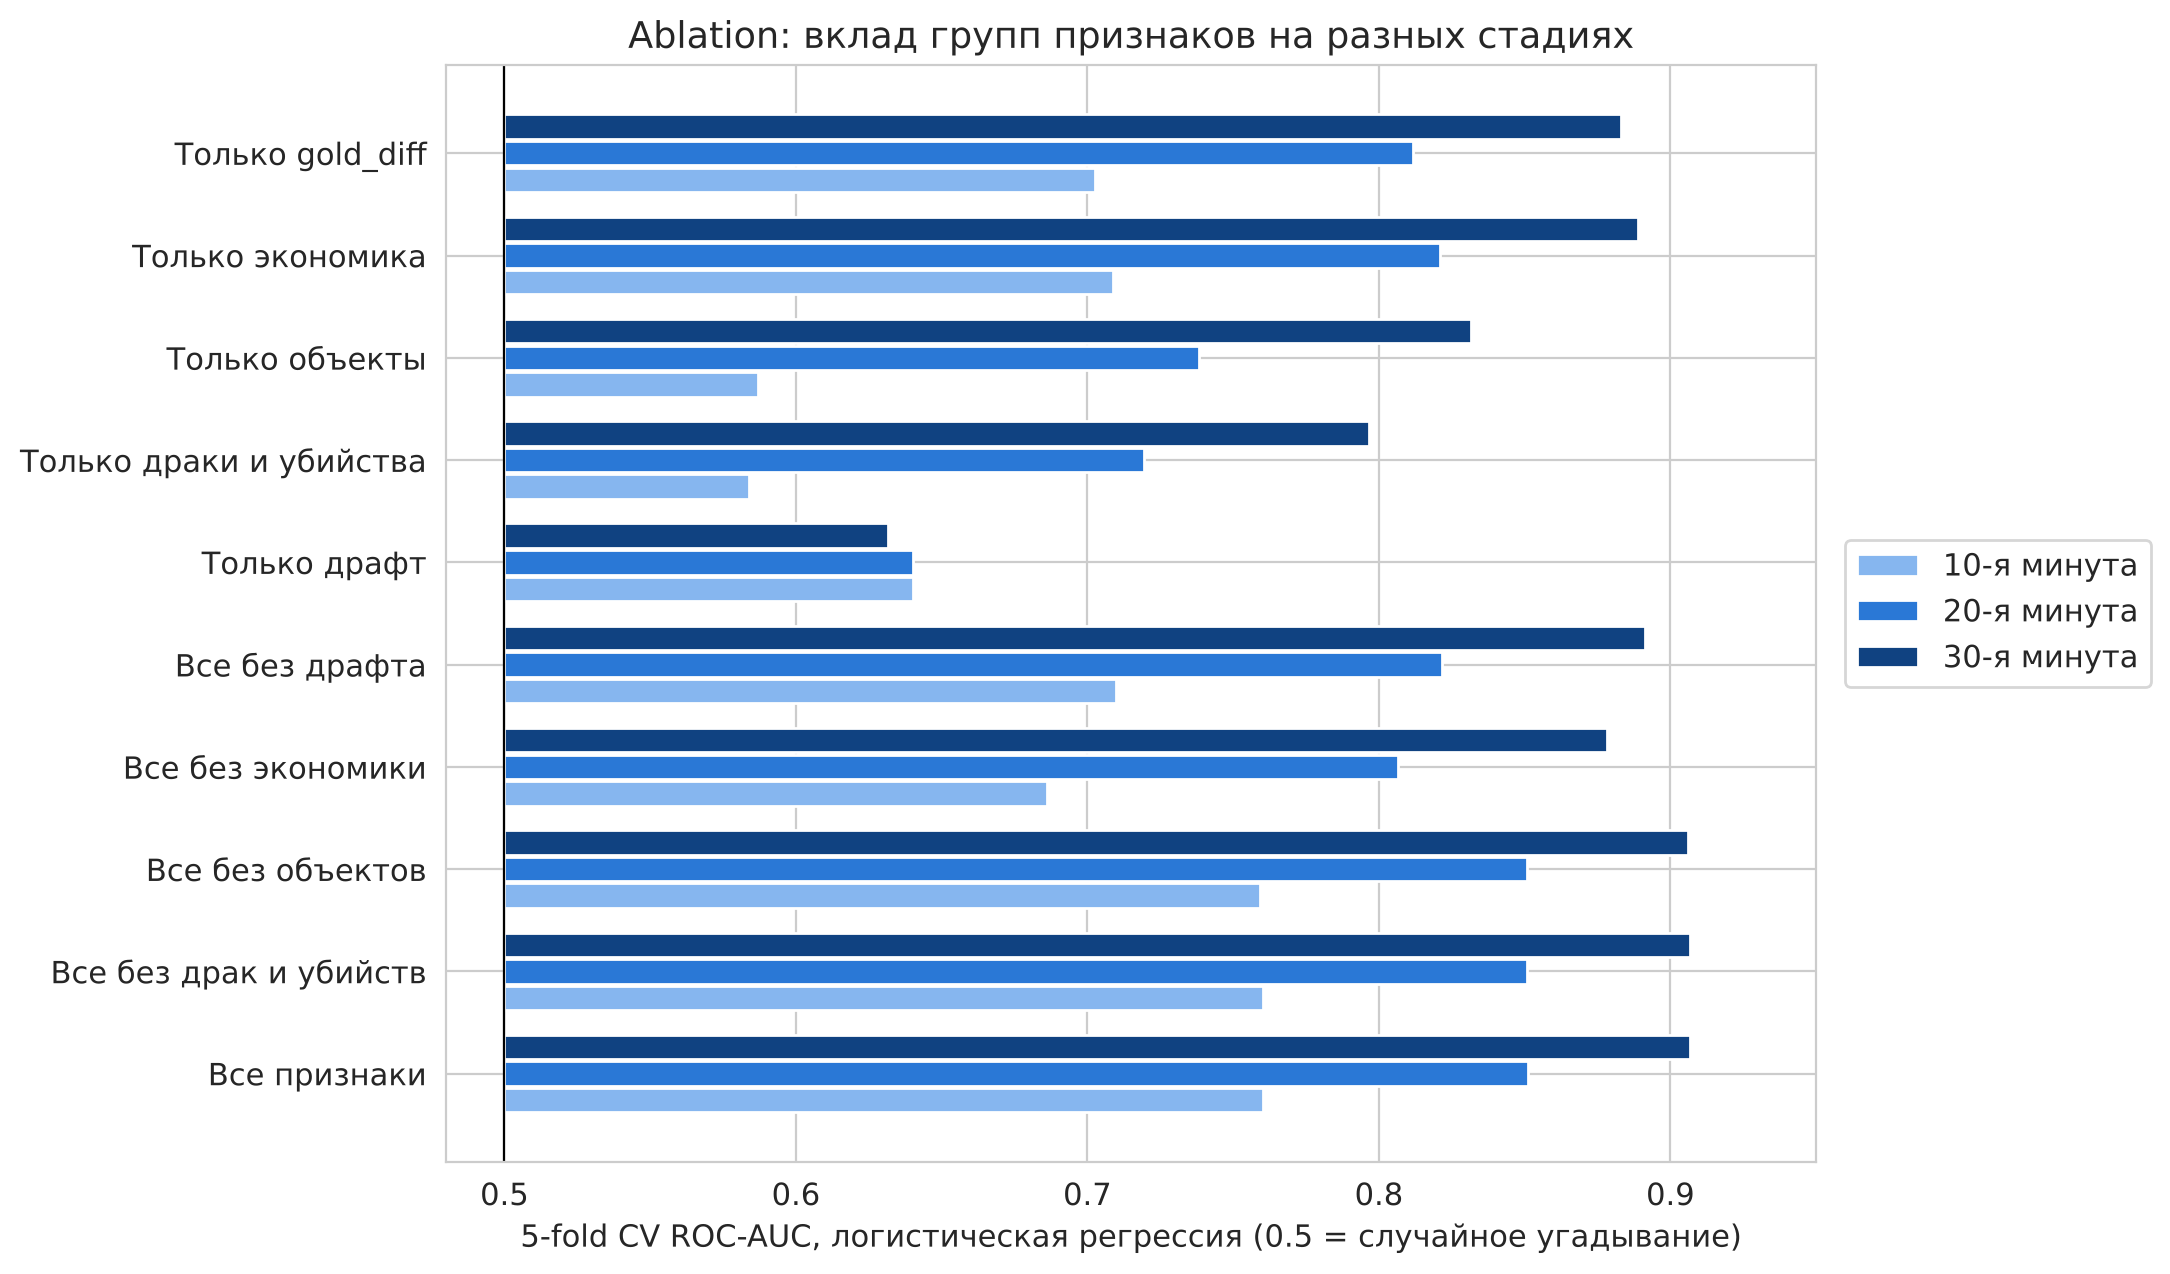

In [49]:
fig, ax = plt.subplots(figsize=(11, 6.5))
order = list(feature_sets)[::-1]
height = 0.26
for i, minute in enumerate(STAGES):
    ax.barh(np.arange(len(order)) + (i - 1) * height, ablation_table.loc[order, minute] - 0.5, left=0.5,
            height=height * 0.92, color=STAGE_COLORS[minute], label=f'{minute}-я минута')
ax.axvline(0.5, color='black', linewidth=0.8)
ax.set_yticks(np.arange(len(order)))
ax.set_yticklabels(order)
ax.set_xlim(0.48, 0.95)
ax.set_xlabel('5-fold CV ROC-AUC, логистическая регрессия (0.5 = случайное угадывание)')
ax.set_title('Ablation: вклад групп признаков на разных стадиях')
ax.legend(loc='center left', bbox_to_anchor=(1.01, 0.5))
plt.tight_layout()
plt.savefig('figures/ablation.png', dpi=150, bbox_inches='tight')
plt.show()

**Выводы из ablation** (все числа — 5-fold CV ROC-AUC логистической регрессии).

- **Экономика незаменима, но к поздним стадиям её всё лучше заменяют другие группы.** Потеря от её удаления из полного набора: 0,074 на 10-й минуте (0,760 → 0,686), 0,045 на 20-й и 0,029 на 30-й (0,907 → 0,878).
- **Убийства в драках и объекты дублируют экономику.** Сами по себе они дают много: драки и убийства — 0,584 → 0,719 → 0,797, объекты — 0,587 → 0,738 → 0,832. Но если убрать любую из этих групп из полного набора, качество не меняется (0,8510 → 0,8509 без драк и убийств, 0,8510 → 0,8507 без объектов). За убийства и башни команда получает золото и опыт, поэтому эта информация уже есть в `gold_diff` и `xp_diff`.
- **Драфт — единственная группа с независимой информацией.** Без него модель теряет 0,05 на 10-й минуте, 0,03 на 20-й и 0,02 на 30-й.
- **Одного `gold_diff` хватает на бо́льшую часть качества:** 0,812 из 0,851 на 20-й минуте. Остальные экономические признаки добавляют около 0,01.

**Что это значит для KDA и чего это не значит.** Проверено одно: разница убийств в командных драках ничего не добавляет к золоту и опыту. Про полный KDA такого вывода сделать нельзя — его по минутам в датасете нет: драки покрывают 60,7% смертей за матч (а к 10-й минуте заметно меньше), ассистов по времени нет совсем.

### 11.2 Анализ ошибок

Разбираем ошибки лучшей одиночной модели на 20-й минуте: где именно она ошибается и можно ли доверять её вероятностям.

Модель для анализа: Logistic Regression


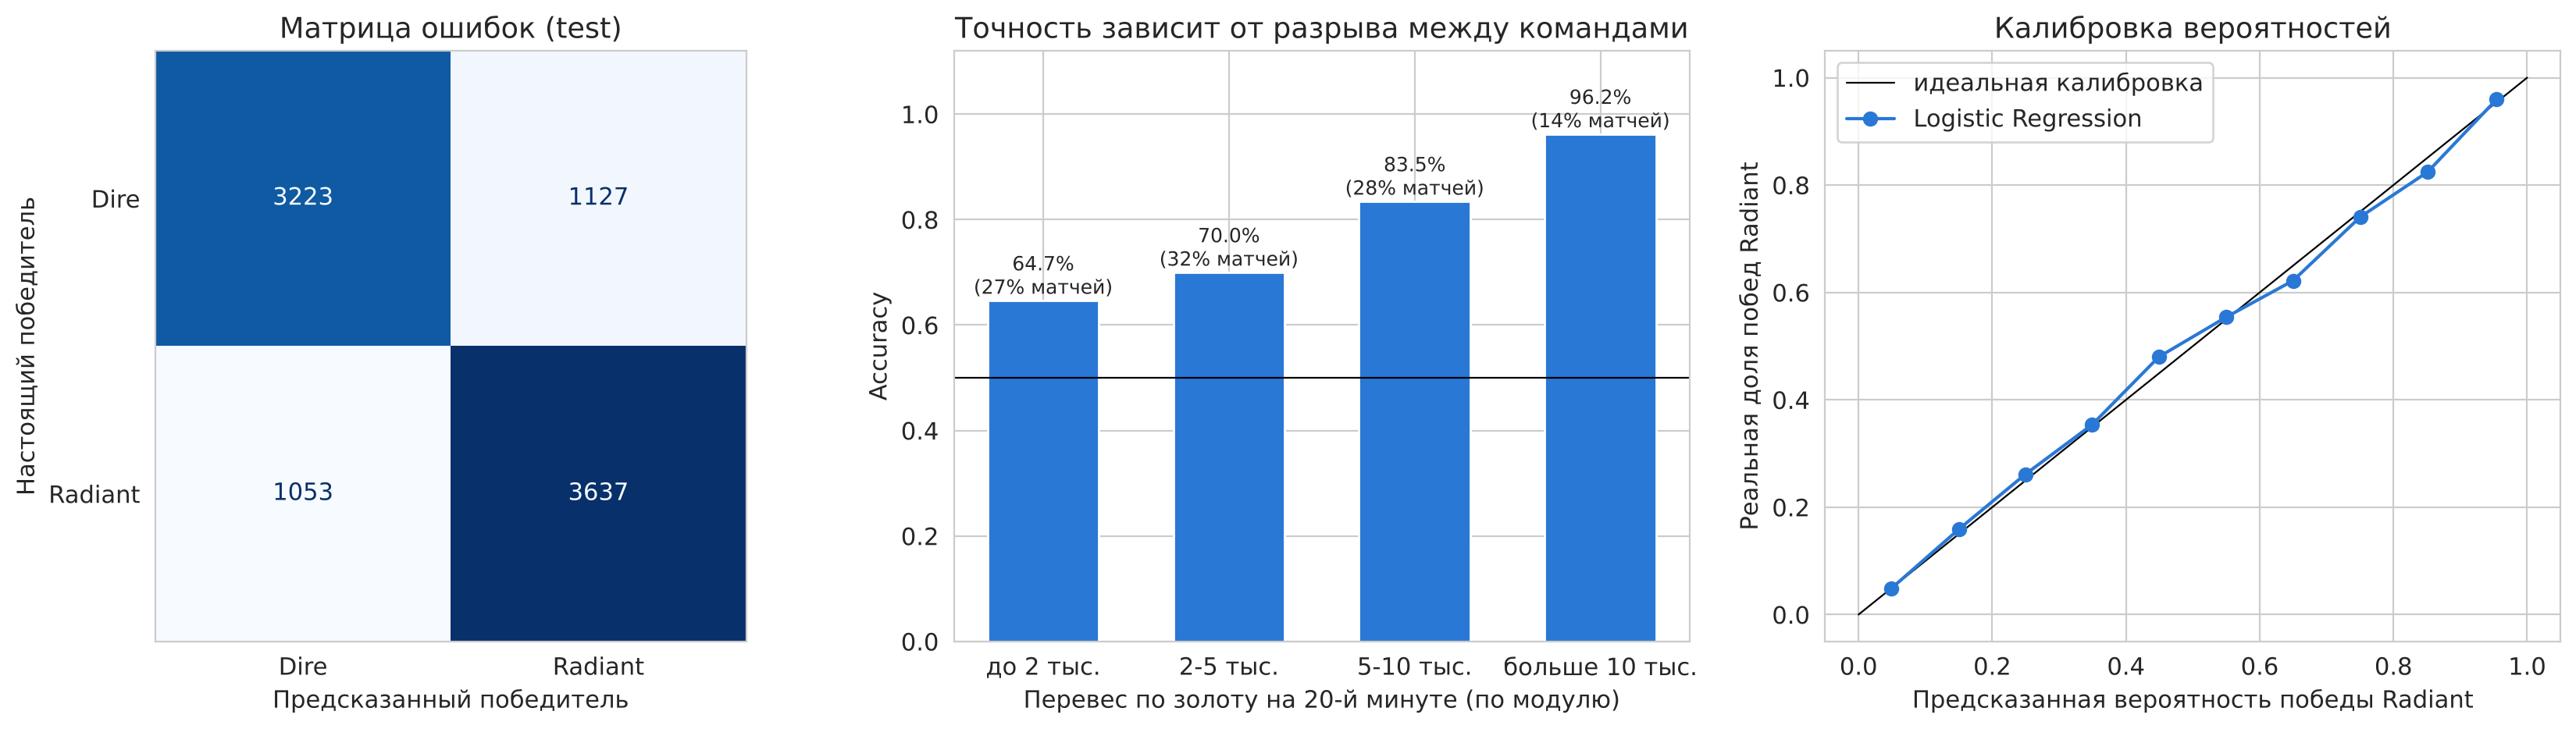

,матчей,accuracy,доля матчей,ошибок,доля всех ошибок
lead,,,,,
до 2 тыс.,2412,0.647,0.267,852,0.391
2-5 тыс.,2891,0.700,0.320,867,0.398
5-10 тыс.,2511,0.835,0.278,415,0.190
больше 10 тыс.,1226,0.962,0.136,46,0.021


In [50]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.calibration import calibration_curve

single = comparison.loc[['Logistic Regression', 'Decision Tree', 'Random Forest', 'Gradient Boosting', 'MLP (PyTorch)']]
best_name = single['CV ROC-AUC'].idxmax()        # выбираем по кросс-валидации, а не по тесту
proba = test_proba[best_name]
pred = (proba >= 0.5).astype(int)
print('Модель для анализа:', best_name)

err = stages[MAIN_STAGE][stages[MAIN_STAGE]['match_id'].isin(test_ids)].copy()
err['proba'] = proba
err['correct'] = (pred == err[target].values)
err['lead'] = pd.cut(err['gold_diff'].abs(), bins=[-1, 2000, 5000, 10000, 100000],
                     labels=['до 2 тыс.', '2-5 тыс.', '5-10 тыс.', 'больше 10 тыс.'])
by_lead = err.groupby('lead', observed=True).agg(матчей=('correct', 'size'), accuracy=('correct', 'mean'))
by_lead['доля матчей'] = by_lead['матчей'] / len(err)
by_lead['ошибок'] = err[~err['correct']].groupby('lead', observed=True).size()
by_lead['доля всех ошибок'] = by_lead['ошибок'] / by_lead['ошибок'].sum()
by_lead.to_csv('results/error_by_lead.csv')

fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
ConfusionMatrixDisplay(confusion_matrix(y_test, pred), display_labels=['Dire', 'Radiant']).plot(ax=axes[0], cmap='Blues', colorbar=False)
axes[0].set_title('Матрица ошибок (test)')
axes[0].set_xlabel('Предсказанный победитель')
axes[0].set_ylabel('Настоящий победитель')
axes[0].grid(False)

bars = axes[1].bar(by_lead.index.astype(str), by_lead['accuracy'], color=C_MAIN, width=0.6)
for b, (acc, share) in zip(bars, zip(by_lead['accuracy'], by_lead['доля матчей'])):
    axes[1].text(b.get_x() + b.get_width() / 2, acc, f'{acc:.1%}\n({share:.0%} матчей)', ha='center', va='bottom', fontsize=9)
axes[1].axhline(0.5, color='black', linewidth=0.8)
axes[1].set_ylim(0, 1.12)
axes[1].set_xlabel('Перевес по золоту на 20-й минуте (по модулю)')
axes[1].set_ylabel('Accuracy')
axes[1].set_title('Точность зависит от разрыва между командами')

prob_true, prob_pred = calibration_curve(y_test, proba, n_bins=10)
axes[2].plot([0, 1], [0, 1], color='black', linewidth=0.8, label='идеальная калибровка')
axes[2].plot(prob_pred, prob_true, marker='o', color=C_MAIN, label=best_name)
axes[2].set_xlabel('Предсказанная вероятность победы Radiant')
axes[2].set_ylabel('Реальная доля побед Radiant')
axes[2].set_title('Калибровка вероятностей')
axes[2].legend()
plt.tight_layout()
plt.savefig('figures/error_analysis.png', dpi=150, bbox_inches='tight')
plt.show()

by_lead.round(3)

In [51]:
# "Камбэки": модель была уверена (вероятность > 0.8 или < 0.2), но ошиблась
confident = err[(err['proba'] > 0.8) | (err['proba'] < 0.2)]
wrong = confident[~confident['correct']]
right = confident[confident['correct']]
print(f'Уверенных прогнозов: {len(confident)} ({len(confident) / len(err):.1%} теста), из них ошибочных: {len(wrong)} ({len(wrong) / len(confident):.1%})')
print(f'Средняя длительность матча: уверенный и верный прогноз - {right["duration"].mean() / 60:.1f} мин, '
      f'уверенный и ошибочный - {wrong["duration"].mean() / 60:.1f} мин')
print(f'Средний |gold_diff|: верные - {right["gold_diff"].abs().mean():.0f}, ошибочные - {wrong["gold_diff"].abs().mean():.0f}')

Уверенных прогнозов: 4177 (46.2% теста), из них ошибочных: 419 (10.0%)
Средняя длительность матча: уверенный и верный прогноз - 36.3 мин, уверенный и ошибочный - 50.2 мин
Средний |gold_diff|: верные - 8396, ошибочные - 5717


**Выводы из анализа ошибок.**

- **Ошибки сосредоточены в равных матчах.** На матчи с разрывом до 2 тыс. золота приходится 39% всех ошибок, до 5 тыс. — 79%. Accuracy при разрыве до 2 тыс. — 64,7%, при разрыве больше 10 тыс. — 96,2%.
- **Вероятностям можно доверять.** Калибровочная кривая лежит на диагонали: если модель говорит «70%», Radiant действительно побеждает примерно в 70% таких матчей.
- **Уверенные прогнозы ошибаются в 10,0% случаев.** Такие матчи длятся в среднем 50 минут против 36 у верно предсказанных: команда, проигрывавшая на 20-й минуте, затянула игру и переломила её.
- Матрица ошибок почти симметрична: модель не «болеет» ни за одну из сторон.

### 11.3 Демонстрация утечки: что будет, если взять итоговую статистику

В `players.csv` лежат показатели на **конец** матча. Проверим, какое качество даёт модель на трёх таких признаках.

In [52]:
final = players.copy()
final['side'] = np.where(final['player_slot'] < 5, 'r', 'd')
agg = final.groupby(['match_id', 'side'])[['kills', 'gold_per_min', 'xp_per_min']].sum().unstack('side')
leak = pd.DataFrame({'kills_diff_final': agg[('kills', 'r')] - agg[('kills', 'd')],
                     'gpm_diff_final': agg[('gold_per_min', 'r')] - agg[('gold_per_min', 'd')],
                     'xpm_diff_final': agg[('xp_per_min', 'r')] - agg[('xp_per_min', 'd')]})
leak = leak.join(match_clean.set_index('match_id')[target], how='inner').reset_index()
leak_cols = ['kills_diff_final', 'gpm_diff_final', 'xpm_diff_final']
leak_train, leak_test = leak[leak['match_id'].isin(train_ids)], leak[leak['match_id'].isin(test_ids)]

leak_model = Pipeline([('scaler', StandardScaler()), ('model', LogisticRegression(max_iter=1000))])
leak_model.fit(leak_train[leak_cols], leak_train[target])
leak_proba = leak_model.predict_proba(leak_test[leak_cols])[:, 1]
print(f'Итоговая статистика: test ROC-AUC = {roc_auc_score(leak_test[target], leak_proba):.4f}, '
      f'accuracy = {accuracy_score(leak_test[target], leak_proba >= 0.5):.4f}')
print(f'Честная модель на 30-й минуте: test ROC-AUC = {stage_auc.loc["Logistic Regression", 30]:.4f}')

Итоговая статистика: test ROC-AUC = 0.9989, accuracy = 0.9847
Честная модель на 30-й минуте: test ROC-AUC = 0.9056


**Вывод.** На трёх признаках из итоговой статистики модель получает ROC-AUC 0,999 и accuracy 98,5%. Это не «очень хорошая модель», а утечка данных: итоговые убийства и золото — следствие победы, а не её причина, и до конца матча они неизвестны. Честный прогноз на 30-й минуте даёт 0,906. Поэтому в проекте признаки, включая убийства, считаются строго по событиям до выбранной минуты.

### 11.4 Проверка ограничения: матчи с вышедшими игроками

В разделе 2.2 мы убрали матчи, где игрок покинул игру. Проверим, как модель, обученная на «чистых» матчах, работает на убранных. Эти матчи не участвовали ни в обучении, ни в тесте.

In [53]:
leaver_ids = leaver_max[leaver_max >= 2].index
match_leavers = match[match['match_id'].isin(leaver_ids)].copy()
match_leavers['radiant_win'] = match_leavers['radiant_win'].astype(int)

leaver_rows = []
for minute in STAGES:
    table = add_draft(build_stage(minute, matches=match_leavers))
    model = stage_fitted[(minute, 'Logistic Regression')]
    proba = model.predict_proba(table[features])[:, 1]
    leaver_rows.append({'Минута': minute, 'Матчей с выходами': len(table),
                        'ROC-AUC на матчах с выходами': roc_auc_score(table[target], proba),
                        'ROC-AUC на обычном тесте': stage_auc.loc['Logistic Regression', minute],
                        'Accuracy на матчах с выходами': accuracy_score(table[target], proba >= 0.5),
                        'Accuracy на обычном тесте': stage_acc.loc['Logistic Regression', minute]})
leaver_table = pd.DataFrame(leaver_rows).set_index('Минута')
leaver_table.to_csv('results/leaver_matches.csv')
leaver_table.round(4)

,Матчей с выходами,ROC-AUC на матчах с выходами,ROC-AUC на обычном тесте,Accuracy на матчах с выходами,Accuracy на обычном тесте
Минута,,,,,
10,4575,0.7658,0.7547,0.6916,0.6902
20,4370,0.8464,0.8466,0.7568,0.7588
30,3555,0.8799,0.9056,0.7845,0.8169


**Результат проверки.** На матчах с вышедшими игроками модель на 10-й и 20-й минуте работает не хуже, чем на обычном тесте: ROC-AUC 0,766 против 0,755 и 0,846 против 0,847. На 30-й минуте качество ниже: 0,880 против 0,906, accuracy 78,5% против 81,7%.

То есть ожидание «на таких матчах модель будет хуже» подтвердилось только для поздней стадии. Вероятное объяснение (не проверялось): чем позже минута, тем чаще выход игрока уже произошёл и успел изменить ход игры, а модель об этом не знает.

Оговорка: эти матчи не участвовали в обучении, но это другая выборка, и сравнение с тестом показывает перенос модели, а не точную оценку.

## 12. Выводы

**1. Исход матча предсказуем, и чем позже, тем лучше.** Test ROC-AUC логистической регрессии: 0,755 на 10-й минуте, 0,847 на 20-й, 0,906 на 30-й (accuracy 69,0%, 75,9%, 81,7%). До начала игры по одному драфту — 0,638. Часть роста объясняется отбором: к 30-й минуте в выборке остаются только матчи, которые ещё идут.

**2. Какие признаки предсказательны на разных стадиях.**
- Экономика (перевес по золоту и опыту) — главная группа на всех стадиях.
- Драфт заметен в начале игры и теряет вес: на 10-й минуте он добавляет 0,05 к CV ROC-AUC, на 30-й — 0,02.
- Объекты (башни, бараки, Рошан) и убийства в командных драках сами по себе информативны и набирают силу к 20–30-й минуте, но почти не добавляют нового к экономике: за них команда получает золото и опыт.

**3. Простая модель не хуже сложных.** Логистическая регрессия (0,8466), MLP (0,8460), stacking (0,8470) и blending (0,8457) неразличимы в пределах разброса по фолдам, и это верно на всех трёх стадиях. Зависимость от перевеса по золоту монотонна, и нелинейные модели не нашли ничего сверх того, что видит линейная. Деревья справляются хуже (Random Forest 0,8320, одно дерево 0,8188).

**4. Драфт дал больше, чем выбор между сильными моделями.** Добавление драфта подняло test ROC-AUC с 0,8239 до 0,8466 (+0,023), а разница между сильными моделями — 0,004. Сконструированные игровые признаки дали меньше: +0,009 к одному `gold_diff` (0,8146 → 0,8239). При этом выбор между линейной моделью и деревом важнее драфта: разница 0,028.

**5. Регуляризация MLP нужна для устойчивости.** Без неё сеть переобучается после 5-й эпохи. С Dropout и weight decay val loss выходит на плато, и результат не зависит от точки остановки.

**6. Ошибки сосредоточены в равных матчах.** 79% ошибок приходится на матчи с разрывом до 5 тыс. золота на 20-й минуте. Вероятности модели хорошо откалиброваны, так что ей можно доверять как оценке шансов.

**Ограничения.**
- Данные — публичные рейтинговые матчи за две недели ноября 2015 года. Баланс героев с тех пор менялся много раз; для современных матчей модель нужно переобучать.
- Убраны матчи, где игрок покинул игру (9,3%), причём по статусу на конец матча. Все метрики относятся к матчам без выходов. Проверка в разделе 11.4: на убранных матчах качество такое же на 10-й и 20-й минуте и ниже на 30-й (0,880 против 0,906).
- Стадии сравниваются на разных наборах матчей: до 30-й минуты доживают не все.
- Гиперпараметры подбирались на 20-й минуте и переносились на остальные стадии.
- Random Forest перебран по 12 конфигурациям из 96.
- **KDA использован не полностью.** Убийства и смерти по минутам взяты из командных драк, которые покрывают 60,7% смертей героев за матч и заметно меньше в начале игры. Ассистов по минутам в датасете нет. Полный KDA есть только итоговый — он показан в EDA и в демонстрации утечки.

**Что можно улучшить.** Добавить `purchase_log.csv` (купленные предметы) и обучить одну модель на всех минутах сразу с минутой в качестве признака.